# LungCT — Phân loại ảnh CT phổi

Huấn luyện và đánh giá bốn mô hình phân loại ảnh CT phổi (Benign, Malignant, Normal) trên bộ IQ-OTH/NCCD: CNN, ViT Head, CNN–ViT và **AACNN–ViT Adaptive** (mô hình chính). Kết quả là phân loại từng lát cắt, không phải chẩn đoán lâm sàng.

**Cách chạy** (đặt `CHE_DO` ở mục 2, rồi *Thời gian chạy → Chạy tất cả*):
- `CHE_DO = "huan_luyen"`: chạy toàn bộ quy trình
- `CHE_DO = "thu_anh"`: không huấn luyện; nạp mô hình đã lưu để thử ảnh ở mục 20 và 28. Chạy được trên CPU.

| Mục | Nội dung |
|---|---|
| 1–5 | Môi trường, cấu hình, kiểm tra ảnh, chia tập, tăng cường dữ liệu |
| 6–10 | Đặc trưng ViT, bộ nạp, kiến trúc, loss, kiểm tra kỹ thuật |
| 11–22 | Huấn luyện, đánh giá validation/test, Grad-CAM, đóng gói, thử ảnh, bảng chỉ số |
| 23–30 | Phần bổ sung: vùng nghi ngờ, phân tích huấn luyện, mất cân bằng, lung crop, gợi ý viết khóa luận |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Môi trường
Kết nối Google Drive và nạp thư viện. TensorFlow dùng cho CNN/fusion, PyTorch dùng cho ViT.

In [2]:
import importlib.util, subprocess, sys
for package in ("transformers", "huggingface_hub", "sklearn", "PIL", "ipywidgets"):
    if importlib.util.find_spec(package) is None:
        pip_name = {"sklearn": "scikit-learn", "PIL": "Pillow"}.get(package, package)
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name])

In [3]:
import os
os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")
import gc, csv, json, math, time, random, hashlib, platform, subprocess
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import tensorflow as tf
# Giới hạn TF cấp phát dần để giảm tranh chấp VRAM với PyTorch.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print("Chưa đổi được memory growth:", error)
import torch, transformers
from transformers import ViTImageProcessor, ViTModel
from huggingface_hub import model_info
from tensorflow.keras import layers, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             accuracy_score, roc_curve, auc)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Chạy ngoài Colab: dùng đường dẫn cục bộ ở cấu hình.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Cấu hình
Mọi tham số nằm ở một cell: đường dẫn, thứ tự nhãn, kích thước ảnh, số epoch, tăng cường dữ liệu và `CHE_DO`. Mỗi lần chạy tạo một thư mục run riêng, không ghi đè kết quả cũ.

In [4]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
# ===== Chế độ chạy =====
CHE_DO = "huan_luyen"           # "huan_luyen": chạy toàn bộ | "thu_anh": chỉ nạp mô hình đã lưu để thử ảnh (mục 20, 28)
RUN_DA_TRAIN = None             # chế độ "thu_anh": None = run mới nhất có mô hình; hoặc Path(".../<RUN_ID>_EXPERIMENT")
NUT_THU_DUNG_LUNG_CROP = True   # nút mục 28 dùng mô hình lung crop (nếu đã có) thay cho mô hình chính

BASE_DIR = Path("/content/drive/MyDrive/KLTN2627_DeTai2_V2/Dataset/IQ_OTHNCCD")
OUTPUT_ROOT = Path("/content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem")
CACHE_ROOT = OUTPUT_ROOT / "vit_cache_v2"
CLASS_NAMES = ["Benign", "Malignant", "Normal"]
# Chỉ lấy ảnh gốc (tên "Bengin case (n)", "Malignant case (n)", "Normal case (n)").
CHI_LAY_ANH_GOC = True
SEED = 42
IMG_SIZE = (512, 512)
VIT_SIZE = (224, 224)
BATCH_SIZE = 8
VIT_BATCH_SIZE = 8
VIT_MODEL_ID = "google/vit-base-patch16-224-in21k"
VIT_REVISION = "main"  # Được resolve thành commit cố định trước trích feature.
SPLIT_MODE = "holdout"  # Cố định 70% train / 15% validation / 15% test.
SMOKE_TEST = False
MODELS_TO_RUN = ["CNN", "ViT_Head", "CNN_ViT", "AACNN_Adaptive"]
EPOCHS_BASELINE = 30                    # 3 mô hình đối chứng: 30 epoch, không dừng sớm
EPOCHS_STAGE_A, EPOCHS_STAGE_B = 15, 25  # Adaptive: tổng 40 epoch = 15 stage A (đóng băng ResNet) + 25 stage B
EARLY_STOP_PATIENCE = None              # None = không dừng sớm; luôn chạy đủ, vẫn giữ checkpoint best validation
UNFREEZE_LAST_N = 60
FREEZE_BATCHNORM = True  # Thay đổi train policy: ổn định thống kê với batch nhỏ.
CNN_AUGMENT = False  # Dùng augmentation offline đồng bộ cho cả CNN và ViT.
FUSION_AUGMENT = False  # ViT cache từ ảnh gốc, tránh lệch hai nhánh ở mặc định.
# Tăng cường dữ liệu train (mục 5): cân bằng lớp, mỗi ảnh sinh thêm dùng 1 kỹ thuật
AUG_HE_SO_DICH = 2                      # ảnh đích mỗi lớp = 2 × số ảnh của lớp train đông nhất
AUG_TY_LE = {"xoay": 0.30, "do_sang": 0.30, "tuong_phan": 0.30, "gaussian_blur": 0.10}
AUG_GOC_XOAY = (-8.0, 8.0)              # độ
AUG_DO_SANG = (0.95, 1.05)
AUG_TUONG_PHAN = (0.95, 1.05)
AUG_BLUR_SIGMA = (0.3, 0.7)             # pixel, kernel 3×3, tính trên ảnh 512×512
LIGHT_MAX_MACRO_F1_DROP = 0.01  # Ngưỡng kỹ thuật đề xuất, chỉ đánh giá trên validation.
LIGHT_MIN_LABEL_AGREEMENT = 0.98
MIXUP_ALPHA = 0.0  # Không triển khai MixUp trong bản quy trình này.
RUN_TEST_ONCE = True  # Run chính thức đánh giá test một lần sau khi huấn luyện.
PREPROCESS_VERSION = "rgb-nearest-source-resize-v1"

random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
try: tf.config.experimental.enable_op_determinism()
except AttributeError: pass
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = OUTPUT_ROOT / (RUN_ID + ("_THU_ANH" if CHE_DO == "thu_anh" else "_SMOKE" if SMOKE_TEST else "_EXPERIMENT"))
RUN_DIR.mkdir(parents=True, exist_ok=False)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
NUM_CLASSES = len(CLASS_NAMES)
assert SPLIT_MODE == "holdout", "Nghiên cứu này cố định chia 70/15/15."
assert MIXUP_ALPHA == 0, "MixUp chưa triển khai; không thay cấu hình rồi giả định đã hoạt động."
assert CHE_DO in ("huan_luyen", "thu_anh"), "CHE_DO chỉ nhận 'huan_luyen' hoặc 'thu_anh'."

# Chế độ "thu_anh": các cell không có dòng [THU_ANH] tự bỏ qua khi "Chạy tất cả".
_ip = get_ipython()
_ip.input_transformers_post[:] = [f for f in _ip.input_transformers_post
                                  if getattr(f, "__name__", "") != "_loc_che_do_thu_anh"]
if CHE_DO == "thu_anh":
    def _loc_che_do_thu_anh(lines):
        if any("[THU_ANH]" in line for line in lines):
            return lines
        return ['print("Bỏ qua (CHE_DO = \'thu_anh\').")\n']
    _ip.input_transformers_post.append(_loc_che_do_thu_anh)
print("Chế độ:", CHE_DO, "| Thư mục kết quả:", RUN_DIR)

Chế độ: huan_luyen | Thư mục kết quả: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/20261122T082142_409115Z_EXPERIMENT


In [5]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
def write_json(path, value):
    """Ghi JSON có Unicode; dùng cho cấu hình và kết quả có thể đối chiếu."""
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False,
                                   default=str, allow_nan=False), encoding="utf-8")

def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()

def sha256_file(path):
    """Hash theo chunk để không nạp cả checkpoint lớn vào RAM."""
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""): h.update(chunk)
    return h.hexdigest()

CONFIG_KEYS = ["CLASS_NAMES", "SEED", "IMG_SIZE", "VIT_SIZE", "BATCH_SIZE",
              "VIT_MODEL_ID", "VIT_REVISION", "SPLIT_MODE", "SMOKE_TEST", "MODELS_TO_RUN",
              "EPOCHS_BASELINE", "EPOCHS_STAGE_A", "EPOCHS_STAGE_B", "EARLY_STOP_PATIENCE", "UNFREEZE_LAST_N",
              "FREEZE_BATCHNORM", "CNN_AUGMENT", "FUSION_AUGMENT", "MIXUP_ALPHA",
              "PREPROCESS_VERSION", "CHI_LAY_ANH_GOC", "AUG_HE_SO_DICH", "AUG_TY_LE", "AUG_GOC_XOAY",
              "AUG_DO_SANG", "AUG_TUONG_PHAN", "AUG_BLUR_SIGMA", "LIGHT_MAX_MACRO_F1_DROP", "LIGHT_MIN_LABEL_AGREEMENT"]
CONFIG = {k: globals()[k] for k in CONFIG_KEYS}
write_json(RUN_DIR / "config.json", CONFIG)
ENVIRONMENT = {"python": sys.version, "platform": platform.platform(),
               "tensorflow": tf.__version__, "torch": torch.__version__,
               "transformers": transformers.__version__,
               "tf_gpus": [x.name for x in tf.config.list_physical_devices("GPU")],
               "torch_gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
write_json(RUN_DIR / "environment.json", ENVIRONMENT)
(RUN_DIR / "pip-freeze.txt").write_text(subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
print(ENVIRONMENT)

{'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'tensorflow': '2.21.0', 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'tf_gpus': ['/physical_device:GPU:0'], 'torch_gpu': 'NVIDIA A100-SXM4-40GB'}


## 3. Kiểm tra ảnh và loại trùng
Chỉ lấy 1.097 ảnh gốc, loại ảnh trùng hệt nhau (theo hash pixel) trước khi chia tập. Đầu ra: `dataset_inventory.json`, `duplicates.json`.

In [6]:
def rgb_image(path):
    """Đọc ảnh thành RGB; không tự xoay/crop."""
    with Image.open(path) as im:
        return im.convert("RGB").copy()

TEN_THU_MUC_LOP = {"Benign": ["Benign", "Benign cases", "Bengin cases"],
                   "Malignant": ["Malignant", "Malignant cases"],
                   "Normal": ["Normal", "Normal cases"]}
TIEN_TO_ANH_GOC = {"Benign": ("bengin case", "benign case"), "Malignant": ("malignant case",),
                   "Normal": ("normal case",)}


def tim_thu_muc_lop(base_dir, name):
    """Nhận cả tên Benign/Malignant/Normal lẫn 'Benign cases'..., kể cả khi nằm trong thư mục con."""
    for ten in TEN_THU_MUC_LOP[name]:
        if (base_dir / ten).is_dir():
            return base_dir / ten
    for ten in TEN_THU_MUC_LOP[name]:
        tim = sorted(p for p in base_dir.rglob(ten) if p.is_dir())
        if tim:
            return tim[0]
    raise FileNotFoundError(f"Thiếu thư mục lớp {name} trong {base_dir} (thử: {TEN_THU_MUC_LOP[name]})")


def la_anh_goc(path, name):
    return path.name.lower().startswith(TIEN_TO_ANH_GOC[name])


def scan_dataset(base_dir):
    """Kiểm tra từng ảnh, dedup trong manifest và chặn nhãn xung đột."""
    rows, duplicates, invalid, seen = [], [], [], {}
    suffixes = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
    for label, name in enumerate(CLASS_NAMES):
        folder = tim_thu_muc_lop(base_dir, name)
        tat_ca = sorted(p for p in folder.rglob("*") if p.suffix.lower() in suffixes)
        chon = [p for p in tat_ca if la_anh_goc(p, name)] if CHI_LAY_ANH_GOC else tat_ca
        print(f"{name}: thư mục {folder.name} — {len(tat_ca)} tệp ảnh, lấy {len(chon)} ảnh gốc")
        for path in chon:
            try:
                im = rgb_image(path)
                pixel_hash = hashlib.sha256(str(im.size).encode() + im.tobytes()).hexdigest()
                row = {"relative_path": str(path.relative_to(base_dir)), "label": label,
                       "class_name": name, "sha256": sha256_file(path),
                       "pixel_hash": pixel_hash, "width": im.width, "height": im.height}
                if pixel_hash in seen:
                    prior = seen[pixel_hash]
                    if prior["label"] != label:
                        raise ValueError(f"Ảnh trùng khác nhãn: {prior['relative_path']} và {path}")
                    duplicates.append({**row, "kept": prior["relative_path"]})
                else:
                    seen[pixel_hash] = row; rows.append(row)
            except ValueError:
                raise
            except Exception as error:
                invalid.append({"path": str(path), "error": repr(error)})
    write_json(RUN_DIR / "duplicates.json", duplicates)
    write_json(RUN_DIR / "invalid_images.json", invalid)
    if invalid: raise RuntimeError("Có ảnh không đọc được; xem invalid_images.json.")
    if not rows: raise RuntimeError("Không tìm thấy ảnh.")
    write_json(RUN_DIR / "dataset_inventory.json", rows)
    return rows

records = scan_dataset(BASE_DIR)
counts = {name: sum(r["class_name"] == name for r in records) for name in CLASS_NAMES}
print("Ảnh duy nhất sau làm sạch:", counts, "Tổng:", len(records))
print("Số ảnh trùng hệt nhau đã loại:", len(json.loads((RUN_DIR / "duplicates.json").read_text(encoding="utf-8"))))

Benign: thư mục Benign — 120 tệp ảnh, lấy 120 ảnh gốc
Malignant: thư mục Malignant — 561 tệp ảnh, lấy 561 ảnh gốc
Normal: thư mục Normal — 416 tệp ảnh, lấy 416 ảnh gốc
Ảnh duy nhất sau làm sạch: {'Benign': 102, 'Malignant': 547, 'Normal': 405} Tổng: 1054
Số ảnh trùng hệt nhau đã loại: 43


## 4. Chia tập
Chia ngẫu nhiên phân tầng 70/15/15 (train/validation/test), seed 42. Test chỉ dùng một lần ở mục 13, không dùng để chọn mô hình.

In [7]:
labels = [r["label"] for r in records]
train_rows, rest = train_test_split(records, train_size=0.70, stratify=labels, random_state=SEED)
# 30% còn lại chia đôi để tạo validation 15% và test 15%.
val_rows, test_rows = train_test_split(rest, test_size=0.5,
    stratify=[r["label"] for r in rest], random_state=SEED)
if SMOKE_TEST:
    def subset(rows):
        return [r for c in range(NUM_CLASSES) for r in
                [x for x in rows if x["label"] == c][:2 * BATCH_SIZE]]
    train_rows, val_rows, test_rows = map(subset, (train_rows, val_rows, test_rows))
splits = {"train": train_rows, "validation": val_rows, "test": test_rows}
for name, rows in splits.items():
    rows.sort(key=lambda r: r["relative_path"])
    if rows: assert set(r["label"] for r in rows) == set(range(NUM_CLASSES)), f"Thiếu lớp: {name}"
for key in ("sha256", "pixel_hash"):
    sets = [{r[key] for r in rows} for rows in splits.values()]
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
write_json(RUN_DIR / "split_manifest.json", splits)
SPLIT_HASH = sha256_file(RUN_DIR / "split_manifest.json")
print({name: len(rows) for name, rows in splits.items()}, "split hash:", SPLIT_HASH)
total_used = sum(len(rows) for rows in splits.values())
print("Tỷ lệ thực tế sau làm tròn:", {name: round(100*len(rows)/total_used, 2) for name, rows in splits.items()})
write_json(RUN_DIR / "split_summary.json", {"requested_ratios": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "actual_counts": {name: len(rows) for name, rows in splits.items()},
    "actual_ratios": {name: len(rows)/total_used for name, rows in splits.items()},
    "class_counts": {name: {c: sum(r["class_name"]==c for r in rows) for c in CLASS_NAMES} for name, rows in splits.items()},
    "smoke": SMOKE_TEST})
# TODO [DATA-01]: Bổ sung patient ID từ nguồn đáng tin và chia theo bệnh nhân trước kết luận tổng quát hóa.

{'train': 737, 'validation': 158, 'test': 159} split hash: 915862cbad1822415badfeeb0c40dc9cdf1436ee9cb75706be36412d866453d9
Tỷ lệ thực tế sau làm tròn: {'train': 69.92, 'validation': 14.99, 'test': 15.09}


## 5. Tăng cường dữ liệu train
Chỉ sinh ảnh từ tập train, cân bằng mỗi lớp lên 2 × lớp đông nhất (766 ảnh/lớp). Mỗi ảnh sinh thêm dùng một kỹ thuật: xoay ±8° (30%), độ sáng (30%), tương phản (30%), Gaussian blur nhẹ (10%).

In [8]:
import cv2
import pandas as pd
from IPython.display import display
from PIL import ImageEnhance

original_train_rows = list(train_rows)
heldout_hashes = {r["sha256"] for r in val_rows + test_rows}
aug_dir = RUN_DIR / "train_augmentation"
aug_dir.mkdir(exist_ok=True)
known_pixels = {r["pixel_hash"] for r in original_train_rows + val_rows + test_rows}


def mau_nen(image):
    """Màu nền lấy từ 4 góc ảnh (thường là nền đen ngoài cơ thể)."""
    a = np.asarray(image, dtype=np.uint8)
    goc = np.concatenate([a[:8, :8].reshape(-1, 3), a[:8, -8:].reshape(-1, 3),
                          a[-8:, :8].reshape(-1, 3), a[-8:, -8:].reshape(-1, 3)])
    return tuple(int(v) for v in np.median(goc, axis=0))


def tao_bien_the(image, ky_thuat, rng):
    """Một ảnh sinh thêm chỉ dùng MỘT kỹ thuật."""
    if ky_thuat == "xoay":
        goc = float(rng.uniform(*AUG_GOC_XOAY))
        # expand=True: giữ đủ khung, không cắt góc ảnh/vùng phổi; sau đó đưa về kích thước gốc
        xoay = image.rotate(goc, resample=Image.Resampling.BILINEAR, expand=True, fillcolor=mau_nen(image))
        return xoay.resize(image.size, Image.Resampling.BILINEAR), {"goc_xoay_do": goc}
    if ky_thuat == "do_sang":
        he_so = float(rng.uniform(*AUG_DO_SANG))
        return ImageEnhance.Brightness(image).enhance(he_so), {"he_so_do_sang": he_so}
    if ky_thuat == "tuong_phan":
        he_so = float(rng.uniform(*AUG_TUONG_PHAN))
        return ImageEnhance.Contrast(image).enhance(he_so), {"he_so_tuong_phan": he_so}
    if ky_thuat == "gaussian_blur":
        sigma = float(rng.uniform(*AUG_BLUR_SIGMA))
        # sigma định nghĩa trên ảnh 512×512; ảnh kích thước khác thì quy đổi tương ứng
        sigma_thuc = sigma * image.width / 512
        a = cv2.GaussianBlur(np.asarray(image, dtype=np.uint8), (3, 3), sigmaX=sigma_thuc, sigmaY=sigma_thuc)
        return Image.fromarray(a), {"kernel": 3, "sigma_512": sigma}
    raise ValueError(ky_thuat)


def chia_ky_thuat(so_luong, rng):
    """Chia số ảnh sinh thêm theo đúng tỷ lệ AUG_TY_LE (làm tròn theo phần dư lớn nhất)."""
    ten = list(AUG_TY_LE)
    thuc = np.array([AUG_TY_LE[k] * so_luong for k in ten])
    dem = np.floor(thuc).astype(int)
    for k in np.argsort(-(thuc - dem))[: so_luong - dem.sum()]:
        dem[k] += 1
    ds = [k for k, n in zip(ten, dem) for _ in range(n)]
    rng.shuffle(ds)
    return ds


# Số ảnh đích mỗi lớp = AUG_HE_SO_DICH × số ảnh của lớp train đông nhất (trước tăng cường)
dem_goc = {c: sum(r["class_name"] == c for r in original_train_rows) for c in CLASS_NAMES}
SO_ANH_DICH_MOI_LOP = AUG_HE_SO_DICH * max(dem_goc.values())
expanded = list(original_train_rows)
skipped_augmentations, thong_ke = [], []

for c in CLASS_NAMES:
    goc_lop = sorted((r for r in original_train_rows if r["class_name"] == c), key=lambda r: r["sha256"])
    can_them = SO_ANH_DICH_MOI_LOP - len(goc_lop)
    if can_them <= 0:
        continue
    rng_lop = np.random.default_rng(int(hashlib.sha256(f"{c}-{SEED}".encode()).hexdigest()[:16], 16))
    # chia đều số biến thể cho các ảnh gốc của lớp; phần dư cho một số ảnh chọn ngẫu nhiên (cố định theo seed)
    so_ban = np.full(len(goc_lop), can_them // len(goc_lop))
    so_ban[rng_lop.permutation(len(goc_lop))[: can_them % len(goc_lop)]] += 1
    ds_ky_thuat = iter(chia_ky_thuat(can_them, rng_lop))
    for row, n_ban in zip(goc_lop, so_ban):
        assert row["sha256"] not in heldout_hashes
        image = rgb_image(BASE_DIR / row["relative_path"])
        rng = np.random.default_rng(int(hashlib.sha256((row["sha256"] + str(SEED)).encode()).hexdigest()[:16], 16))
        for copy_id in range(int(n_ban)):
            ky_thuat = next(ds_ky_thuat)
            for lan_thu in range(5):   # trùng pixel (rất hiếm) thì sinh lại tham số
                variant, tham_so = tao_bien_the(image, ky_thuat, rng)
                variant_pixel_hash = hashlib.sha256(str(variant.size).encode() + variant.tobytes()).hexdigest()
                if variant_pixel_hash not in known_pixels:
                    break
                skipped_augmentations.append({"parent_sha256": row["sha256"], "copy_id": copy_id,
                                              "ky_thuat": ky_thuat, "reason": "exact_duplicate"})
            else:
                raise RuntimeError(f"Không sinh được biến thể khác ảnh gốc: {row['relative_path']}")
            path = aug_dir / f"{row['sha256']}_{copy_id}_{ky_thuat}.png"
            variant.save(path)
            byte_hash = sha256_file(path)
            assert byte_hash not in heldout_hashes
            known_pixels.add(variant_pixel_hash)
            expanded.append({**row, "relative_path": str(path.resolve()), "sha256": byte_hash,
                             "pixel_hash": variant_pixel_hash, "parent_sha256": row["sha256"],
                             "augmentation": {"ky_thuat": ky_thuat, **tham_so}})
            thong_ke.append({"lop": c, "ky_thuat": ky_thuat})

train_rows = expanded
dem_sau = {c: sum(r["class_name"] == c for r in train_rows) for c in CLASS_NAMES}
assert all(v == SO_ANH_DICH_MOI_LOP for v in dem_sau.values()), dem_sau
write_json(RUN_DIR / "training_samples_manifest.json", train_rows)

bang_ky_thuat = (pd.DataFrame(thong_ke).value_counts().unstack(fill_value=0)
                 .reindex(index=CLASS_NAMES, columns=list(AUG_TY_LE), fill_value=0))
bang_ky_thuat.insert(0, "ảnh gốc train", pd.Series(dem_goc))
bang_ky_thuat["ảnh sinh thêm"] = bang_ky_thuat[list(AUG_TY_LE)].sum(axis=1)
bang_ky_thuat["tổng sau tăng cường"] = pd.Series(dem_sau)
bang_ky_thuat.loc["Tổng"] = bang_ky_thuat.sum()
for k in AUG_TY_LE:
    bang_ky_thuat[f"% {k}"] = (100 * bang_ky_thuat[k] / bang_ky_thuat["ảnh sinh thêm"].clip(lower=1)).round(1)
bang_ky_thuat.to_csv(RUN_DIR / "augmentation_thong_ke.csv", encoding="utf-8-sig")

write_json(RUN_DIR / "augmentation_summary.json", {
    "original_train_images": len(original_train_rows),
    "training_samples_including_augmented": len(train_rows),
    "so_anh_dich_moi_lop": SO_ANH_DICH_MOI_LOP, "he_so_dich": AUG_HE_SO_DICH,
    "goc_train_moi_lop": dem_goc, "sau_tang_cuong_moi_lop": dem_sau,
    "ty_le_ky_thuat": AUG_TY_LE, "goc_xoay": AUG_GOC_XOAY, "do_sang": AUG_DO_SANG,
    "tuong_phan": AUG_TUONG_PHAN, "blur_sigma_512": AUG_BLUR_SIGMA, "blur_kernel": 3,
    "skipped_exact_duplicates": skipped_augmentations,
    "validation_images_unchanged": len(val_rows), "test_images_unchanged": len(test_rows),
    "policy": "train-only offline, cân bằng lớp, mỗi ảnh sinh thêm 1 kỹ thuật; CNN và ViT đọc cùng tệp"})

print(f"Ảnh đích mỗi lớp: {SO_ANH_DICH_MOI_LOP} (= {AUG_HE_SO_DICH} × {max(dem_goc.values())})")
print(f"Ảnh train gốc: {len(original_train_rows)} | sinh thêm: {len(train_rows) - len(original_train_rows)} "
      f"| tổng train: {len(train_rows)}")
display(bang_ky_thuat)


Ảnh đích mỗi lớp: 766 (= 2 × 383)
Ảnh train gốc: 737 | sinh thêm: 1561 | tổng train: 2298


ky_thuat,ảnh gốc train,xoay,do_sang,tuong_phan,gaussian_blur,ảnh sinh thêm,tổng sau tăng cường,% xoay,% do_sang,% tuong_phan,% gaussian_blur
lop,,,,,,,,,,,
Benign,71,209,209,208,69,695,766,30.1,30.1,29.9,9.9
Malignant,383,115,115,115,38,383,766,30.0,30.0,30.0,9.9
Normal,283,145,145,145,48,483,766,30.0,30.0,30.0,9.9
Tổng,737,469,469,468,155,1561,2298,30.0,30.0,30.0,9.9


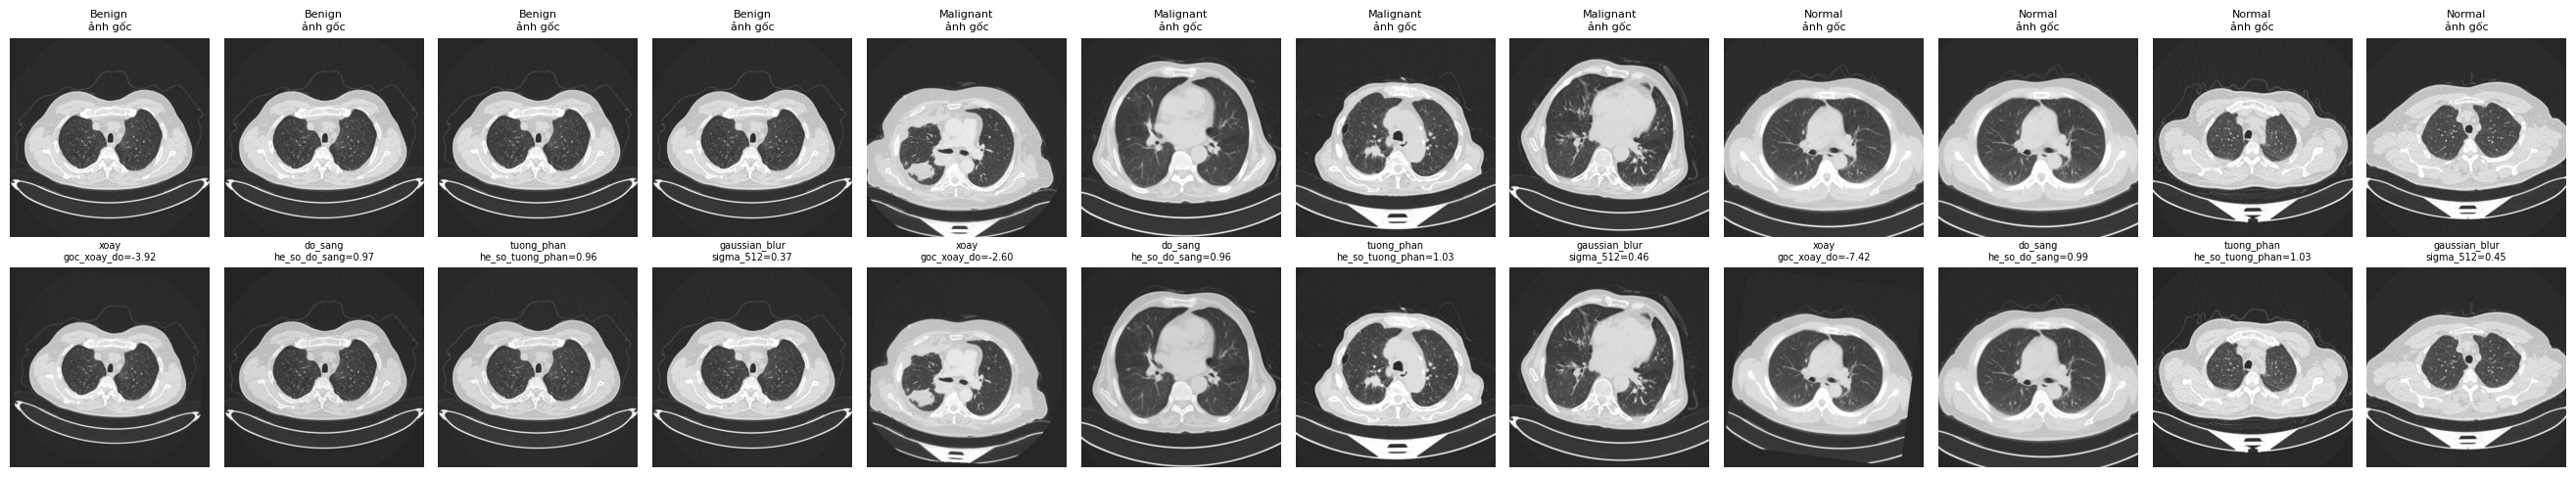

Đã lưu: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/20261122T082142_409115Z_EXPERIMENT/augmentation_truoc_sau.png và /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/20261122T082142_409115Z_EXPERIMENT/augmentation_thong_ke.csv


In [9]:
# Ảnh trước – sau: mỗi kỹ thuật một ví dụ cho từng lớp (ảnh gốc ở trên, ảnh sinh thêm ở dưới)
import matplotlib.pyplot as plt

theo_goc = {r["sha256"]: r for r in original_train_rows}
vi_du = []
for c in CLASS_NAMES:
    for k in AUG_TY_LE:
        r = next((x for x in train_rows if x.get("augmentation", {}).get("ky_thuat") == k
                  and x["class_name"] == c), None)
        if r is not None:
            vi_du.append((c, k, r))

fig, axes = plt.subplots(2, len(vi_du), figsize=(2.2 * len(vi_du), 5))
for j, (c, k, r) in enumerate(vi_du):
    goc = theo_goc[r["parent_sha256"]]
    axes[0, j].imshow(rgb_image(BASE_DIR / goc["relative_path"])); axes[0, j].set_title(f"{c}\nảnh gốc", fontsize=8)
    tham_so = ", ".join(f"{a}={b:.2f}" for a, b in r["augmentation"].items() if isinstance(b, float))
    axes[1, j].imshow(rgb_image(r["relative_path"])); axes[1, j].set_title(f"{k}\n{tham_so}", fontsize=7)
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "augmentation_truoc_sau.png", dpi=150)
plt.show(); plt.close(fig)
print("Đã lưu:", RUN_DIR / "augmentation_truoc_sau.png", "và", RUN_DIR / "augmentation_thong_ke.csv")


## 6. Trích đặc trưng ViT
ViT `google/vit-base-patch16-224-in21k` được đóng băng, mỗi ảnh cho một vector CLS 768 chiều. Cache chỉ dùng lại khi khớp đúng ảnh, thứ tự và phiên bản mô hình.

In [10]:
RESOLVED_VIT_REVISION = model_info(VIT_MODEL_ID, revision=VIT_REVISION).sha
if not RESOLVED_VIT_REVISION: raise RuntimeError("Không resolve được commit ViT.")
processor = ViTImageProcessor.from_pretrained(VIT_MODEL_ID, revision=RESOLVED_VIT_REVISION)
write_json(RUN_DIR / "vit_processor.json", processor.to_dict())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
_vit = None

def get_vit():
    global _vit
    if _vit is None:
        _vit = ViTModel.from_pretrained(VIT_MODEL_ID, revision=RESOLVED_VIT_REVISION).to(DEVICE).eval()
        assert _vit.config.hidden_size == 768, "Builder hiện dùng feature 768 chiều."
    return _vit

def release_vit():
    global _vit
    _vit = None
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def vit_batch(paths):
    """Trích CLS từ ảnh mới bằng đúng pipeline đã dùng tạo cache."""
    images = [rgb_image(p).resize(VIT_SIZE, Image.Resampling.NEAREST) for p in paths]
    inputs = processor(images=images, return_tensors="pt")
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
    with torch.inference_mode():
        output = get_vit()(**inputs).last_hidden_state[:, 0, :]
    return output.cpu().numpy().astype(np.float32)

def extract_features(rows):
    """Chỉ tái dùng cache khi ảnh, thứ tự, processor và môi trường đều khớp."""
    identity = {"images": [(r["relative_path"], r["sha256"]) for r in rows],
                "vit": VIT_MODEL_ID, "revision": RESOLVED_VIT_REVISION,
                "processor": processor.to_dict(), "resize": [*VIT_SIZE, "nearest"],
                "preprocessing": PREPROCESS_VERSION, "environment": ENVIRONMENT}
    key = digest_json(identity)
    array_path, meta_path = CACHE_ROOT / f"{key}.npy", CACHE_ROOT / f"{key}.json"
    if array_path.exists() and meta_path.exists():
        meta = json.loads(meta_path.read_text())
        feats = np.load(array_path, allow_pickle=False)
        if (meta.get("identity_hash") == key and meta.get("array_sha256") == sha256_file(array_path)
                and feats.shape == (len(rows), 768) and np.isfinite(feats).all()):
            print("Dùng cache đã đối chiếu:", key[:12]); return feats
    feats = np.concatenate([vit_batch([BASE_DIR / r["relative_path"] for r in rows[i:i+VIT_BATCH_SIZE]])
                            for i in range(0, len(rows), VIT_BATCH_SIZE)])
    assert feats.shape == (len(rows), 768) and np.isfinite(feats).all()
    np.save(array_path, feats, allow_pickle=False)
    write_json(meta_path, {"identity_hash": key, "identity": identity,
                          "array_sha256": sha256_file(array_path)})
    return feats

features = {"train": extract_features(train_rows), "validation": extract_features(val_rows)}
for _ten, _rows in (("train", train_rows), ("validation", val_rows)):
    assert len(features[_ten]) == len(_rows), f"{_ten}: {len(_rows)} ảnh nhưng {len(features[_ten])} vector"
print({k: v.shape for k, v in features.items()})
release_vit()
# TF giữ VRAM đã cấp phát sau train; dùng CPU cho ViT ở các bước ảnh đơn/test/export sau đó.
DEVICE = "cpu"
FEATURE_DIM = 768
write_json(RUN_DIR / "vit_source.json", {"model_id": VIT_MODEL_ID, "revision": RESOLVED_VIT_REVISION})

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'train': (2298, 768), 'validation': (158, 768)}


## 7. Bộ nạp dữ liệu
Ghép ảnh, vector CLS và nhãn theo từng batch cho từng loại mô hình. Class weight tính từ tập train.

In [11]:
augmenter = ImageDataGenerator(rotation_range=25, width_shift_range=0.20,
    height_shift_range=0.20, shear_range=0.15, zoom_range=0.20,
    horizontal_flip=True, brightness_range=[0.85, 1.15], channel_shift_range=15)

def cnn_image(path, augment=False):
    """RGB [0,1], resize nearest giống load_img mặc định của Keras."""
    image = np.array(rgb_image(path).resize(IMG_SIZE, Image.Resampling.NEAREST), dtype=np.float32)
    if augment: image = augmenter.random_transform(image)
    return image.astype(np.float32) / 255.0

class DataSequence(tf.keras.utils.Sequence):
    """Ghép nhãn, ảnh và CLS theo cùng chỉ số; không shuffle khi đánh giá."""
    def __init__(self, rows, feats, mode, training=False, **kwargs):
        super().__init__(**kwargs)
        self.rows, self.feats, self.mode, self.training = rows, feats, mode, training
        self.indices = np.arange(len(rows)); self.rng = np.random.default_rng(SEED)
        assert len(rows) == len(feats)
        self.on_epoch_end()
    def __len__(self): return math.ceil(len(self.rows) / BATCH_SIZE)
    def on_epoch_end(self):
        if self.training: self.rng.shuffle(self.indices)
    def __getitem__(self, index):
        ids = self.indices[index * BATCH_SIZE:(index+1) * BATCH_SIZE]
        y = tf.keras.utils.to_categorical([self.rows[k]["label"] for k in ids], NUM_CLASSES)
        if self.mode == "vit": return self.feats[ids], y
        augment = self.training and (CNN_AUGMENT if self.mode == "cnn" else FUSION_AUGMENT)
        images = np.stack([cnn_image(BASE_DIR / self.rows[k]["relative_path"], augment) for k in ids])
        return (images if self.mode == "cnn" else (images, self.feats[ids])), y

cw = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES),
                          y=[r["label"] for r in train_rows])
class_weights = {i: float(weight) for i, weight in enumerate(cw)}
write_json(RUN_DIR / "class_weights.json", class_weights)
print(class_weights)

{0: 1.0, 1: 1.0, 2: 1.0}


## 8. Kiến trúc mô hình
Bốn mô hình: CNN 3 lớp, ViT Head, CNN–ViT (nối đặc trưng) và AACNN–ViT Adaptive (ResNet50 + CLS, Adaptive Gate, Multi-Head Attention hai token). Các layer tự định nghĩa đều lưu/nạp lại được.

In [12]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
def build_cnn_baseline():
    """CNN baseline ba convolution; đầu vào RGB [0,1], không dùng ResNet pretrained."""
    inp = layers.Input(shape=(*IMG_SIZE,3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inp)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inp, out, name="CNN_Baseline")


# --- ViT head (feature-only) ---
def build_vit_head():
    """Head phân loại trên CLS ViT đóng băng; không fine-tune ViT trong graph Keras."""
    inp = layers.Input(shape=(FEATURE_DIM,))
    x = layers.Dense(256, activation="relu")(inp)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inp, out, name="ViT_Head")


# --- CNN-ViT baseline (concat) ---
def build_cnn_vit():
    """Nối đặc trưng CNN nhỏ và CLS ViT."""
    img_in = layers.Input(shape=(*IMG_SIZE,3), name="image_input")
    vit_in = layers.Input(shape=(FEATURE_DIM,), name="vit_features_input")

    x = layers.Conv2D(16, 3, padding="same", activation="relu")(img_in)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    cnn_feat = layers.GlobalAveragePooling2D(name="cnn_gap")(x)

    fused = layers.Concatenate()([cnn_feat, vit_in])
    h = layers.Dense(256, activation="relu")(fused)
    h = layers.Dropout(0.5)(h)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(h)

    return tf.keras.Model([img_in, vit_in], out, name="CNN_ViT")

In [13]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
@tf.keras.utils.register_keras_serializable(package="LungCT")
class ResNetPreprocess(layers.Layer):
    """Chuyển RGB [0,1] sang preprocessing ResNet ImageNet đúng một lần."""
    def call(self, x): return tf.keras.applications.resnet.preprocess_input(x * 255.0)

@tf.keras.utils.register_keras_serializable(package="LungCT")
class StackTokens(layers.Layer):
    def call(self, inputs): return tf.stack(inputs, axis=1)
    def compute_output_shape(self, shapes): return (shapes[0][0], len(shapes), shapes[0][-1])

@tf.keras.utils.register_keras_serializable(package="LungCT")
class AdaptiveGate(layers.Layer):
    """Học alpha trong [0,1] để trộn hai token có cùng chiều."""
    def __init__(self, d_hidden=128, dropout=0.25, l2=1e-4, **kwargs):
        super().__init__(**kwargs)
        self.d_hidden, self.dropout_rate, self.l2_rate = d_hidden, dropout, l2
        self.concat = layers.Concatenate()
        self.d1 = layers.Dense(d_hidden, activation="relu", kernel_regularizer=regularizers.l2(l2))
        self.drop = layers.Dropout(dropout)
        self.logit = layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros")
    def build(self, input_shape):
        # Tạo biến rõ ràng để Keras khôi phục sublayer weights an toàn.
        a, b = input_shape
        if a[-1] != b[-1]: raise ValueError("Hai token phải cùng chiều.")
        self.concat.build(input_shape)
        self.d1.build((a[0], a[-1] + b[-1]))
        self.drop.build((a[0], self.d_hidden))
        self.logit.build((a[0], self.d_hidden))
        super().build(input_shape)
    def call(self, inputs, training=None):
        a, b = inputs
        alpha = tf.sigmoid(self.logit(self.drop(self.d1(self.concat([a, b])), training=training)))
        return alpha * a + (1-alpha) * b
    def get_config(self):
        return {**super().get_config(), "d_hidden": self.d_hidden,
                "dropout": self.dropout_rate, "l2": self.l2_rate}

def _resnet_backbone(img_in):
    # Graph phẳng giúp truy cập convolution của ResNet từ model cuối để lấy gradient.
    x_img = ResNetPreprocess(name="resnet_preprocess")(img_in)
    base = tf.keras.applications.ResNet50(include_top=False, weights="imagenet",
        input_tensor=x_img, pooling="avg")
    base.trainable = False
    return base, base.output

In [14]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
def build_aacnn_adaptive(d_model=256, l2=1e-4):
    """ResNet50 và CLS ViT qua adaptive gate cùng attention hai token."""
    img_in = layers.Input(shape=(*IMG_SIZE,3), name="image_input")
    vit_in = layers.Input(shape=(FEATURE_DIM,), name="vit_features_input")
    base, cnn_feat = _resnet_backbone(img_in)

    cnn_feat = layers.Dense(512, activation="relu")(cnn_feat)
    cnn_feat = layers.Dropout(0.25)(cnn_feat)
    cnn_tok = layers.Dense(d_model, activation="relu", kernel_regularizer=regularizers.l2(l2), name="cnn_token")(cnn_feat)

    vit_feat = layers.LayerNormalization()(vit_in)
    vit_feat = layers.Dense(512, activation="gelu")(vit_feat)
    vit_feat = layers.Dropout(0.25)(vit_feat)
    vit_tok = layers.Dense(d_model, activation="gelu", kernel_regularizer=regularizers.l2(l2), name="vit_token")(vit_feat)

    gated = AdaptiveGate(name="adaptive_gate")([cnn_tok, vit_tok])

    tokens = StackTokens(name="stack_tokens")([cnn_tok, vit_tok])  # [B,2,D]
    attn = layers.MultiHeadAttention(num_heads=4, key_dim=d_model//4, dropout=0.10, name="cross_attn")
    attn_out = attn(tokens, tokens)
    attn_out = layers.Add()([tokens, attn_out])
    attn_out = layers.LayerNormalization()(attn_out)
    attn_flat = layers.Flatten(name="attn_flat")(attn_out)

    fused = layers.Concatenate(name="fusion_concat")([gated, cnn_tok, vit_tok, attn_flat])

    h = layers.Dense(1024, activation="gelu", kernel_regularizer=regularizers.l2(l2))(fused)
    h = layers.Dropout(0.40)(h)
    h = layers.Dense(512, activation="gelu", kernel_regularizer=regularizers.l2(l2))(h)
    h = layers.Dropout(0.35)(h)
    h = layers.Dense(256, activation="gelu")(h)
    h = layers.Dropout(0.30)(h)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(h)

    model = tf.keras.Model([img_in, vit_in], out, name="AACNN_ViT_ADAPTIVE")
    model._cnn_backbone = base
    return model

In [15]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
# ===== Chế độ "thu_anh": nạp mô hình đã huấn luyện, thay cho mục 3–7 và 9–19 =====
if CHE_DO == "thu_anh":
    import cv2, pandas as pd
    FEATURE_DIM = 768
    if RUN_DA_TRAIN is None:
        ung_vien = sorted(p.parent.parent for p in OUTPUT_ROOT.glob("*_EXPERIMENT/AACNN_Adaptive/model.keras"))
        if not ung_vien:
            raise FileNotFoundError(f"Không thấy model.keras nào trong {OUTPUT_ROOT}")
        RUN_DA_TRAIN = ung_vien[-1]
    RUN_DA_TRAIN = Path(RUN_DA_TRAIN)
    SELECTED_MODEL = "AACNN_Adaptive"
    selected_dir = RUN_DA_TRAIN / SELECTED_MODEL
    selected_model = tf.keras.models.load_model(selected_dir / "model.keras", compile=False, safe_mode=True)
    model_cam = selected_model

    def rgb_image(path):
        with Image.open(path) as im:
            return im.convert("RGB").copy()

    def cnn_image(path, augment=False):
        return np.array(rgb_image(path).resize(IMG_SIZE, Image.Resampling.NEAREST), dtype=np.float32) / 255.0

    RESOLVED_VIT_REVISION = json.loads((RUN_DA_TRAIN / "vit_source.json").read_text(encoding="utf-8"))["revision"]
    processor = ViTImageProcessor.from_pretrained(VIT_MODEL_ID, revision=RESOLVED_VIT_REVISION)
    DEVICE, _vit = "cpu", None

    def get_vit():
        global _vit
        if _vit is None:
            _vit = ViTModel.from_pretrained(VIT_MODEL_ID, revision=RESOLVED_VIT_REVISION).to(DEVICE).eval()
        return _vit

    def release_vit():
        global _vit
        _vit = None; gc.collect()

    def vit_batch(paths):
        images = [rgb_image(p).resize(VIT_SIZE, Image.Resampling.NEAREST) for p in paths]
        inputs = {k: v.to(DEVICE) for k, v in processor(images=images, return_tensors="pt").items()}
        with torch.inference_mode():
            return get_vit()(**inputs).last_hidden_state[:, 0, :].cpu().numpy().astype(np.float32)

    def inputs_for_image(path, selected_mode="fusion"):
        image = cnn_image(path)[None, ...]
        cls = vit_batch([path]); release_vit()
        return (image, cls)

    def make_gradcam(model, inputs, class_index=None):
        target = model.get_layer("conv5_block3_out")
        grad_model = tf.keras.Model(model.inputs, [target.output, model.output])
        tensor_inputs = tf.nest.map_structure(tf.convert_to_tensor, inputs)
        with tf.GradientTape() as tape:
            for value in tf.nest.flatten(tensor_inputs): tape.watch(value)
            activations, scores = grad_model(tensor_inputs, training=False)
            index = int(tf.argmax(scores[0])) if class_index is None else int(class_index)
            objective = scores[:, index]
        gradients = tape.gradient(objective, activations)
        weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(activations * weights, axis=-1))[0]
        maximum = float(tf.reduce_max(cam))
        if maximum <= 1e-12:
            return np.zeros(cam.shape, np.float32), {"status": "ZERO_CAM", "target_layer": target.name}
        return (cam / maximum).numpy(), {"status": "PASS", "target_layer": target.name,
                                       "target_class": CLASS_NAMES[index], "scope": "CNN branch; fixed ViT CLS"}

    def phan_tich_anh_moi(duong_dan, luu_png=None):
        duong_dan = Path(duong_dan)
        image = cnn_image(duong_dan)[None, ...]
        cls = vit_batch([duong_dan]); release_vit()
        cams, probs, _ = GRADCAM_CHINH((image, cls))
        kq, panel = xu_ly_ket_qua(np.array(rgb_image(duong_dan)), cams[0], probs[0], GRADCAM_CHINH.ten_lop)
        kq["canh_bao"] = CANH_BAO
        kq["image_sha256"] = sha256_file(duong_dan)
        if luu_png is not None:
            Image.fromarray(panel).save(luu_png)
        return kq, panel

    globals().pop("GRADCAM_CHINH", None)
    print("Đã nạp mô hình từ run:", RUN_DA_TRAIN.name)

## 9. Loss và huấn luyện
Loss = 0,7 × Focal + 0,3 × Cross-entropy, optimizer AdamW. Checkpoint được chọn theo macro-F1 validation cao nhất; Adaptive học hai giai đoạn (stage A đóng băng ResNet50, stage B mở 60 lớp cuối).

In [16]:
@tf.keras.utils.register_keras_serializable(package="LungCT")
def source_hybrid_loss(y_true, y_pred):
    """0,7 focal + 0,3 CCE; trả vector theo từng mẫu để áp class weights."""
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    ce = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
    pt = y_true * y_pred + (1-y_true) * (1-y_pred)
    focal = tf.reduce_mean(0.25 * tf.pow(1-pt, 2.0) * (-y_true) * tf.math.log(y_pred), axis=-1)
    # Trả loss theo từng mẫu để class_weight áp đúng vào mỗi ảnh.
    return 0.7 * focal + 0.3 * ce

# Thay scalar batch bằng vector per-sample là sửa lỗi trọng số; ghi trong manifest, không gọi loss parity tuyệt đối.
def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=5e-6),
                  loss=source_hybrid_loss, metrics=["accuracy"])

def predict_sequence(model, seq):
    """Trả nhãn/scores đúng thứ tự; không gọi on_epoch_end ở giữa đánh giá."""
    ys, probs = [], []
    for i in range(len(seq)):
        x, y = seq[i]
        probs.append(np.asarray(model(x, training=False))); ys.append(np.asarray(y))
    return np.concatenate(ys), np.concatenate(probs)

class ValidationCheckpoint(tf.keras.callbacks.Callback):
    """Giữ best macro F1 xuyên hai stage; lưu history theo epoch xuống Drive."""
    def __init__(self, seq, path):
        super().__init__(); self.seq, self.path = seq, Path(path)
        self.best, self.rows = -1.0, []
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        yt, yp = predict_sequence(self.model, self.seq)
        score = float(f1_score(yt.argmax(1), yp.argmax(1), labels=np.arange(NUM_CLASSES),
                               average="macro", zero_division=0))
        logs["val_macro_f1"] = score
        self.rows.append({"global_epoch": len(self.rows)+1,
                          **{k: float(v) for k, v in logs.items()}})
        if score > self.best:
            self.best = score; self.model.save_weights(self.path)
        write_json(self.path.parent / "history.json", self.rows)
        print(f" — val_macro_f1={score:.4f}; best={self.best:.4f}")

BUILDERS = {"CNN": build_cnn_baseline, "ViT_Head": build_vit_head,
            "CNN_ViT": build_cnn_vit, "AACNN_Adaptive": build_aacnn_adaptive}
MODES = {"CNN": "cnn", "ViT_Head": "vit", "CNN_ViT": "fusion", "AACNN_Adaptive": "fusion"}

def train_one(name):
    """Train một model mới; chỉ chọn bằng validation, trả đường dẫn best weights."""
    tf.keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = BUILDERS[name]()
    model_dir = RUN_DIR / name; model_dir.mkdir(exist_ok=True)
    (model_dir / "summary.txt").write_text("", encoding="utf-8")
    with open(model_dir / "summary.txt", "w") as stream: model.summary(print_fn=lambda s, **k: stream.write(s+"\n"))
    train_seq = DataSequence(train_rows, features["train"], MODES[name], training=True)
    val_seq = DataSequence(val_rows, features["validation"], MODES[name])
    tracker = ValidationCheckpoint(val_seq, model_dir / "best.weights.h5")
    def callbacks():
        cbs = [tracker,
               tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
               tf.keras.callbacks.TerminateOnNaN()]
        if EARLY_STOP_PATIENCE:   # None/0 = không dừng sớm
            cbs.insert(1, tf.keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max",
                                                           patience=EARLY_STOP_PATIENCE))
        return cbs
    compile_model(model, 2e-4 if name == "AACNN_Adaptive" else 1e-4)
    epochs = 1 if SMOKE_TEST else (EPOCHS_STAGE_A if name == "AACNN_Adaptive" else EPOCHS_BASELINE)
    started = time.perf_counter()
    model.fit(train_seq, validation_data=val_seq, epochs=epochs,
              class_weight=class_weights, callbacks=callbacks(), verbose=1)
    if not tracker.path.exists(): raise RuntimeError("Không có checkpoint hợp lệ sau stage A.")
    model.load_weights(tracker.path)
    if name == "AACNN_Adaptive":
        backbone = model._cnn_backbone
        backbone.trainable = True
        for layer in backbone.layers: layer.trainable = False
        for layer in backbone.layers[-UNFREEZE_LAST_N:]:
            layer.trainable = not (FREEZE_BATCHNORM and isinstance(layer, layers.BatchNormalization))
        compile_model(model, 5e-5)
        model.fit(train_seq, validation_data=val_seq, epochs=1 if SMOKE_TEST else EPOCHS_STAGE_B,
                  class_weight=class_weights, callbacks=callbacks(), verbose=1)
        model.load_weights(tracker.path)
    write_json(model_dir / "training.json", {"wall_seconds": time.perf_counter()-started,
        "best_val_macro_f1": tracker.best, "parameters": model.count_params(),
        "checkpoint_sha256": sha256_file(tracker.path), "smoke": SMOKE_TEST})
    return model, model_dir, val_seq

## 10. Kiểm tra kỹ thuật
Chạy thử một batch cho cả bốn mô hình để kiểm tra dữ liệu, `fit` và lưu/nạp lại trước khi huấn luyện chính thức.

In [17]:
FEATURE_ROWS = {
    "train": train_rows,
    "validation": val_rows,
    "test": test_rows,
}

features = {
    name: extract_features(FEATURE_ROWS[name])
    for name in ("train", "validation")
}

FEATURE_ROW_IDS = {
    name: [
        (row["relative_path"], row["sha256"])
        for row in FEATURE_ROWS[name]
    ]
    for name in ("train", "validation")
}

release_vit()

for name in ("train", "validation"):
    so_anh = len(FEATURE_ROWS[name])
    so_vector = len(features[name])

    print(f"{name}: {so_anh} ảnh — {so_vector} vector ViT")

    if so_anh != so_vector:
        raise ValueError(f"{name}: số ảnh và vector chưa khớp.")

print("Đã đồng bộ ảnh và đặc trưng. Có thể chạy mục 9.")

Dùng cache đã đối chiếu: a42df745451c
Dùng cache đã đối chiếu: 60bb8f6c2eca
train: 2298 ảnh — 2298 vector ViT
validation: 158 ảnh — 158 vector ViT
Đã đồng bộ ảnh và đặc trưng. Có thể chạy mục 9.


In [18]:
# Chặn cả trường hợp số lượng bằng nhau nhưng thứ tự ảnh khác.
for split_name, current_rows in (("train", train_rows), ("validation", val_rows)):
    current_ids = [(r["relative_path"], r["sha256"]) for r in current_rows]
    if FEATURE_ROW_IDS[split_name] != current_ids:
        raise ValueError(f"Manifest {split_name} đổi sau trích CLS; chạy lại mục 6 trước preflight.")

preflight_results = {}
for name in MODELS_TO_RUN:
    tf.keras.backend.clear_session(); gc.collect()
    temporary_model = BUILDERS[name]()
    temporary_seq = DataSequence(train_rows, features["train"], MODES[name], training=True)
    temporary_val = DataSequence(val_rows, features["validation"], MODES[name])
    preflight_dir = RUN_DIR / "preflight" / name
    preflight_dir.mkdir(parents=True, exist_ok=True)
    try:
        compile_model(temporary_model, 1e-4)
        temporary_model.fit(temporary_seq, epochs=1, steps_per_epoch=1,
                            class_weight=class_weights, verbose=0)
        probe, _ = temporary_val[0]
        expected = np.asarray(temporary_model(probe, training=False))
        temporary_model.save(preflight_dir / "probe.keras")
        loaded_probe = tf.keras.models.load_model(preflight_dir / "probe.keras", compile=False, safe_mode=True)
        actual = np.asarray(loaded_probe(probe, training=False))
        np.testing.assert_allclose(expected, actual, atol=1e-5, rtol=1e-4)
        preflight_results[name] = {"status": "PASS", "max_abs_error": float(np.max(np.abs(expected-actual)))}
        del loaded_probe
        # Model tạm không phải checkpoint nghiên cứu, xóa để giảm dung lượng Drive.
        (preflight_dir / "probe.keras").unlink()
    except Exception as error:
        preflight_results[name] = {"status": "FAIL", "error": repr(error)}
        write_json(RUN_DIR / "preflight.json", preflight_results)
        raise
    finally:
        del temporary_model, temporary_seq, temporary_val
        tf.keras.backend.clear_session(); gc.collect()
    write_json(RUN_DIR / "preflight.json", preflight_results)
print("Preflight:", preflight_results)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Preflight: {'CNN': {'status': 'PASS', 'max_abs_error': 0.0}, 'ViT_Head': {'status': 'PASS', 'max_abs_error': 0.0}, 'CNN_ViT': {'status': 'PASS', 'max_abs_error': 0.0}, 'AACNN_Adaptive': {'status': 'PASS', 'max_abs_error': 0.0}}


## 11. Huấn luyện và đánh giá validation
Huấn luyện bốn mô hình, lưu báo cáo từng lớp, ma trận nhầm lẫn, ROC và biểu đồ loss/accuracy theo epoch.

Epoch 1/30


288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.3470 - loss: 0.3559 — val_macro_f1=0.3262; best=0.3262
288/288 ━━━━━━━━━━━━━━━━━━━━ 48s 160ms/step - accuracy: 0.3777 - loss: 0.3530 - val_accuracy: 0.3987 - val_loss: 0.3444 - val_macro_f1: 0.3262 - learning_rate: 1.0000e-04
Epoch 2/30
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.4882 - loss: 0.3355 — val_macro_f1=0.4311; best=0.4311
288/288 ━━━━━━━━━━━━━━━━━━━━ 39s 137ms/step - accuracy: 0.4883 - loss: 0.3293 - val_accuracy: 0.6582 - val_loss: 0.2689 - val_macro_f1: 0.4311 - learning_rate: 1.0000e-04
Epoch 3/30
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.5041 - loss: 0.3106 — val_macro_f1=0.5605; best=0.5605
288/288 ━━━━━━━━━━━━━━━━━━━━ 45s 158ms/step - accuracy: 0.5287 - loss: 0.3035 - val_accuracy: 0.6646 - val_loss: 0.2300 - val_macro_f1: 0.5605 - learning_rate: 1.0000e-04
Epoch 4/30
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.5686 - loss: 0.2831 — val_macro_f1=0.5864; best=0.5864
288/28

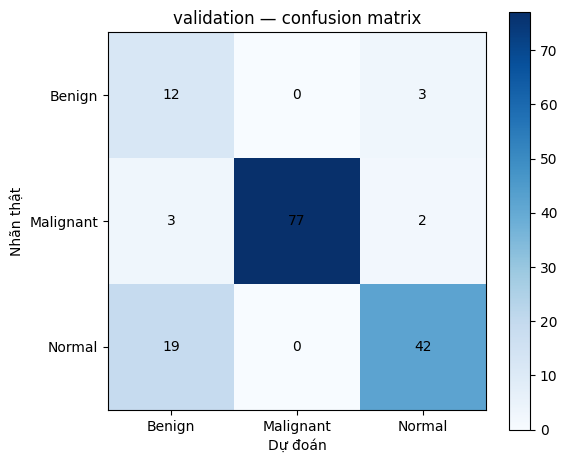

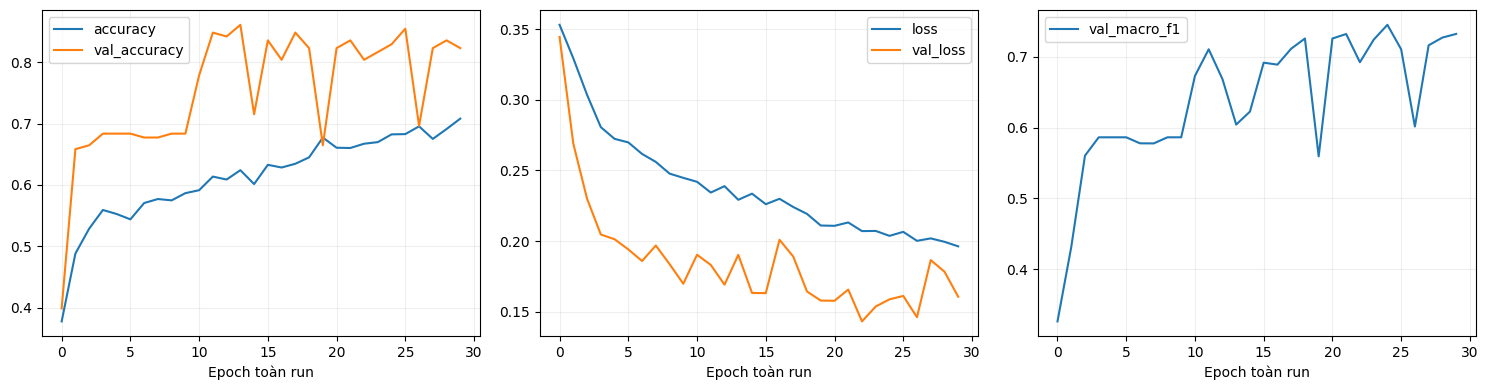

Epoch 1/30
281/288 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5268 - loss: 0.3186 — val_macro_f1=0.6486; best=0.6486
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6153 - loss: 0.2796 - val_accuracy: 0.7405 - val_loss: 0.1691 - val_macro_f1: 0.6486 - learning_rate: 1.0000e-04
Epoch 2/30
278/288 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7288 - loss: 0.1996 — val_macro_f1=0.7553; best=0.7553
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7346 - loss: 0.1921 - val_accuracy: 0.8354 - val_loss: 0.1349 - val_macro_f1: 0.7553 - learning_rate: 1.0000e-04
Epoch 3/30
278/288 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7657 - loss: 0.1661 — val_macro_f1=0.7630; best=0.7630
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7711 - loss: 0.1634 - val_accuracy: 0.8608 - val_loss: 0.1108 - val_macro_f1: 0.7630 - learning_rate: 1.0000e-04
Epoch 4/30
287/288 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8185 - loss: 0.1431 — val_macro_f1=0.7605; best=0.7630
288/288 ━━━━

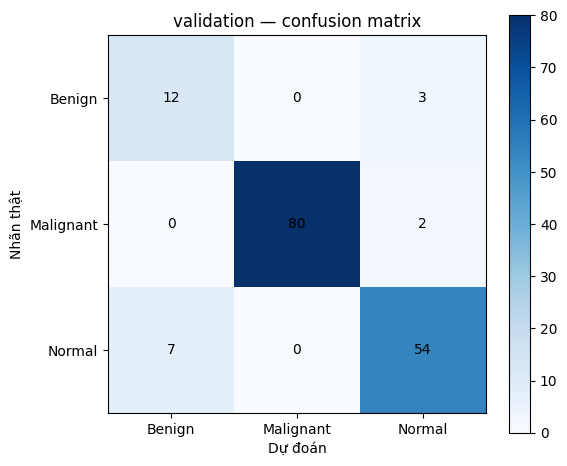

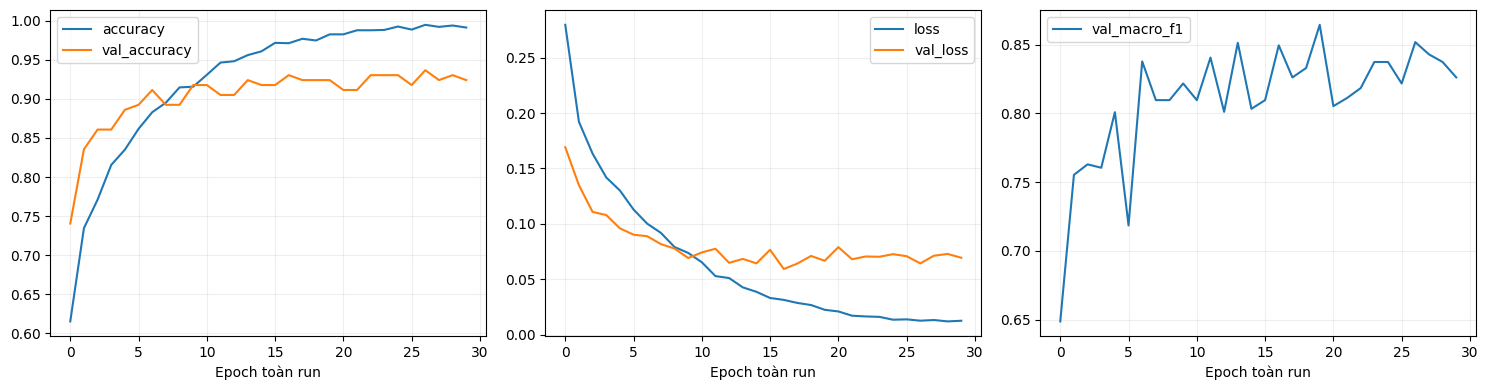

Epoch 1/30
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.5477 - loss: 0.3010 — val_macro_f1=0.6716; best=0.6716
288/288 ━━━━━━━━━━━━━━━━━━━━ 47s 156ms/step - accuracy: 0.6410 - loss: 0.2630 - val_accuracy: 0.7595 - val_loss: 0.1811 - val_macro_f1: 0.6716 - learning_rate: 1.0000e-04
Epoch 2/30
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.7490 - loss: 0.1974 — val_macro_f1=0.7164; best=0.7164
288/288 ━━━━━━━━━━━━━━━━━━━━ 45s 157ms/step - accuracy: 0.7454 - loss: 0.1922 - val_accuracy: 0.8101 - val_loss: 0.1488 - val_macro_f1: 0.7164 - learning_rate: 1.0000e-04
Epoch 3/30
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.7856 - loss: 0.1688 — val_macro_f1=0.7429; best=0.7429
288/288 ━━━━━━━━━━━━━━━━━━━━ 44s 154ms/step - accuracy: 0.7863 - loss: 0.1645 - val_accuracy: 0.8354 - val_loss: 0.1261 - val_macro_f1: 0.7429 - learning_rate: 1.0000e-04
Epoch 4/30
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.8102 - loss: 0.1529 — val_macro_f1=0.7337; best=0.

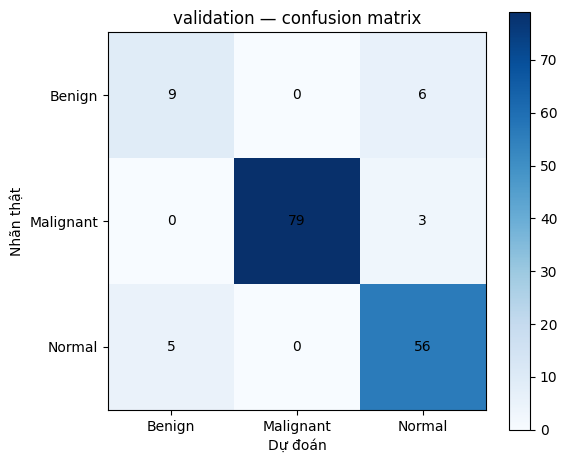

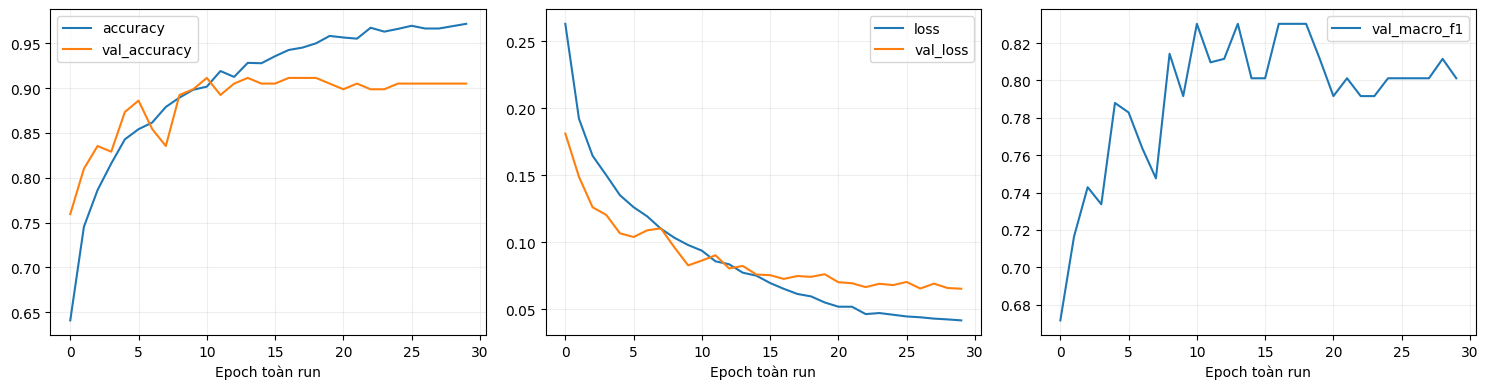

Epoch 1/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.6005 - loss: 0.5183 — val_macro_f1=0.6336; best=0.6336
288/288 ━━━━━━━━━━━━━━━━━━━━ 72s 212ms/step - accuracy: 0.6732 - loss: 0.4578 - val_accuracy: 0.8544 - val_loss: 0.3548 - val_macro_f1: 0.6336 - learning_rate: 2.0000e-04
Epoch 2/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.7648 - loss: 0.3819 — val_macro_f1=0.8056; best=0.8056
288/288 ━━━━━━━━━━━━━━━━━━━━ 62s 214ms/step - accuracy: 0.7746 - loss: 0.3748 - val_accuracy: 0.9114 - val_loss: 0.2917 - val_macro_f1: 0.8056 - learning_rate: 2.0000e-04
Epoch 3/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.8516 - loss: 0.3265 — val_macro_f1=0.8259; best=0.8259
288/288 ━━━━━━━━━━━━━━━━━━━━ 62s 214ms/step - accuracy: 0.8673 - loss: 0.3185 - val_accuracy: 0.9051 - val_loss: 0.3075 - val_macro_f1: 0.8259 - learning_rate: 2.0000e-04
Epoch 4/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9076 - loss: 0.2808 — val_macro_f1=0.8214; best=0.

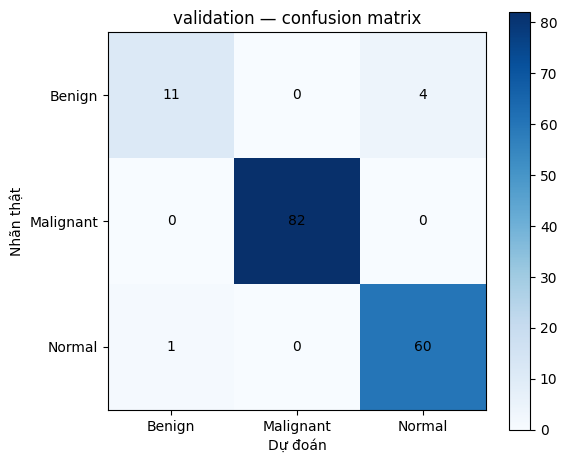

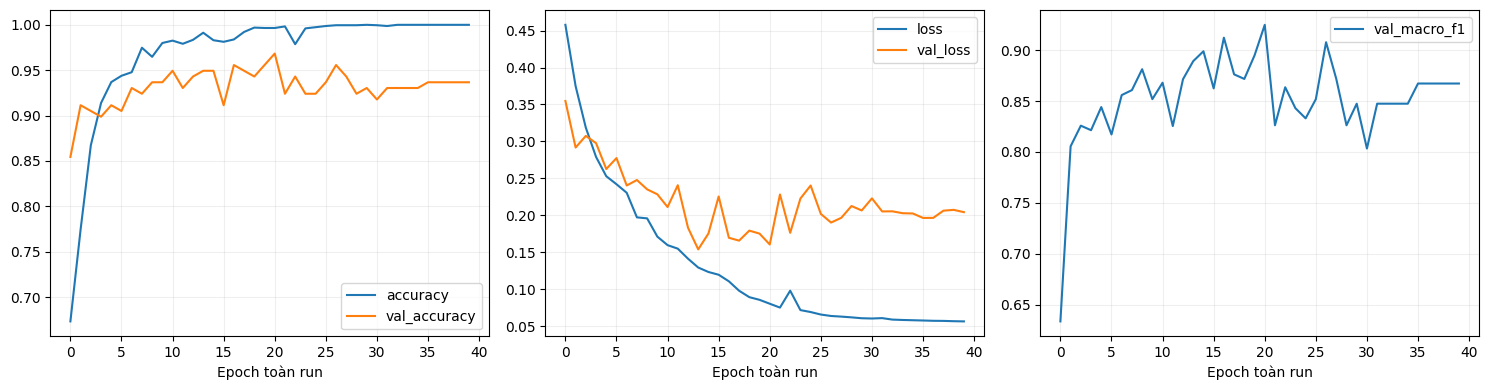

{'CNN': 0.7453757184215405, 'ViT_Head': 0.8645122246429436, 'CNN_ViT': 0.8303150012295438, 'AACNN_Adaptive': 0.9249382716049382}


In [19]:
def evaluate_and_save(model, seq, rows, directory, tag):
    """Lưu số đo và dữ liệu gốc; không gọi fit từ hàm đánh giá/vẽ."""
    directory = Path(directory)
    y, prob = predict_sequence(model, seq)
    actual, pred = y.argmax(1), prob.argmax(1)
    assert len(prob) == len(rows) and np.isfinite(prob).all()
    assert np.allclose(prob.sum(1), 1, atol=1e-4)
    report = classification_report(actual, pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    cm = confusion_matrix(actual, pred, labels=np.arange(NUM_CLASSES))
    write_json(directory / f"{tag}_metrics.json", report)
    write_json(directory / f"{tag}_confusion_matrix.json", cm.tolist())
    with open(directory / f"{tag}_predictions.csv", "w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.writer(stream)
        writer.writerow(["image_sha256", "actual", "predicted", *[f"score_{n}" for n in CLASS_NAMES]])
        for r, a, b, scores in zip(rows, actual, pred, prob):
            writer.writerow([r["sha256"], CLASS_NAMES[a], CLASS_NAMES[b], *scores.tolist()])
    fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES), xticklabels=CLASS_NAMES,
           yticklabels=CLASS_NAMES, xlabel="Dự đoán", ylabel="Nhãn thật", title=f"{tag} — confusion matrix")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES): ax.text(j, i, str(cm[i,j]), ha="center", va="center")
    fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(directory/f"{tag}_cm.png", dpi=160); plt.show(); plt.close(fig)
    fig, ax = plt.subplots(figsize=(6,5))
    for i, name in enumerate(CLASS_NAMES):
        if len(np.unique(y[:, i])) < 2: continue
        fpr, tpr, _ = roc_curve(y[:, i], prob[:, i])
        ax.plot(fpr, tpr, label=f"{name} AUC={auc(fpr,tpr):.3f}")
    ax.plot([0,1],[0,1], "--", color="gray"); ax.set(xlabel="FPR", ylabel="TPR", title=f"{tag} ROC")
    ax.legend(); fig.tight_layout(); fig.savefig(directory/f"{tag}_roc.png",dpi=160); plt.close(fig)
    return report

def plot_history(model_dir):
    history = json.loads((model_dir / "history.json").read_text())
    fig, axes = plt.subplots(1, 3, figsize=(15,4))
    for ax, keys in zip(axes, [("accuracy","val_accuracy"), ("loss","val_loss"), ("val_macro_f1",)]):
        for key in keys: ax.plot([r.get(key, np.nan) for r in history], label=key)
        ax.set_xlabel("Epoch toàn run"); ax.legend(); ax.grid(alpha=0.2)
    fig.tight_layout(); fig.savefig(model_dir/"history.png",dpi=160); plt.show(); plt.close(fig)

validation_results = {}
for name in MODELS_TO_RUN:
    if name not in BUILDERS: raise ValueError(f"Chưa có builder: {name}")
    model, model_dir, val_seq = train_one(name)
    validation_results[name] = evaluate_and_save(model, val_seq, val_rows, model_dir, "validation")
    plot_history(model_dir)
    # Kiểm tra lưu/nạp full model trước khi dùng làm artifact triển khai.
    sample, _ = val_seq[0]
    before = np.asarray(model(sample, training=False))
    try:
        model.save(model_dir / "model.keras")
        reloaded = tf.keras.models.load_model(model_dir / "model.keras", compile=False, safe_mode=True)
        after = np.asarray(reloaded(sample, training=False))
        np.testing.assert_allclose(before, after, rtol=1e-4, atol=1e-5)
        write_json(model_dir / "roundtrip.json", {"status": "PASS", "max_abs_error": float(np.max(np.abs(before-after)))})
        del reloaded
    except Exception as error:
        write_json(model_dir / "roundtrip.json", {"status": "FAIL", "error": repr(error)})
        raise RuntimeError("Nạp lại model lỗi; xem roundtrip.json, chưa đủ điều kiện artifact.") from error
    del model, val_seq; tf.keras.backend.clear_session(); gc.collect()
write_json(RUN_DIR / "validation_comparison.json", validation_results)
print({name: result["macro avg"]["f1-score"] for name, result in validation_results.items()})

## 12. Nạp mô hình và dự đoán một ảnh
Nạp lại mô hình chính đã lưu và dự đoán thử một ảnh validation để kiểm tra luồng suy luận.

In [20]:
SELECTED_MODEL = "AACNN_Adaptive"
assert SELECTED_MODEL in MODELS_TO_RUN, "Phải train mô hình chính Adaptive trong run này."
NEW_IMAGE_PATH = BASE_DIR / val_rows[0]["relative_path"]
selected_dir = RUN_DIR / SELECTED_MODEL
selected_model = tf.keras.models.load_model(selected_dir / "model.keras", compile=False, safe_mode=True)
mode = MODES[SELECTED_MODEL]

def inputs_for_image(path, selected_mode):
    """Tạo tensor ảnh/CLS theo cùng quy cách đầu vào dùng khi huấn luyện và lưu cache"""
    image = cnn_image(path)[None, ...]
    if selected_mode == "cnn": return image
    cls = vit_batch([path]); release_vit()
    return cls if selected_mode == "vit" else (image, cls)

new_inputs = inputs_for_image(NEW_IMAGE_PATH, mode)
new_scores = np.asarray(selected_model(new_inputs, training=False))[0]
new_result = {"image_sha256": sha256_file(NEW_IMAGE_PATH), "model": SELECTED_MODEL,
              "class_order": CLASS_NAMES, "scores": new_scores.tolist(),
              "label": CLASS_NAMES[int(np.argmax(new_scores))], "mode": "real",
              "execution_source": "colab", "smoke": SMOKE_TEST}
write_json(selected_dir / "new_image_result.json", new_result)
print(new_result)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'image_sha256': '925e9ab76b0a7ee5ff91f202de4afe25a5bfa3007cfac7fc292f098542ae4a69', 'model': 'AACNN_Adaptive', 'class_order': ['Benign', 'Malignant', 'Normal'], 'scores': [0.9838369488716125, 2.7269767088000663e-05, 0.016135701909661293], 'label': 'Benign', 'mode': 'real', 'execution_source': 'colab', 'smoke': False}


## 13. Đánh giá test
Đánh giá mô hình chính trên tập test đúng một lần, sau khi đã chốt checkpoint bằng validation.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

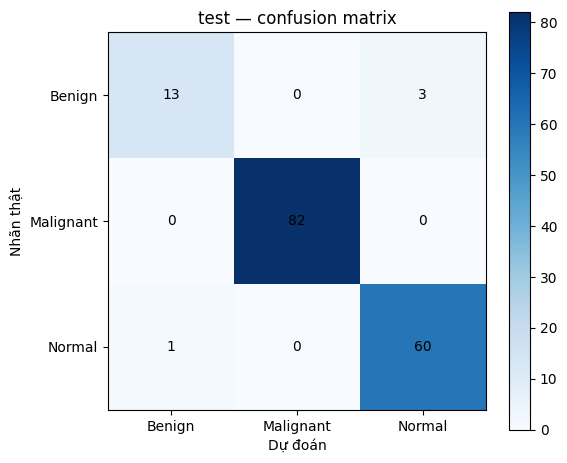

In [21]:
# Chạy test theo cờ cấu hình đầu notebook; không dùng kết quả để sửa/chọn mô hình.
if RUN_TEST_ONCE and not SMOKE_TEST:
    assert not SMOKE_TEST, "Smoke không phải thí nghiệm đánh giá cuối."
    assert SPLIT_MODE == "holdout" and test_rows, "Run này không có test độc lập."
    marker = RUN_DIR / "test_started.json"
    if marker.exists(): raise RuntimeError("Test đã bắt đầu trong run này; kiểm tra hồ sơ thay vì chạy lặp.")
    write_json(marker, {"model": SELECTED_MODEL, "time": datetime.now(timezone.utc).isoformat(),
                        "split_hash": SPLIT_HASH})
    features["test"] = extract_features(test_rows); release_vit()
    seq = DataSequence(test_rows, features["test"], mode)
    evaluate_and_save(selected_model, seq, test_rows, selected_dir, "test")
else:
    print("Test NOT_RUN — đang smoke hoặc RUN_TEST_ONCE=False.")

## 14. Grad-CAM nhánh CNN
Bản đồ vùng mô hình chú ý trên lớp `conv5_block3_out` của ResNet50, với vector CLS giữ cố định.

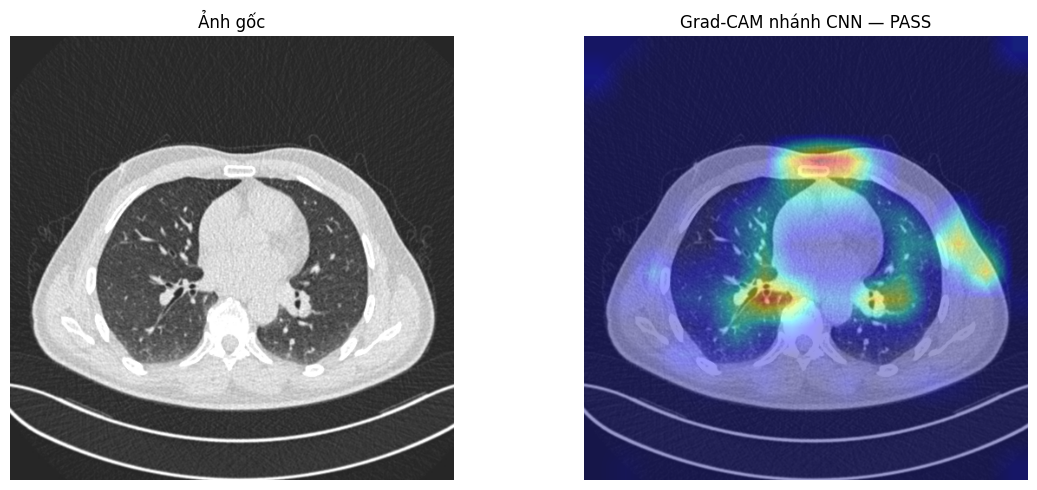

{'status': 'PASS', 'target_layer': 'conv5_block3_out', 'target_class': 'Benign', 'scope': 'CNN branch; fixed ViT CLS'}


In [22]:
def make_gradcam(model, inputs, class_index=None):
    """Grad-CAM CNN; trả bản đồ chuẩn hóa và chẩn đoán gradient."""
    convs = [layer for layer in model.layers if isinstance(layer, layers.Conv2D)]
    if not convs: raise ValueError("Model không có convolution; ViT_Head không hỗ trợ CAM CNN.")
    target = model.get_layer("conv5_block3_out") if any(l.name == "conv5_block3_out" for l in model.layers) else convs[-1]
    grad_model = tf.keras.Model(model.inputs, [target.output, model.output])
    tensor_inputs = tf.nest.map_structure(tf.convert_to_tensor, inputs)
    with tf.GradientTape() as tape:
        # Theo dõi input để gradient vẫn được ghi khi backbone bị đóng băng.
        for value in tf.nest.flatten(tensor_inputs): tape.watch(value)
        activations, scores = grad_model(tensor_inputs, training=False)
        index = int(tf.argmax(scores[0])) if class_index is None else int(class_index)
        assert 0 <= index < NUM_CLASSES
        objective = scores[:, index]
    gradients = tape.gradient(objective, activations)
    if gradients is None: raise RuntimeError("Gradient không liên thông tới lớp CNN được chọn.")
    if not bool(tf.reduce_all(tf.math.is_finite(gradients))): raise RuntimeError("Gradient chứa NaN/Inf.")
    weights = tf.reduce_mean(gradients, axis=(1,2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(activations * weights, axis=-1))[0]
    maximum = float(tf.reduce_max(cam))
    if maximum <= 1e-12:
        return np.zeros(cam.shape, np.float32), {"status": "ZERO_CAM", "target_layer": target.name, "target_class": CLASS_NAMES[index]}
    return (cam / maximum).numpy(), {"status": "PASS", "target_layer": target.name,
                                   "target_class": CLASS_NAMES[index], "scope": "CNN branch; fixed ViT CLS"}

if mode == "vit":
    cam_info = {"status": "UNAVAILABLE", "reason": "ViT_Head không có CNN"}
else:
    cam, cam_info = make_gradcam(selected_model, new_inputs)
    np.save(selected_dir / "gradcam_raw.npy", cam, allow_pickle=False)
    original = rgb_image(NEW_IMAGE_PATH)
    heat = tf.image.resize(cam[...,None], [original.height, original.width]).numpy()[...,0]
    fig, axes = plt.subplots(1,2,figsize=(12,5))
    axes[0].imshow(original); axes[0].set_title("Ảnh gốc")
    axes[1].imshow(original)
    if cam_info["status"] == "PASS": axes[1].imshow(heat, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM nhánh CNN — " + cam_info["status"])
    for ax in axes: ax.axis("off")
    fig.tight_layout(); fig.savefig(selected_dir / "gradcam_overlay.png", dpi=160); plt.show(); plt.close(fig)
write_json(selected_dir / "gradcam_status.json", cam_info)
print(cam_info)

## 15. Kiểm tra lưu/nạp và tốc độ
So đầu ra trước và sau khi nạp lại trọng số, đo thời gian suy luận trên Colab và ghi `artifact_manifest.json`.

In [23]:
rebuilt = BUILDERS[SELECTED_MODEL]()
rebuilt.load_weights(selected_dir / "best.weights.h5")
reloaded_scores = np.asarray(rebuilt(new_inputs, training=False))[0]
np.testing.assert_allclose(new_scores, reloaded_scores, atol=1e-5, rtol=1e-4)
write_json(selected_dir / "weights_roundtrip.json", {"status": "PASS", "max_abs_error": float(np.max(np.abs(new_scores-reloaded_scores)))})
del rebuilt; gc.collect()
for _ in range(2): np.asarray(selected_model(new_inputs, training=False))
latencies = []
for _ in range(10):
    start = time.perf_counter()
    np.asarray(selected_model(new_inputs, training=False))  # Đọc ra CPU để chờ phép tính hoàn tất.
    latencies.append((time.perf_counter()-start)*1000)
write_json(selected_dir / "benchmark_colab_forward.json", {
    "scope": "warm TF forward only; excludes decode, ViT extraction, CAM", "samples": len(latencies),
    "milliseconds": latencies, "p50_ms": float(np.percentile(latencies,50)),
    "p95_ms": float(np.percentile(latencies,95)), "environment": ENVIRONMENT,
    "keras_bytes": (selected_dir/"model.keras").stat().st_size})
manifest = {"run_id": RUN_ID, "model": SELECTED_MODEL, "smoke": SMOKE_TEST,
    "class_order": CLASS_NAMES, "cnn_input": [*IMG_SIZE,3], "cnn_range": [0,1],
    "vit_size": VIT_SIZE, "vit_feature_dim": FEATURE_DIM, "vit_model": VIT_MODEL_ID,
    "vit_revision": RESOLVED_VIT_REVISION, "processor_file": "../vit_processor.json",
    "preprocessing_version": PREPROCESS_VERSION, "split_manifest_sha256": SPLIT_HASH,
    "keras_sha256": sha256_file(selected_dir/"model.keras"),
    "weights_sha256": sha256_file(selected_dir/"best.weights.h5"),
    "gradcam": cam_info, "mobile_export_status": "NOT_IMPLEMENTED",
    "test_status": "SEE_TEST_FILES" if (selected_dir/"test_metrics.json").exists() else "NOT_RUN",
    "limitations": ["image-level split; patient independence unverified", "not clinical validation",
                     "two frameworks; no mobile runtime integration", "source license not verified",
                     "unequal training budgets/pretraining across models"]}
write_json(selected_dir / "artifact_manifest.json", manifest)
print("Đã ghi manifest:", selected_dir / "artifact_manifest.json")

Đã ghi manifest: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/20261122T082142_409115Z_EXPERIMENT/AACNN_Adaptive/artifact_manifest.json


## 16. Hồ sơ thực nghiệm
Mỗi run lưu cấu hình, môi trường, manifest dữ liệu, log huấn luyện, trọng số, dự đoán và hình trong thư mục run. Giữ thư mục này cùng notebook đã chạy làm minh chứng.

## 17. Ghi nhận sau mỗi lần chạy
Ghi lại `RUN_ID`, split hash, epoch tốt nhất, chỉ số validation/test (mục 22) và nhận xét quá trình học (mục 25) cho từng lần chạy.

## 18. Đóng gói mô hình
Tạo `LungCT_Primary_<RUN_ID>.zip` gồm mô hình Keras, ViT, processor, thứ tự nhãn, tiền xử lý và manifest.

In [24]:
import shutil, zipfile
assert not SMOKE_TEST, "Không xuất run thử thành mô hình chính."
assert SELECTED_MODEL == "AACNN_Adaptive"
assert cam_info.get("status") == "PASS", "Grad-CAM chưa đạt trên ảnh thử; kiểm tra trước xuất mô hình chính."
for filename in ("roundtrip.json", "weights_roundtrip.json"):
    assert json.loads((selected_dir / filename).read_text())["status"] == "PASS"
bundle_dir = RUN_DIR / "primary_bundle"
if bundle_dir.exists(): raise FileExistsError("Gói đã tồn tại; kiểm tra thay vì ghi đè.")
(bundle_dir / "fusion").mkdir(parents=True)
for filename in ("model.keras", "best.weights.h5", "artifact_manifest.json",
                 "roundtrip.json", "weights_roundtrip.json", "training.json", "summary.txt",
                 "validation_metrics.json", "gradcam_status.json"):
    shutil.copy2(selected_dir / filename, bundle_dir / "fusion" / filename)
# Giữ cả dữ liệu gốc và hình để hội đồng có thể đối chiếu số liệu.
for filename in ("test_metrics.json", "test_confusion_matrix.json", "test_predictions.csv",
                 "validation_confusion_matrix.json", "validation_predictions.csv", "history.json",
                 "test_cm.png", "test_roc.png", "validation_cm.png", "validation_roc.png", "history.png",
                 "gradcam_raw.npy", "gradcam_overlay.png", "new_image_result.json", "benchmark_colab_forward.json"):
    if (selected_dir / filename).exists():
        shutil.copy2(selected_dir / filename, bundle_dir / "fusion" / filename)
for filename in ("config.json", "environment.json", "pip-freeze.txt", "vit_processor.json",
                 "vit_source.json", "split_manifest.json", "split_summary.json", "class_weights.json", "preflight.json", "augmentation_summary.json", "training_samples_manifest.json"):
    shutil.copy2(RUN_DIR / filename, bundle_dir / filename)
# Gói phải có cả ViT, không chỉ classifier fusion nhận vector CLS.
vit_for_export = get_vit().to("cpu")
vit_for_export.save_pretrained(bundle_dir / "vit", safe_serialization=True)
processor.save_pretrained(bundle_dir / "vit")
release_vit()
del vit_for_export; gc.collect()
write_custom = 'import tensorflow as tf\nfrom tensorflow.keras import layers, regularizers\n\n@tf.keras.utils.register_keras_serializable(package="LungCT")\nclass ResNetPreprocess(layers.Layer):\n    """Chuyển RGB [0,1] sang preprocessing ResNet ImageNet đúng một lần."""\n    def call(self, x): return tf.keras.applications.resnet.preprocess_input(x * 255.0)\n\n@tf.keras.utils.register_keras_serializable(package="LungCT")\nclass StackTokens(layers.Layer):\n    def call(self, inputs): return tf.stack(inputs, axis=1)\n    def compute_output_shape(self, shapes): return (shapes[0][0], len(shapes), shapes[0][-1])\n\n@tf.keras.utils.register_keras_serializable(package="LungCT")\nclass AdaptiveGate(layers.Layer):\n    """Học alpha trong [0,1] để trộn hai token có cùng chiều."""\n    def __init__(self, d_hidden=128, dropout=0.25, l2=1e-4, **kwargs):\n        super().__init__(**kwargs)\n        self.d_hidden, self.dropout_rate, self.l2_rate = d_hidden, dropout, l2\n        self.concat = layers.Concatenate()\n        self.d1 = layers.Dense(d_hidden, activation="relu", kernel_regularizer=regularizers.l2(l2))\n        self.drop = layers.Dropout(dropout)\n        self.logit = layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros")\n    def build(self, input_shape):\n        # Tạo biến rõ ràng để Keras khôi phục sublayer weights an toàn.\n        a, b = input_shape\n        if a[-1] != b[-1]: raise ValueError("Hai token phải cùng chiều.")\n        self.concat.build(input_shape)\n        self.d1.build((a[0], a[-1] + b[-1]))\n        self.drop.build((a[0], self.d_hidden))\n        self.logit.build((a[0], self.d_hidden))\n        super().build(input_shape)\n    def call(self, inputs, training=None):\n        a, b = inputs\n        alpha = tf.sigmoid(self.logit(self.drop(self.d1(self.concat([a, b])), training=training)))\n        return alpha * a + (1-alpha) * b\n    def get_config(self):\n        return {**super().get_config(), "d_hidden": self.d_hidden,\n                "dropout": self.dropout_rate, "l2": self.l2_rate}\n\n'
(bundle_dir / "custom_layers.py").write_text(write_custom, encoding="utf-8")
PREDICTOR_SOURCE = '"""Inference CPU offline: python predict.py --image PATH --output result.json."""\nimport os\nos.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")\nos.environ.setdefault("HF_HUB_OFFLINE", "1")\nos.environ.setdefault("TRANSFORMERS_OFFLINE", "1")\nimport argparse, json, hashlib\nfrom pathlib import Path\nimport numpy as np\nfrom PIL import Image\nimport tensorflow as tf\nimport torch\nfrom transformers import ViTModel, ViTImageProcessor\nimport custom_layers  # Registers the serialized LungCT classes.\n\ndef predict(image_path):\n    """Load both branches locally; preserve resize, normalization and class order."""\n    root = Path(__file__).resolve().parent\n    config = json.loads((root / "config.json").read_text(encoding="utf-8"))\n    with Image.open(image_path) as original:\n        rgb = original.convert("RGB").copy()\n    cnn = np.asarray(rgb.resize(tuple(config["IMG_SIZE"]), Image.Resampling.NEAREST), dtype=np.float32)[None] / 255.0\n    processor = ViTImageProcessor.from_pretrained(root / "vit", local_files_only=True)\n    vit = ViTModel.from_pretrained(root / "vit", local_files_only=True).float().eval()\n    resized = rgb.resize(tuple(config["VIT_SIZE"]), Image.Resampling.NEAREST)\n    batch = processor(images=[resized], return_tensors="pt")\n    with torch.inference_mode():\n        cls = vit(**batch).last_hidden_state[:,0,:].numpy().astype(np.float32)\n    model = tf.keras.models.load_model(root / "fusion" / "model.keras", compile=False, safe_mode=True)\n    scores = np.asarray(model((cnn, cls), training=False))[0]\n    assert np.isfinite(scores).all() and np.allclose(scores.sum(), 1, atol=1e-4)\n    names = config["CLASS_NAMES"]\n    return {"class_order": names, "scores": scores.tolist(), "label": names[int(scores.argmax())],\n            "execution_source": "computer_cpu_offline", "mobile_ready": False}\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--image", required=True)\n    parser.add_argument("--output", required=True)\n    args = parser.parse_args()\n    result = predict(args.image)\n    Path(args.output).write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")\n    print(json.dumps(result, ensure_ascii=False))\n'
readme = """LungCT Primary model source bundle
Primary model: Adaptive AACNN-ViT. This is NOT a mobile-ready runtime artifact.
Fusion: fusion/model.keras and fusion/best.weights.h5.
ViT: vit/ with pretrained weights, config and processor. Load from local folder after download.
Class order: Benign, Malignant, Normal.
CNN input: RGB resized to 512x512 nearest, float32 [0,1]; model contains ResNet preprocessing.
ViT input: RGB resized to 224x224 nearest, then saved ViT processor; CLS at index 0.
Custom Keras classes: ResNetPreprocess, StackTokens, AdaptiveGate (definitions in custom_layers.py; import this module before loading).
Load Keras with compile=False and safe_mode=True after registering these classes.
Use the environment and metadata files for reproducibility.
Run offline on a computer: python predict.py --image /path/to/image.png --output result.json
The package includes one-image offline parity evidence; validate more representative images before deployment.
Grad-CAM in this notebook explains the CNN branch while the ViT CLS is fixed.
Android/iOS conversion, parity, offline runtime and offline Grad-CAM are still NOT VERIFIED.
Review source/model/data licenses before distribution.
"""
(bundle_dir / "README.txt").write_text(readme, encoding="utf-8")
(bundle_dir / "HUONG_DAN_SU_DUNG.txt").write_text('# Hướng dẫn nhận và sử dụng gói mô hình chính LungCT\n\n## File tải về sau khi chạy thành công\nTải LungCT_Primary_<RUN_ID>.zip và file .zip.sha256 nằm cùng thư mục run trên Google Drive.\nKhông tải file .ipynb rồi đặt vào app. Notebook là mã chạy thí nghiệm, không phải mô hình.\nKhông chỉ lấy best.weights.h5 hoặc model.keras vì pipeline còn cần nhánh ViT và processor.\n\n## Vai trò từng file\nfusion/model.keras: kiến trúc và trọng số CNN/fusion Keras, nhận ảnh CNN cùng vector CLS ViT.\nfusion/best.weights.h5: trọng số CNN/fusion tốt nhất theo validation macro F1; không chứa toàn pipeline ViT.\nvit/: trọng số pretrained ViT, config và processor, cần để tính CLS cho ảnh mới.\ncustom_layers.py: đăng ký các lớp tùy chỉnh trước khi nạp model.keras.\npredict.py: chương trình dự đoán trên máy tính CPU bằng file cục bộ; không phải runtime React Native.\nconfig.json, vit_processor.json, vit_source.json: đầu vào, thứ tự lớp, tiền xử lý và nguồn pretrained.\nbundle_manifest.json: danh sách file, kích thước và checksum; không phải trọng số mô hình.\noffline_parity.json: kết quả so sánh một ảnh giữa notebook và tiến trình CPU độc lập.\nfusion/*metrics.json, *predictions.csv, *confusion_matrix.json và ảnh PNG: bằng chứng nghiên cứu; không phải file chạy AI.\n\n## Thử gói độc lập trên máy tính\n1. Giải nén ZIP vào một thư mục riêng, giữ nguyên cấu trúc.\n2. Tạo môi trường Python phù hợp với environment.json và pip-freeze.txt. Không cài toàn bộ gói Colab tùy tiện vào dự án app; pip-freeze là bản ghi môi trường, cần chọn dependency cần thiết và kiểm tra tương thích.\n3. Chạy: python predict.py --image DUONG_DAN_ANH.png --output ket_qua.json\n4. Kiểm tra class_order là Benign, Malignant, Normal; scores hữu hạn, tổng gần 1.\n5. Dùng cùng ảnh và so với output notebook trong dung sai đã quy định. Kiểm thử nhiều ảnh đại diện trước triển khai.\n\n## Trạng thái gắn vào điện thoại\nGói ZIP này CHƯA phải artifact mobile-ready. Keras và PyTorch không tự chạy trong React Native chỉ bằng sao chép file.\nBước tiếp theo: chọn bộ thực thi sau làm thử; chuyển cả hai nhánh và preprocessing hoặc thiết kế phương án đã được chấp thuận; kiểm tra output trước/sau; triển khai Grad-CAM thật; đo thời gian/RAM/kích thước trên Android và iOS.\nĐịnh dạng đích chưa chốt. Không tự gọi file ZIP, .keras hoặc .h5 là mô hình Android/iOS đã nghiệm thu.\nCác vị trí đích dự kiến là mobile/assets/models/android/ và mobile/assets/models/ios/ sau khi tạo artifact tương thích.\nKhi bàn giao mobile phải có manifest chỉ rõ file nào nạp bằng runtime nào, code inference, class order, preprocessing, Grad-CAM, checksum và bằng chứng tắt mạng.\nNếu thiếu một nhánh hoặc runtime không tạo được Grad-CAM, phải báo rõ và giải quyết trước xác nhận đạt.\n', encoding="utf-8")
(bundle_dir / "predict.py").write_text(PREDICTOR_SOURCE, encoding="utf-8")
# Chạy tiến trình mới với HF offline; predictor không phụ thuộc biến hoặc feature cache trong notebook.
offline_output = selected_dir / "offline_prediction.json"
offline_env = {**os.environ, "CUDA_VISIBLE_DEVICES": "-1", "HF_HUB_OFFLINE": "1", "TRANSFORMERS_OFFLINE": "1",
               "TF_NUM_INTRAOP_THREADS": "2", "TF_NUM_INTEROP_THREADS": "2"}
check = subprocess.run([sys.executable, str(bundle_dir / "predict.py"), "--image", str(NEW_IMAGE_PATH),
                        "--output", str(offline_output)], env=offline_env, capture_output=True, text=True)
(selected_dir / "offline_predict_stdout.txt").write_text(check.stdout, encoding="utf-8")
(selected_dir / "offline_predict_stderr.txt").write_text(check.stderr, encoding="utf-8")
if check.returncode != 0:
    raise RuntimeError("Gói độc lập chưa chạy được; xem offline_predict_stderr.txt. Chưa xuất ZIP hoàn tất.")
independent = json.loads(offline_output.read_text())
np.testing.assert_allclose(new_scores, independent["scores"], atol=1e-4, rtol=1e-3)
write_json(bundle_dir / "offline_parity.json", {"status": "PASS", "scope": "one image; fresh CPU process, local files only",
    "max_abs_error": float(np.max(np.abs(new_scores-np.asarray(independent["scores"]))))})
shutil.copy2(offline_output, bundle_dir / "offline_prediction.json")
files = {str(path.relative_to(bundle_dir)): {"sha256": sha256_file(path), "bytes": path.stat().st_size}
         for path in sorted(bundle_dir.rglob("*")) if path.is_file()}
write_json(bundle_dir / "bundle_manifest.json", {"run_id": RUN_ID, "primary_model": SELECTED_MODEL,
    "vit_revision": RESOLVED_VIT_REVISION, "files": files, "mobile_ready": False,
    "gradcam_scope": "CNN branch with fixed ViT CLS", "dataset_included": False})
zip_path = RUN_DIR / f"LungCT_Primary_{RUN_ID}.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_STORED) as archive:
    for path in sorted(bundle_dir.rglob("*")):
        if path.is_file(): archive.write(path, arcname=str(path.relative_to(bundle_dir)))
checksum = sha256_file(zip_path)
zip_path.with_suffix(".zip.sha256").write_text(checksum + "  " + zip_path.name + "\n")
print("FILE CẦN TẢI: gói mô hình chính đầy đủ để chuyển đổi/tích hợp, chưa mobile-ready:", zip_path)
print("TẢI KÈM để đối chiếu checksum:", zip_path.with_suffix(".zip.sha256"))
print("Giải nén và đọc HUONG_DAN_SU_DUNG.txt trước khi dùng. Không chỉ lấy file .h5 hoặc .keras.")
print("Dung lượng MiB:", round(zip_path.stat().st_size / 1024**2, 2))
print("SHA256:", checksum)


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

FILE CẦN TẢI: gói mô hình chính đầy đủ để chuyển đổi/tích hợp, chưa mobile-ready: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/20261122T082142_409115Z_EXPERIMENT/LungCT_Primary_20261122T082142_409115Z.zip
TẢI KÈM để đối chiếu checksum: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/20261122T082142_409115Z_EXPERIMENT/LungCT_Primary_20261122T082142_409115Z.zip.sha256
Giải nén và đọc HUONG_DAN_SU_DUNG.txt trước khi dùng. Không chỉ lấy file .h5 hoặc .keras.
Dung lượng MiB: 880.77
SHA256: d0447b602694f191bc9b5a47fbc7f109839cb53abb3cc928513ea9038fbd3f7b


## 19. Tệp cần tải
Tải tệp ZIP và tệp `.sha256` trong thư mục run, giải nén rồi đọc `HUONG_DAN_SU_DUNG.txt`. Gói này dùng để chuyển đổi/tích hợp, chưa chạy trực tiếp trên điện thoại.

## 20. Thử ảnh tải lên: dự đoán và Grad-CAM
Chọn ảnh JPEG/PNG và nhấn nút để xem nhãn, điểm từng lớp và Grad-CAM thô. Kết quả lưu trong `RUN_DIR/uploaded_image_tests/`.

In [25]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
import io
import ipywidgets as widgets
from IPython.display import display, clear_output

UPLOAD_MAX_BYTES = 20 * 1024 * 1024
UPLOAD_MAX_PIXELS = 25_000_000  # Giới hạn kỹ thuật thử ảnh, không phải tiêu chí chất lượng CT.

def predict_uploaded_bytes(content, original_name):
    """Chạy pipeline ảnh đơn và lưu tensor trung gian, scores, CAM và metadata."""
    raw = bytes(content)
    if len(raw) > UPLOAD_MAX_BYTES: raise ValueError("Ảnh vượt giới hạn 20 MiB của phần thử ảnh.")
    with Image.open(io.BytesIO(raw)) as probe:
        if probe.format not in {"JPEG", "PNG"}: raise ValueError("Chỉ nhận nội dung JPEG hoặc PNG thật.")
        if probe.width * probe.height > UPLOAD_MAX_PIXELS: raise ValueError("Ảnh vượt giới hạn số pixel.")
        probe.verify()
    image_hash = hashlib.sha256(raw).hexdigest()
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    dest = RUN_DIR / "uploaded_image_tests" / f"{stamp}_{image_hash[:12]}"
    dest.mkdir(parents=True, exist_ok=False)
    suffix = ".png" if raw.startswith(b"\x89PNG") else ".jpg"
    image_path = dest / ("input_original" + suffix)
    image_path.write_bytes(raw)
    start = time.perf_counter()
    image_tensor, cls_tensor = inputs_for_image(image_path, "fusion")
    scores = np.asarray(selected_model((image_tensor, cls_tensor), training=False))[0]
    if not np.isfinite(scores).all() or not np.allclose(scores.sum(), 1, atol=1e-4):
        raise RuntimeError("Scores không hợp lệ.")
    class_index = int(scores.argmax())
    np.save(dest / "cnn_input.npy", image_tensor, allow_pickle=False)
    np.save(dest / "vit_cls.npy", cls_tensor, allow_pickle=False)
    np.save(dest / "scores.npy", scores, allow_pickle=False)
    classification_seconds = time.perf_counter() - start
    cam_status = {"status": "FAIL"}
    try:
        cam, cam_status = make_gradcam(selected_model, (image_tensor, cls_tensor), class_index)
        np.save(dest / "gradcam_raw.npy", cam, allow_pickle=False)
    except Exception as error:
        cam_status = {"status": "FAIL", "error": repr(error)}
    result = {"original_filename": Path(original_name).name, "image_sha256": image_hash,
              "run_id": RUN_ID, "model": "AACNN_Adaptive", "model_sha256": sha256_file(selected_dir / "model.keras"),
              "class_order": CLASS_NAMES, "label": CLASS_NAMES[class_index], "scores": scores.tolist(),
              "classification_status": "PASS", "explanation": cam_status,
              "execution_source": "colab", "purpose": "uploaded_image_pipeline_check_not_dataset_test",
              "preprocessing_version": PREPROCESS_VERSION, "vit_revision": RESOLVED_VIT_REVISION,
              "classification_wall_seconds_including_vit_load": classification_seconds,
              "pipeline_wall_seconds": time.perf_counter()-start}
    write_json(dest / "result.json", result)
    original = rgb_image(image_path)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(original); axes[0].set_title("Ảnh đầu vào")
    axes[1].imshow(original)
    if cam_status.get("status") == "PASS":
        resized_cam = tf.image.resize(cam[...,None], [original.height, original.width]).numpy()[...,0]
        axes[1].imshow(resized_cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM nhánh CNN — " + cam_status["status"])
    for ax in axes: ax.axis("off")
    fig.tight_layout(); fig.savefig(dest / "prediction_overlay.png", dpi=160); plt.show(); plt.close(fig)
    print("Nhãn dự đoán:", result["label"])
    for name, score in zip(CLASS_NAMES, scores): print(f"  {name}: {float(score):.6f}")
    print("Scores chưa được hiệu chuẩn thành xác suất mắc bệnh.")
    print("Đầu ra pipeline:", dest)
    print("Trạng thái Grad-CAM:", cam_status)
    return result, dest

upload_widget = widgets.FileUpload(accept=".png,.jpg,.jpeg", multiple=True,
                                  description="Chọn ảnh CT")
predict_button = widgets.Button(description="Dự đoán và tạo Grad-CAM", button_style="primary",
                                layout=widgets.Layout(width="260px"))
upload_output = widgets.Output()

def on_predict_clicked(_):
    """Chỉ suy luận khi nhấn nút; không chạy lại fit hoặc đổi tập đánh giá."""
    with upload_output:
        clear_output(wait=True)
        if not upload_widget.value:
            print("Chọn ít nhất một ảnh JPEG/PNG trước."); return
        predict_button.disabled = True
        try:
            entries = upload_widget.value
            # Hỗ trợ cả dạng dict của ipywidgets 7 và tuple của ipywidgets 8.
            items = entries.values() if isinstance(entries, dict) else entries
            for item in items:
                name = item.get("name", item.get("metadata", {}).get("name", "image.png"))
                try:
                    predict_uploaded_bytes(item["content"], name)
                except Exception as error:
                    print("Không xử lý được ảnh", name, ":", repr(error))
        finally:
            predict_button.disabled = False

predict_button.on_click(on_predict_clicked)
display(widgets.VBox([upload_widget, predict_button, upload_output]))
print("Chọn ảnh và nhấn nút. Model đã train được dùng để dự đoán, không train lại.")


Chọn ảnh và nhấn nút. Model đã train được dùng để dự đoán, không train lại.


## 21. Ứng viên nhẹ (ViT FP16)
Lưu trọng số ViT ở FP16 và so với bản FP32 trên validation. Chưa đo RAM và tốc độ trên điện thoại.

In [26]:
# Thực hiện sau gói FP32 chính; không tune bằng test.
light_dir = RUN_DIR / "light_candidate"
light_dir.mkdir(exist_ok=True)
quantized_vit_path = light_dir / "vit"
# Lưu half weights từ đúng ViT đã có trong gói, không tải revision khác.
vit_half = ViTModel.from_pretrained(bundle_dir / "vit", local_files_only=True).to("cpu").half().eval()
vit_half.save_pretrained(quantized_vit_path, safe_serialization=True)
processor.save_pretrained(quantized_vit_path)
del vit_half; gc.collect()
vit_light = ViTModel.from_pretrained(quantized_vit_path, local_files_only=True).to("cpu").float().eval()
light_processor = ViTImageProcessor.from_pretrained(quantized_vit_path, local_files_only=True)
light_features = []
for start in range(0, len(val_rows), VIT_BATCH_SIZE):
    rows = val_rows[start:start+VIT_BATCH_SIZE]
    images = [rgb_image(BASE_DIR / r["relative_path"]).resize(VIT_SIZE, Image.Resampling.NEAREST) for r in rows]
    batch = light_processor(images=images, return_tensors="pt")
    with torch.inference_mode():
        light_features.append(vit_light(**batch).last_hidden_state[:,0,:].numpy().astype(np.float32))
light_features = np.concatenate(light_features)
del vit_light; gc.collect()
_, fp32_scores = predict_sequence(selected_model, DataSequence(val_rows, features["validation"], "fusion"))
y_onehot, light_scores = predict_sequence(selected_model, DataSequence(val_rows, light_features, "fusion"))
y_true = y_onehot.argmax(1)
fp32_f1 = float(f1_score(y_true, fp32_scores.argmax(1), average="macro", zero_division=0))
light_f1 = float(f1_score(y_true, light_scores.argmax(1), average="macro", zero_division=0))
agreement = float(np.mean(fp32_scores.argmax(1) == light_scores.argmax(1)))
accepted = light_f1 >= fp32_f1 - LIGHT_MAX_MACRO_F1_DROP and agreement >= LIGHT_MIN_LABEL_AGREEMENT
fp32_vit_bytes = sum(f.stat().st_size for f in (bundle_dir / "vit").rglob("*") if f.is_file())
light_vit_bytes = sum(f.stat().st_size for f in quantized_vit_path.rglob("*") if f.is_file())
light_report = {"status": "PASS_VALIDATION_ONLY" if accepted else "FAIL_VALIDATION", "topology_changed": False,
    "change": "ViT FP16 weight storage, CPU float32 compute; fusion unchanged", "split": "validation",
    "n_images": len(val_rows), "fp32_macro_f1": fp32_f1, "candidate_macro_f1": light_f1,
    "label_agreement": agreement, "max_abs_score_error": float(np.max(np.abs(fp32_scores-light_scores))),
    "fp32_vit_bytes": fp32_vit_bytes, "candidate_vit_bytes": light_vit_bytes,
    "thresholds": {"max_macro_f1_drop": LIGHT_MAX_MACRO_F1_DROP, "min_label_agreement": LIGHT_MIN_LABEL_AGREEMENT},
    "mobile_ready": False, "candidate_independent_test": "NOT_RUN", "mobile_ram_latency": "NOT_MEASURED"}
write_json(light_dir / "light_validation_report.json", light_report)
print(light_report)
if accepted:
    for path in bundle_dir.iterdir():
        if path.name in {"vit", "bundle_manifest.json", "offline_parity.json", "offline_prediction.json"}: continue
        target = light_dir / path.name
        if path.name == "fusion":
            target.mkdir(exist_ok=True)
            for model_file in ("model.keras", "best.weights.h5"):
                shutil.copy2(path / model_file, target / model_file)
            shutil.copy2(path / "artifact_manifest.json", light_dir / "fp32_reference_manifest.json")
        elif path.is_dir(): shutil.copytree(path, target, dirs_exist_ok=True)
        else: shutil.copy2(path, target)
    (light_dir / "CANH_BAO_UNG_VIEN.txt").write_text("Đây là ứng viên ViT lưu FP16, fusion không đổi. Chỉ có kiểm tra validation của ứng viên. Không sao chép test metrics FP32 thành kết quả của ứng viên. fp32_reference_manifest.json chỉ là nguồn tham chiếu. Chưa mobile-ready, chưa đo RAM/latency điện thoại. Không có offline_parity của ứng viên. Đọc light_validation_report.json trước dùng.", encoding="utf-8")
    # Không mang kết quả parity FP32 sang ứng viên như bằng chứng đã kiểm tra ứng viên.
    write_json(light_dir / "bundle_manifest.json", {"primary_reference_run": RUN_ID, "candidate": True,
        "mobile_ready": False, "change": light_report["change"], "validation_report": "light_validation_report.json",
        "files": {str(f.relative_to(light_dir)): {"sha256": sha256_file(f), "bytes": f.stat().st_size}
                  for f in sorted(light_dir.rglob("*")) if f.is_file() and f.name != "bundle_manifest.json"}})
    candidate_zip = RUN_DIR / f"LungCT_LightCandidate_{RUN_ID}.zip"
    with zipfile.ZipFile(candidate_zip, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(light_dir.rglob("*")):
            if path.is_file(): archive.write(path, str(path.relative_to(light_dir)))
    write_json(RUN_DIR / "light_package_summary.json", {"path": str(candidate_zip),
        "sha256": sha256_file(candidate_zip), "bytes": candidate_zip.stat().st_size,
        "fp32_package_bytes": zip_path.stat().st_size, "status": "CANDIDATE_VALIDATION_ONLY"})
    print("Ứng viên nhẹ để đánh giá tiếp, CHƯA mobile-ready:", candidate_zip)
else:
    print("Không tạo ZIP ứng viên đạt; giữ gói FP32 chính và xem light_validation_report.json.")


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'status': 'PASS_VALIDATION_ONLY', 'topology_changed': False, 'change': 'ViT FP16 weight storage, CPU float32 compute; fusion unchanged', 'split': 'validation', 'n_images': 158, 'fp32_macro_f1': 0.9249382716049382, 'candidate_macro_f1': 0.9249382716049382, 'label_agreement': 1.0, 'max_abs_score_error': 0.010998427867889404, 'fp32_vit_bytes': 345580289, 'candidate_vit_bytes': 172801681, 'thresholds': {'max_macro_f1_drop': 0.01, 'min_label_agreement': 0.98}, 'mobile_ready': False, 'candidate_independent_test': 'NOT_RUN', 'mobile_ram_latency': 'NOT_MEASURED'}
Ứng viên nhẹ để đánh giá tiếp, CHƯA mobile-ready: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/20261122T082142_409115Z_EXPERIMENT/LungCT_LightCandidate_20261122T082142_409115Z.zip


## 22. Bảng chỉ số đánh giá
Hiển thị ma trận nhầm lẫn và precision/recall/F1 của từng mô hình trên validation và test.

In [27]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
from pathlib import Path
import json
import numpy as np

thu_muc = RUN_DIR if CHE_DO == "huan_luyen" else RUN_DA_TRAIN   # hoặc Path(".../<RUN_ID>_EXPERIMENT")

def hien_thi(tep, tieu_de):
    ket_qua = json.loads(tep.read_text(encoding="utf-8"))

    print(f"\n=== {tieu_de} ===")

    tep_ma_tran = tep.with_name(
        tep.name.replace("_metrics.json", "_confusion_matrix.json")
    )

    if tep_ma_tran.exists():
        ma_tran = json.loads(
            tep_ma_tran.read_text(encoding="utf-8")
        )
        print(np.array(ma_tran))

    print(
        f"\n{'':>14} {'precision':>10} {'recall':>10}"
        f" {'f1-score':>10} {'support':>10}\n"
    )

    for ten in ["Benign", "Malignant", "Normal"]:
        chi_so = ket_qua[ten]
        print(
            f"{ten:>14} {chi_so['precision']:>10.4f}"
            f" {chi_so['recall']:>10.4f}"
            f" {chi_so['f1-score']:>10.4f}"
            f" {int(chi_so['support']):>10}"
        )

    tong = sum(
        ket_qua[ten]["support"]
        for ten in ["Benign", "Malignant", "Normal"]
    )

    print(
        f"\n{'accuracy':>14} {'':>10} {'':>10}"
        f" {ket_qua['accuracy']:>10.4f} {int(tong):>10}"
    )

    for ten in ["macro avg", "weighted avg"]:
        chi_so = ket_qua[ten]
        print(
            f"{ten:>14} {chi_so['precision']:>10.4f}"
            f" {chi_so['recall']:>10.4f}"
            f" {chi_so['f1-score']:>10.4f}"
            f" {int(chi_so['support']):>10}"
        )

if not thu_muc.is_dir():
    print("Không tìm thấy thư mục:")
    print(thu_muc)
    print("Kiểm tra tài khoản Drive và đường dẫn.")
else:
    so_bang = 0

    for mo_hinh in ["CNN", "ViT_Head", "CNN_ViT", "AACNN_Adaptive"]:
        for tap in ["validation", "test"]:
            tep = thu_muc / mo_hinh / f"{tap}_metrics.json"

            if tep.exists():
                hien_thi(tep, f"{mo_hinh} — {tap.upper()}")
                so_bang += 1

    if so_bang == 0:
        print("Không tìm thấy tệp metrics trong thư mục này.")


=== CNN — VALIDATION ===
[[12  0  3]
 [ 3 77  2]
 [19  0 42]]

                precision     recall   f1-score    support

        Benign     0.3529     0.8000     0.4898         15
     Malignant     1.0000     0.9390     0.9686         82
        Normal     0.8936     0.6885     0.7778         61

      accuracy                           0.8291        158
     macro avg     0.7489     0.8092     0.7454        158
  weighted avg     0.8975     0.8291     0.8494        158

=== ViT_Head — VALIDATION ===
[[12  0  3]
 [ 0 80  2]
 [ 7  0 54]]

                precision     recall   f1-score    support

        Benign     0.6316     0.8000     0.7059         15
     Malignant     1.0000     0.9756     0.9877         82
        Normal     0.9153     0.8852     0.9000         61

      accuracy                           0.9241        158
     macro avg     0.8489     0.8870     0.8645        158
  weighted avg     0.9323     0.9241     0.9271        158

=== CNN_ViT — VALIDATION ===
[[ 9  0

# PHẦN BỔ SUNG
Ba yêu cầu bổ sung: số epoch có đủ không (mục 25), mất cân bằng có ảnh hưởng không (mục 26–27) và khung vùng nghi ngờ trên phổi (mục 24, 28, 29). Mọi so sánh chỉ dùng validation.

| Cờ | Mặc định | Ý nghĩa |
|---|---|---|
| `CHAY_TN_CAN_BANG` (mục 27) | `False` | Huấn luyện lại để so các cách xử lý mất cân bằng, ~1–1,3 giờ mỗi seed |
| `CHAY_TN_LUNG_CROP` (mục 29) | `True` | Huấn luyện lại Adaptive trên ảnh đã che ngoài phổi, ~45 phút |

## 23. Hàm dùng chung
Hàm huấn luyện thử nghiệm dùng lại cho mục 27 và 29. Kết quả lưu ở `OUTPUT_ROOT/thuc_nghiem_bo_sung/split_<hash>/`.

In [28]:
import cv2
import pandas as pd
from sklearn.metrics import (balanced_accuracy_score, precision_recall_fscore_support,
                             accuracy_score, f1_score, confusion_matrix)

THU_MUC_BO_SUNG = OUTPUT_ROOT / "thuc_nghiem_bo_sung" / f"split_{SPLIT_HASH[:10]}"
THU_MUC_BO_SUNG.mkdir(parents=True, exist_ok=True)
print("Kết quả phần bổ sung lưu tại:", THU_MUC_BO_SUNG)


def tom_tat_chi_so(actual, prob):
    """Chỉ số không bị lớp đông mẫu lấn át: macro F1, balanced accuracy, recall từng lớp."""
    actual = np.asarray(actual)
    pred = np.asarray(prob).argmax(1)
    labels = np.arange(NUM_CLASSES)
    p, r, f, s = precision_recall_fscore_support(actual, pred, labels=labels, zero_division=0)
    kq = {"accuracy": float(accuracy_score(actual, pred)),
          "balanced_accuracy": float(balanced_accuracy_score(actual, pred)),
          "macro_f1": float(f1_score(actual, pred, labels=labels, average="macro", zero_division=0))}
    for i, ten in enumerate(CLASS_NAMES):
        kq[f"recall_{ten}"] = float(r[i])
        kq[f"precision_{ten}"] = float(p[i])
        kq[f"f1_{ten}"] = float(f[i])
        kq[f"so_mau_{ten}"] = int(s[i])
    kq["confusion_matrix"] = confusion_matrix(actual, pred, labels=labels).tolist()
    return kq


class DataSequenceCanBang(DataSequence):
    """Oversampling: mỗi epoch lấy lại len(rows) mẫu có hoàn lại, xác suất tỉ lệ nghịch số mẫu của lớp.
    Không tạo ảnh mới; lớp ít mẫu được lặp lại nhiều hơn. Chỉ dùng cho tập train."""
    def on_epoch_end(self):
        if not self.training:
            return
        nhan = np.array([r["label"] for r in self.rows])
        dem = np.bincount(nhan, minlength=NUM_CLASSES).astype(np.float64)
        p = 1.0 / dem[nhan]
        p = p / p.sum()
        self.indices = self.rng.choice(len(self.rows), size=len(self.rows), replace=True, p=p)


LOSS_THU_NGHIEM = {"hybrid": source_hybrid_loss,                       # 0,7 focal + 0,3 CE như notebook
                   "ce": tf.keras.losses.categorical_crossentropy}     # cross-entropy thường


def huan_luyen_thu_nghiem(name, out_dir, seed=SEED, epochs_baseline=None, epochs_a=None, epochs_b=None,
                          patience="theo_cau_hinh", loss="hybrid", dung_class_weight=True, oversample=False,
                          xoa_trong_so=True):
    """Huấn luyện một cấu hình thực nghiệm, chọn checkpoint bằng validation macro F1, trả về kết quả validation.
    Nếu out_dir đã có ket_qua.json thì bỏ qua (để chạy tiếp sau khi Colab ngắt)."""
    out_dir = Path(out_dir)
    ket_qua_path = out_dir / "ket_qua.json"
    if ket_qua_path.exists():
        print("Đã có kết quả, bỏ qua:", out_dir.name)
        return json.loads(ket_qua_path.read_text(encoding="utf-8"))
    out_dir.mkdir(parents=True, exist_ok=True)
    epochs_baseline = EPOCHS_BASELINE if epochs_baseline is None else epochs_baseline
    epochs_a = EPOCHS_STAGE_A if epochs_a is None else epochs_a
    epochs_b = EPOCHS_STAGE_B if epochs_b is None else epochs_b
    adaptive = name == "AACNN_Adaptive"
    if patience == "theo_cau_hinh":
        patience = EARLY_STOP_PATIENCE      # None = không dừng sớm, giống run chính

    tf.keras.backend.clear_session(); gc.collect()
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
    model = BUILDERS[name]()
    lop_seq = DataSequenceCanBang if oversample else DataSequence
    train_seq = lop_seq(train_rows, features["train"], MODES[name], training=True)
    train_seq.rng = np.random.default_rng(seed)
    train_seq.on_epoch_end()
    val_seq = DataSequence(val_rows, features["validation"], MODES[name])
    tracker = ValidationCheckpoint(val_seq, out_dir / "best.weights.h5")
    if dung_class_weight:   # tính theo đúng tập train đang dùng (gốc lệch lớp hoặc đã cân bằng)
        _w = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES),
                                  y=[r["label"] for r in train_rows])
        cw = {i: float(w) for i, w in enumerate(_w)}
    else:
        cw = None
    loss_fn = LOSS_THU_NGHIEM[loss]

    def bien_dich(lr):
        model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=5e-6),
                      loss=loss_fn, metrics=["accuracy"])

    def callbacks():
        cbs = [tracker,
               tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
               tf.keras.callbacks.TerminateOnNaN()]
        if patience:
            cbs.insert(1, tf.keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=patience))
        return cbs

    bat_dau = time.perf_counter()
    bien_dich(2e-4 if adaptive else 1e-4)
    model.fit(train_seq, validation_data=val_seq, epochs=epochs_a if adaptive else epochs_baseline,
              class_weight=cw, callbacks=callbacks(), verbose=2)
    so_epoch_a = len(tracker.rows)
    if not tracker.path.exists():
        raise RuntimeError("Không có checkpoint hợp lệ.")
    model.load_weights(tracker.path)
    if adaptive and epochs_b > 0:
        backbone = model._cnn_backbone
        backbone.trainable = True
        for layer in backbone.layers:
            layer.trainable = False
        for layer in backbone.layers[-UNFREEZE_LAST_N:]:
            layer.trainable = not (FREEZE_BATCHNORM and isinstance(layer, layers.BatchNormalization))
        bien_dich(5e-5)
        model.fit(train_seq, validation_data=val_seq, epochs=epochs_b,
                  class_weight=cw, callbacks=callbacks(), verbose=2)
        model.load_weights(tracker.path)
    giay = time.perf_counter() - bat_dau

    y, prob = predict_sequence(model, val_seq)
    f1s = [float(r["val_macro_f1"]) for r in tracker.rows]
    kq = {"mo_hinh": name, "seed": seed, "loss": loss, "class_weight": dung_class_weight,
          "oversample": oversample, "patience": patience,
          "ngan_sach_epoch": (epochs_a + epochs_b) if adaptive else epochs_baseline,
          "so_epoch_da_chay": len(f1s), "so_epoch_stage_a": so_epoch_a if adaptive else None,
          "epoch_tot_nhat": int(np.argmax(f1s)) + 1, "giay_huan_luyen": giay,
          "lich_su_val_macro_f1": f1s,
          "lich_su_val_loss": [float(r.get("val_loss", np.nan)) for r in tracker.rows],
          "lich_su_train_accuracy": [float(r.get("accuracy", np.nan)) for r in tracker.rows],
          "validation": tom_tat_chi_so(y.argmax(1), prob)}
    write_json(ket_qua_path, kq)
    if xoa_trong_so and tracker.path.exists():
        tracker.path.unlink()   # trọng số thực nghiệm khá nặng (Adaptive > 100 MB); chỉ giữ số liệu
    del model, train_seq, val_seq
    tf.keras.backend.clear_session(); gc.collect()
    return kq

def chay_voi_du_lieu(rows_train, rows_val, feats, ham, *args, **kwargs):
    """Tạm thay train/val/features toàn cục bằng bộ dữ liệu khác, chạy xong trả lại như cũ."""
    global train_rows, val_rows, features
    cu = (train_rows, val_rows, features)
    train_rows, val_rows, features = rows_train, rows_val, feats
    try:
        return ham(*args, **kwargs)
    finally:
        train_rows, val_rows, features = cu


print("Đã định nghĩa hàm dùng chung.")

Kết quả phần bổ sung lưu tại: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/thuc_nghiem_bo_sung/split_915862cbad
Đã định nghĩa hàm dùng chung.


## 24. Khung vùng nghi ngờ dựa trên Grad-CAM
Bộ dữ liệu chỉ có nhãn cấp ảnh, nên vùng nghi ngờ được suy ra từ Grad-CAM rồi lọc trong mask phổi. Chỉ vẽ khi dự đoán Benign/Malignant với độ tin cậy ≥ 80%; đỏ = nghi ác tính, cam = nghi lành tính. Đây là vùng mô hình chú ý, không phải vị trí khối u đã được xác nhận.

In [29]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
# ===== Cấu hình vẽ vùng nghi ngờ: chọn trên validation, giữ cố định khi chạy test và đưa lên ứng dụng =====
LOP_GRADCAM = "conv5_block3_out"           # lớp tích chập cuối ResNet50 → bản đồ 16×16
LOP_GRADCAM_SO_SANH = ["conv4_block6_out"] # lớp sớm hơn → 32×32, chi tiết hơn; chỉ tính chỉ số để so sánh
DUNG_LOGIT = True          # gradient theo logit trước softmax (tránh bão hòa khi điểm ≈ 99,9%)
NGUONG_TIN_CAY = 0.80      # dưới ngưỡng này không vẽ khung
NGUONG_CAM = 0.50          # Grad-CAM (đã chuẩn hóa 0–1) tối thiểu để coi là vùng nóng
DIEN_TICH_MIN = 0.002      # bỏ vùng nhỏ hơn 0,2% diện tích ảnh
SO_VUNG_TOI_DA = 3
TI_LE_TRONG_LOI_PHOI = 0.60   # ≥60% diện tích vùng phải nằm trong phổi "lõi" (chưa nới biên)
TI_LE_SO_VOI_MANH_NHAT = 0.75 # vùng phụ phải có cam_max ≥ 75% vùng mạnh nhất
LOP_KHONG_VE = {"Normal"}
MAU_THEO_LOP = {"Malignant": (230, 25, 25), "Benign": (255, 140, 0)}   # RGB: đỏ = ác tính, cam = lành tính
CANH_BAO = ("Vùng đánh dấu là nơi mô hình chú ý nhiều nhất khi đưa ra dự đoán, chỉ mang tính tham khảo; "
            "không phải vị trí khối u đã được bác sĩ xác nhận.")


class GradCAMVungDo:
    """Grad-CAM theo batch cho mô hình fusion (ảnh, CLS). CLS ViT giữ cố định: bản đồ giải thích nhánh CNN."""
    def __init__(self, model, ten_lop=LOP_GRADCAM, dung_logit=DUNG_LOGIT):
        self.ten_lop = ten_lop
        lop = model.get_layer(ten_lop)
        self.dung_logit = False
        dau_ra = [lop.output]
        if dung_logit:
            try:
                self.clf = model.get_layer("classifier")   # Dense softmax cuối cùng của Adaptive
                dau_ra.append(self.clf.input)
                self.dung_logit = True
            except ValueError:
                print("Không thấy lớp 'classifier'; dùng điểm softmax.")
        if not self.dung_logit:
            dau_ra.append(model.output)
        self.grad_model = tf.keras.Model(model.inputs, dau_ra)
        self.model = model

    def __call__(self, inputs, lop_muc_tieu=None):
        inputs = tf.nest.map_structure(lambda v: tf.convert_to_tensor(v, tf.float32), inputs)
        with tf.GradientTape() as tape:
            act, z = self.grad_model(inputs, training=False)
            if self.dung_logit:
                logits = tf.matmul(z, self.clf.kernel) + self.clf.bias
                probs = tf.nn.softmax(logits)
            else:
                probs = z
                logits = z
            if lop_muc_tieu is None:
                idx = tf.argmax(probs, axis=1, output_type=tf.int32)
            else:
                idx = tf.fill([tf.shape(probs)[0]], tf.constant(int(lop_muc_tieu), tf.int32))
            muc_tieu = tf.reduce_sum(tf.gather(logits, idx, axis=1, batch_dims=1))
        grads = tape.gradient(muc_tieu, act)
        if grads is None:
            raise RuntimeError("Gradient không liên thông tới lớp " + self.ten_lop)
        trong_so = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(act * trong_so, axis=-1))
        cam = tf.math.divide_no_nan(cam, tf.reduce_max(cam, axis=(1, 2), keepdims=True))
        return cam.numpy(), probs.numpy(), idx.numpy()

    def kiem_tra(self, inputs):
        """Điểm tính lại từ logit phải khớp đầu ra mô hình; nếu lệch là ghép sai lớp."""
        _, probs, _ = self(inputs)
        goc = np.asarray(self.model(inputs, training=False))
        np.testing.assert_allclose(probs, goc, atol=1e-4)
        print(f"Kiểm tra Grad-CAM ({self.ten_lop}, logit={self.dung_logit}): điểm khớp mô hình.")


def _elip(k):
    k = max(3, int(k) | 1)
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))


def tao_mask_phoi(rgb):
    """Mask phổi xấp xỉ bằng xử lý ảnh. Trả (mask bool hoặc None, trạng thái)."""
    gray = cv2.cvtColor(np.ascontiguousarray(rgb), cv2.COLOR_RGB2GRAY)
    h, w = gray.shape
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, sang = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    sang = cv2.morphologyEx(sang, cv2.MORPH_OPEN, _elip(3))
    n, nhan, stats, _ = cv2.connectedComponentsWithStats(sang, connectivity=8)
    if n < 2:
        return None, "KHONG_THAY_THAN_NGUOI"
    than_id = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))      # thân người = vùng sáng lớn nhất
    than = np.uint8(nhan == than_id) * 255
    cnts, _ = cv2.findContours(than, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    than_day = np.zeros_like(than)
    cv2.drawContours(than_day, cnts, -1, 255, cv2.FILLED)
    toi = cv2.bitwise_and(than_day, cv2.bitwise_not(sang))            # vùng tối bên trong thân ≈ phổi
    toi = cv2.morphologyEx(toi, cv2.MORPH_OPEN, _elip(5))
    n, nhan, stats, _ = cv2.connectedComponentsWithStats(toi, connectivity=8)
    ung_vien = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= 0.005 * h * w]
    ung_vien = sorted(ung_vien, key=lambda i: stats[i, cv2.CC_STAT_AREA], reverse=True)[:2]
    if not ung_vien:
        return None, "KHONG_THAY_PHOI"
    phoi = np.uint8(np.isin(nhan, ung_vien)) * 255
    k = round(min(h, w) * 0.03)
    phoi = cv2.morphologyEx(phoi, cv2.MORPH_CLOSE, _elip(k))
    cnts, _ = cv2.findContours(phoi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    phoi_day = np.zeros_like(phoi)
    cv2.drawContours(phoi_day, cnts, -1, 255, cv2.FILLED)              # lấp lỗ: giữ nốt/khối u trong phổi
    phoi_day = cv2.dilate(phoi_day, _elip(k))                          # nới biên: giữ tổn thương sát màng phổi
    if phoi_day.mean() / 255 < 0.03:
        return None, "MASK_QUA_NHO"
    return phoi_day > 0, "OK"


def tim_vung_nghi_ngo(cam, mask):
    """Vùng nóng Grad-CAM trong phổi; bỏ dải mỏng sát thành ngực (nằm trong phần nới biên) và vùng phụ yếu."""
    h, w = cam.shape
    k = round(min(h, w) * 0.03)
    loi = cv2.erode(np.uint8(mask), _elip(k)) > 0          # bỏ phần nới biên → phổi lõi
    nong = np.uint8((cam >= NGUONG_CAM) & mask)
    n, nhan, stats, _ = cv2.connectedComponentsWithStats(nong, connectivity=8)
    ung_vien = []
    for i in range(1, n):
        dien_tich = int(stats[i, cv2.CC_STAT_AREA])
        if dien_tich < DIEN_TICH_MIN * h * w:
            continue
        tp = nhan == i
        if (tp & loi).sum() / dien_tich < TI_LE_TRONG_LOI_PHOI:
            continue                                         # chủ yếu nằm ở viền/thành ngực
        ung_vien.append((float(cam[tp].max()), i, dien_tich))
    ung_vien.sort(reverse=True)
    if ung_vien:
        manh_nhat = ung_vien[0][0]
        ung_vien = [u for u in ung_vien if u[0] >= TI_LE_SO_VOI_MANH_NHAT * manh_nhat]
    mask_vung = np.zeros((h, w), bool)
    vung = []
    for cam_max, i, dien_tich in ung_vien[:SO_VUNG_TOI_DA]:
        tp = nhan == i
        mask_vung |= tp
        x, y, bw, bh = (int(v) for v in stats[i, :4])
        cnts, _ = cv2.findContours(np.uint8(tp), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        vien = cv2.approxPolyDP(max(cnts, key=cv2.contourArea), 1.5, True)[:, 0, :].tolist()
        vung.append({"x": x, "y": y, "w": bw, "h": bh, "dien_tich_px": dien_tich,
                     "ti_le_dien_tich_anh": dien_tich / (h * w), "cam_max": cam_max,
                     "cam_trung_binh": float(cam[tp].mean()), "duong_vien": vien})
    return vung, mask_vung


def quyet_dinh_ve(nhan, diem, trang_thai_mask, tong_cam):
    if nhan in LOP_KHONG_VE:
        return False, "Dự đoán Normal: không vẽ vùng nghi ngờ."
    if diem < NGUONG_TIN_CAY:
        return False, f"Độ tin cậy {diem:.0%} thấp hơn ngưỡng {NGUONG_TIN_CAY:.0%}: chỉ hiển thị kết quả phân loại."
    if tong_cam <= 0:
        return False, "Grad-CAM bằng 0: không có vùng để vẽ."
    if trang_thai_mask != "OK":
        return False, f"Không tách được vùng phổi ({trang_thai_mask}): không vẽ."
    return True, "Vẽ vùng nghi ngờ trong phổi."


def ve_panel(rgb, cam, mask, mask_vung, vung, mau):
    """[gốc + viền phổi] | [Grad-CAM thô] | [vùng nghi ngờ sau lọc]"""
    p1 = rgb.copy()
    if mask is not None:
        cnts, _ = cv2.findContours(np.uint8(mask), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(p1, cnts, -1, (0, 200, 0), 2)
    heat = np.ascontiguousarray(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[..., ::-1])
    p2 = cv2.addWeighted(rgb, 0.6, heat, 0.4, 0)
    p3 = rgb.copy()
    if mask_vung.any():
        lop_mau = p3.copy()
        lop_mau[mask_vung] = mau
        p3 = cv2.addWeighted(lop_mau, 0.35, p3, 0.65, 0)
        cnts, _ = cv2.findContours(np.uint8(mask_vung), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(p3, cnts, -1, mau, 2)
        for k, v in enumerate(vung, 1):
            cv2.rectangle(p3, (v["x"], v["y"]), (v["x"] + v["w"], v["y"] + v["h"]), mau, 1)
            cv2.putText(p3, str(k), (v["x"], max(12, v["y"] - 4)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.5, mau, 1, cv2.LINE_AA)
    vach = np.full((rgb.shape[0], 6, 3), 255, np.uint8)
    return np.concatenate([p1, vach, p2, vach, p3], axis=1)


def xu_ly_ket_qua(rgb, cam_nho, probs, ten_lop=LOP_GRADCAM):
    """Từ Grad-CAM nhỏ + điểm → quyết định vẽ, vùng nghi ngờ, chỉ số và ảnh panel."""
    rgb = np.array(rgb, dtype=np.uint8, copy=True)
    h, w = rgb.shape[:2]
    cam = np.clip(cv2.resize(np.float32(cam_nho), (w, h), interpolation=cv2.INTER_CUBIC), 0, 1)
    idx = int(np.argmax(probs))
    nhan, diem = CLASS_NAMES[idx], float(probs[idx])
    mask, trang_thai_mask = tao_mask_phoi(rgb)
    tong = float(cam.sum())
    if mask is not None and tong > 0:
        nong = cam >= NGUONG_CAM
        ti_le_cam = float((cam * mask).sum() / tong)
        ti_le_nong = float((nong & mask).sum() / max(int(nong.sum()), 1))
        dinh = np.unravel_index(int(np.argmax(cam)), cam.shape)
        dinh_trong = float(mask[dinh])
    else:
        ti_le_cam = ti_le_nong = dinh_trong = float("nan")
    ve, ly_do = quyet_dinh_ve(nhan, diem, trang_thai_mask, tong)
    vung, mask_vung = [], np.zeros((h, w), bool)
    if ve:
        vung, mask_vung = tim_vung_nghi_ngo(cam, mask)
        if not vung:
            ve, ly_do = False, "Vùng chú ý của mô hình không nằm trong phổi: không vẽ để tránh khoanh sai chỗ."
    panel = ve_panel(rgb, cam, mask, mask_vung, vung, MAU_THEO_LOP.get(nhan, (230, 25, 25)))
    kq = {"nhan": nhan, "diem": diem, "scores": {c: float(p) for c, p in zip(CLASS_NAMES, probs)},
          "ve_vung": ve, "ly_do": ly_do, "trang_thai_mask": trang_thai_mask,
          "ti_le_cam_trong_phoi": ti_le_cam, "ti_le_nong_trong_phoi": ti_le_nong,
          "dinh_cam_trong_phoi": dinh_trong, "vung": vung, "kich_thuoc_anh": [w, h],
          "lop_gradcam": ten_lop, "nguong": {"tin_cay": NGUONG_TIN_CAY, "cam": NGUONG_CAM}}
    return kq, panel

print("Đã định nghĩa Grad-CAM vùng đỏ.")

Đã định nghĩa Grad-CAM vùng đỏ.


In [30]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
# ===== Chế độ "thu_anh": nút mục 28 dùng mô hình lung crop đã huấn luyện (mục 29) =====
if CHE_DO == "thu_anh" and NUT_THU_DUNG_LUNG_CROP:
    SPLIT_HASH = sha256_file(RUN_DA_TRAIN / "split_manifest.json")
    thu_muc_crop = OUTPUT_ROOT / "thuc_nghiem_bo_sung" / f"split_{SPLIT_HASH[:10]}" / "TN_lung_crop"
    w_crop = thu_muc_crop / "AACNN_Adaptive_crop_seed42" / "best.weights.h5"
    if not w_crop.exists():
        print("Chưa có mô hình lung crop, nút mục 28 dùng mô hình chính:", w_crop)
    else:
        model_crop = build_aacnn_adaptive()
        model_crop.load_weights(w_crop)
        GRADCAM_CROP = GradCAMVungDo(model_crop, LOP_GRADCAM, DUNG_LOGIT)

        def che_ngoai_phoi(rgb):
            rgb = np.array(rgb, dtype=np.uint8, copy=True)
            mask, trang_thai = tao_mask_phoi(rgb)
            if mask is None:
                return rgb, trang_thai
            rgb[~mask] = 0
            return rgb, trang_thai

        if "phan_tich_anh_moi_goc" not in globals():
            phan_tich_anh_moi_goc = phan_tich_anh_moi

        def phan_tich_anh_moi(duong_dan, luu_png=None):
            duong_dan = Path(duong_dan)
            rgb = np.array(rgb_image(duong_dan))
            anh_crop, tt = che_ngoai_phoi(rgb)
            tam = RUN_DIR / "tam_crop"; tam.mkdir(parents=True, exist_ok=True)
            p_crop = tam / f"{sha256_file(duong_dan)[:16]}.png"
            Image.fromarray(anh_crop).save(p_crop)
            image = cnn_image(p_crop)[None, ...]
            cls = vit_batch([p_crop]); release_vit()
            cams, probs, _ = GRADCAM_CROP((image, cls))
            kq, panel = xu_ly_ket_qua(rgb, cams[0], probs[0], GRADCAM_CROP.ten_lop)
            kq.update({"canh_bao": CANH_BAO, "image_sha256": sha256_file(duong_dan),
                       "mo_hinh": "AACNN_Adaptive_lung_crop", "mask_crop": tt})
            if luu_png is not None:
                Image.fromarray(panel).save(luu_png)
            return kq, panel

        print("Nút mục 28 dùng mô hình LUNG CROP | lớp Grad-CAM:", LOP_GRADCAM)

### 24.1. Đánh giá trên validation
Tính tỉ lệ ảnh được vẽ khung và tỉ lệ vùng nóng nằm trong phổi cho từng lớp, kèm ảnh 3 khung để kiểm tra.

In [31]:
TAP_DANH_GIA_CAM = "validation"
DUONG_DAN_MODEL_KERAS = None   # None = dùng mô hình của run này; hoặc Path(".../<run đã huấn luyện>/AACNN_Adaptive/model.keras")

if DUONG_DAN_MODEL_KERAS is not None:
    model_cam = tf.keras.models.load_model(DUONG_DAN_MODEL_KERAS, compile=False, safe_mode=True)
elif "selected_model" in globals():
    model_cam = selected_model
else:
    model_cam = tf.keras.models.load_model(RUN_DIR / SELECTED_MODEL / "model.keras", compile=False, safe_mode=True)
assert MODES[SELECTED_MODEL] == "fusion", "Mục này viết cho mô hình fusion (ảnh + CLS)."

rows_cam = {"validation": val_rows, "test": test_rows}[TAP_DANH_GIA_CAM]
if TAP_DANH_GIA_CAM not in features:
    features[TAP_DANH_GIA_CAM] = extract_features(rows_cam); release_vit()
feats_cam = features[TAP_DANH_GIA_CAM]
assert len(feats_cam) == len(rows_cam)
thu_muc_cam = THU_MUC_BO_SUNG / f"gradcam_{TAP_DANH_GIA_CAM}"
(thu_muc_cam / "anh").mkdir(parents=True, exist_ok=True)


def danh_gia_gradcam(gc_, rows, feats, thu_muc_anh=None, batch=8):
    ban_ghi = []
    for bat in range(0, len(rows), batch):
        ids = list(range(bat, min(bat + batch, len(rows))))
        imgs = np.stack([cnn_image(BASE_DIR / rows[k]["relative_path"]) for k in ids])
        cams, probs, _ = gc_((imgs, feats[ids]))
        for j, k in enumerate(ids):
            r = rows[k]
            rgb = np.array(rgb_image(BASE_DIR / r["relative_path"]))
            kq, panel = xu_ly_ket_qua(rgb, cams[j], probs[j], gc_.ten_lop)
            ten_anh = f"{k:04d}_that-{r['class_name']}_du-doan-{kq['nhan']}.png"
            if thu_muc_anh is not None:
                Image.fromarray(panel).save(thu_muc_anh / ten_anh)
            ban_ghi.append({"stt": k, "tep_anh": ten_anh, "relative_path": r["relative_path"],
                            "nhan_that": r["class_name"], "nhan": kq["nhan"], "diem": kq["diem"],
                            "ve_vung": kq["ve_vung"], "so_vung": len(kq["vung"]), "ly_do": kq["ly_do"],
                            "trang_thai_mask": kq["trang_thai_mask"],
                            "ti_le_cam_trong_phoi": kq["ti_le_cam_trong_phoi"],
                            "ti_le_nong_trong_phoi": kq["ti_le_nong_trong_phoi"],
                            "dinh_cam_trong_phoi": kq["dinh_cam_trong_phoi"],
                            "danh_gia_tay": "", "ghi_chu": ""})
    return pd.DataFrame(ban_ghi)


def tong_hop_cam(df):
    d = df.copy()
    d["du_doan_dung"] = d.nhan == d.nhan_that
    d["nong_phan_lon_ngoai_phoi"] = d.ti_le_nong_trong_phoi < 0.5
    d["mask_loi"] = d.trang_thai_mask != "OK"
    g = d.groupby("nhan_that")
    bang = pd.DataFrame({
        "so_anh": g.size(),
        "du_doan_dung_%": g.du_doan_dung.mean() * 100,
        "co_ve_vung_%": g.ve_vung.mean() * 100,
        "TB_CAM_trong_phoi_%": g.ti_le_cam_trong_phoi.mean() * 100,
        "dinh_CAM_trong_phoi_%": g.dinh_cam_trong_phoi.mean() * 100,
        "vung_nong_>50%_ngoai_phoi_%": g.nong_phan_lon_ngoai_phoi.mean() * 100,
        "mask_phoi_loi_%": g.mask_loi.mean() * 100})
    return bang.round(1)


ket_qua_cam = {}
for i_lop, ten_lop in enumerate([LOP_GRADCAM] + list(LOP_GRADCAM_SO_SANH)):
    gc_ = GradCAMVungDo(model_cam, ten_lop, DUNG_LOGIT)
    gc_.kiem_tra((np.stack([cnn_image(BASE_DIR / rows_cam[0]["relative_path"])]), feats_cam[:1]))
    df = danh_gia_gradcam(gc_, rows_cam, feats_cam, thu_muc_cam / "anh" if i_lop == 0 else None)
    df.to_csv(thu_muc_cam / f"gradcam_{TAP_DANH_GIA_CAM}_{ten_lop}.csv", index=False, encoding="utf-8-sig")
    ket_qua_cam[ten_lop] = df
    bang = tong_hop_cam(df)
    bang.to_csv(thu_muc_cam / f"tong_hop_{TAP_DANH_GIA_CAM}_{ten_lop}.csv", encoding="utf-8-sig")
    print(f"\n=== Grad-CAM lớp {ten_lop} — tập {TAP_DANH_GIA_CAM} ===")
    display(bang)
    if i_lop == 0:
        GRADCAM_CHINH = gc_

df_cam = ket_qua_cam[LOP_GRADCAM]
khong_loc = df_cam[(df_cam.nhan != "Normal") & (df_cam.ti_le_nong_trong_phoi < 0.5)]
print(f"\nSố ảnh dự đoán Benign/Malignant mà >50% vùng nóng nằm NGOÀI phổi: {len(khong_loc)} / "
      f"{int((df_cam.nhan != 'Normal').sum())}. Nếu không lọc bằng mask phổi, các ảnh này sẽ bị khoanh sai chỗ.")
print("Ảnh PNG và CSV để chấm tay:", thu_muc_cam)

Kiểm tra Grad-CAM (conv5_block3_out, logit=True): điểm khớp mô hình.

=== Grad-CAM lớp conv5_block3_out — tập validation ===


,so_anh,du_doan_dung_%,co_ve_vung_%,TB_CAM_trong_phoi_%,dinh_CAM_trong_phoi_%,vung_nong_>50%_ngoai_phoi_%,mask_phoi_loi_%
nhan_that,,,,,,,
Benign,15,73.3,13.3,19.9,26.7,86.7,0.0
Malignant,82,100.0,20.7,18.5,1.2,100.0,0.0
Normal,61,98.4,1.6,6.8,13.1,93.4,0.0


Kiểm tra Grad-CAM (conv4_block6_out, logit=True): điểm khớp mô hình.

=== Grad-CAM lớp conv4_block6_out — tập validation ===


,so_anh,du_doan_dung_%,co_ve_vung_%,TB_CAM_trong_phoi_%,dinh_CAM_trong_phoi_%,vung_nong_>50%_ngoai_phoi_%,mask_phoi_loi_%
nhan_that,,,,,,,
Benign,15,73.3,6.7,11.8,20.0,100.0,0.0
Malignant,82,100.0,72.0,22.8,19.5,91.5,0.0
Normal,61,98.4,1.6,11.2,11.5,98.4,0.0



Số ảnh dự đoán Benign/Malignant mà >50% vùng nóng nằm NGOÀI phổi: 92 / 94. Nếu không lọc bằng mask phổi, các ảnh này sẽ bị khoanh sai chỗ.
Ảnh PNG và CSV để chấm tay: /content/drive/MyDrive/KLTN2627_DeTai2_V2/ket_qua_thuc_nghiem/thuc_nghiem_bo_sung/split_915862cbad/gradcam_validation


In [32]:
# Xem nhanh: 6 ảnh có vùng nóng nằm ngoài phổi nhiều nhất (ca dễ sai) và 6 ảnh tốt nhất
def hien_thi_vi_du(df, thu_muc_anh, so=6):
    ung_vien = df[df.nhan != "Normal"].sort_values("ti_le_nong_trong_phoi")
    for nhom, chon in (("DỄ SAI NHẤT", ung_vien.head(so)), ("TỐT NHẤT", ung_vien.tail(so))):
        print(f"----- {nhom} -----")
        for _, d in chon.iterrows():
            anh = np.array(Image.open(thu_muc_anh / d.tep_anh))
            fig, ax = plt.subplots(figsize=(15, 5))
            ax.imshow(anh); ax.axis("off")
            ax.set_title(f"{d.tep_anh} | thật: {d.nhan_that} | dự đoán: {d.nhan} ({d.diem:.1%}) | "
                         f"vùng nóng trong phổi: {d.ti_le_nong_trong_phoi:.0%}\n{d.ly_do}", fontsize=10)
            plt.show(); plt.close(fig)

hien_thi_vi_du(df_cam, thu_muc_cam / "anh")

Output hidden; open in https://colab.research.google.com to view.

### 24.2. Chấm tay và hàm cho ứng dụng
Điền cột `danh_gia_tay` (DUNG / LECH / SAI / KHONG_RO) trong tệp CSV rồi chạy `tong_hop_cham_tay(...)`. Hàm `phan_tich_anh_moi()` trả nhãn, điểm và tọa độ khung cho ứng dụng.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

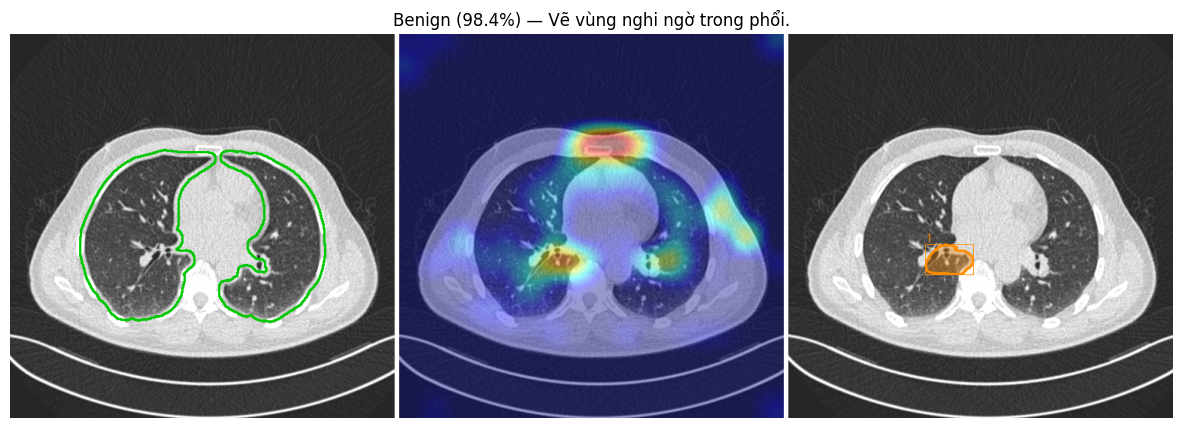

{'nhan': 'Benign', 'diem': 0.9838369488716125, 'scores': {'Benign': 0.9838369488716125, 'Malignant': 2.7269767088000663e-05, 'Normal': 0.016135701909661293}, 've_vung': True, 'ly_do': 'Vẽ vùng nghi ngờ trong phổi.', 'trang_thai_mask': 'OK', 'ti_le_cam_trong_phoi': 0.5017368197441101, 'ti_le_nong_trong_phoi': 0.5155694582681644, 'dinh_cam_trong_phoi': 0.0, 'kich_thuoc_anh': [512, 512], 'lop_gradcam': 'conv5_block3_out', 'nguong': {'tin_cay': 0.8, 'cam': 0.5}, 'canh_bao': 'Vùng đánh dấu là nơi mô hình chú ý nhiều nhất khi đưa ra dự đoán, chỉ mang tính tham khảo; không phải vị trí khối u đã được bác sĩ xác nhận.', 'image_sha256': '925e9ab76b0a7ee5ff91f202de4afe25a5bfa3007cfac7fc292f098542ae4a69'}
Số vùng: 1


In [33]:
def tong_hop_cham_tay(duong_dan_csv):
    d = pd.read_csv(duong_dan_csv)
    d = d[d.danh_gia_tay.fillna("").astype(str).str.strip() != ""].copy()
    if d.empty:
        print("Chưa có dòng nào được chấm."); return None
    d["danh_gia_tay"] = d.danh_gia_tay.astype(str).str.strip().str.upper()
    bang = pd.crosstab(d.nhan_that, d.danh_gia_tay, margins=True, margins_name="Tổng")
    display(bang)
    display((d.danh_gia_tay.value_counts(normalize=True) * 100).round(1).rename("tỉ lệ %"))
    return bang

# Ví dụ sau khi chấm xong:
# tong_hop_cham_tay(thu_muc_cam / f"gradcam_{TAP_DANH_GIA_CAM}_{LOP_GRADCAM}.csv")


def phan_tich_anh_moi(duong_dan, luu_png=None):
    """Dự đoán + vùng nghi ngờ cho một ảnh mới (dùng trong FastAPI). Trả (kết quả JSON, ảnh panel)."""
    duong_dan = Path(duong_dan)
    image = cnn_image(duong_dan)[None, ...]
    cls = vit_batch([duong_dan]); release_vit()
    cams, probs, _ = GRADCAM_CHINH((image, cls))
    kq, panel = xu_ly_ket_qua(np.array(rgb_image(duong_dan)), cams[0], probs[0], GRADCAM_CHINH.ten_lop)
    kq["canh_bao"] = CANH_BAO
    kq["image_sha256"] = sha256_file(duong_dan)
    if luu_png is not None:
        Image.fromarray(panel).save(luu_png)
    return kq, panel

kq_moi, panel_moi = phan_tich_anh_moi(NEW_IMAGE_PATH, thu_muc_cam / "vi_du_anh_moi.png")
write_json(thu_muc_cam / "vi_du_anh_moi.json", kq_moi)
plt.figure(figsize=(15, 5)); plt.imshow(panel_moi); plt.axis("off")
plt.title(f"{kq_moi['nhan']} ({kq_moi['diem']:.1%}) — {kq_moi['ly_do']}"); plt.show()
print({k: v for k, v in kq_moi.items() if k != "vung"})
print("Số vùng:", len(kq_moi["vung"]))

## 25. Phân tích quá trình huấn luyện
Đọc `history.json` của từng mô hình: epoch tốt nhất, epoch val loss thấp nhất và khoảng cách train–val. Epoch tốt nhất ở giữa và sau đó không cải thiện là dấu hiệu đã đủ epoch.

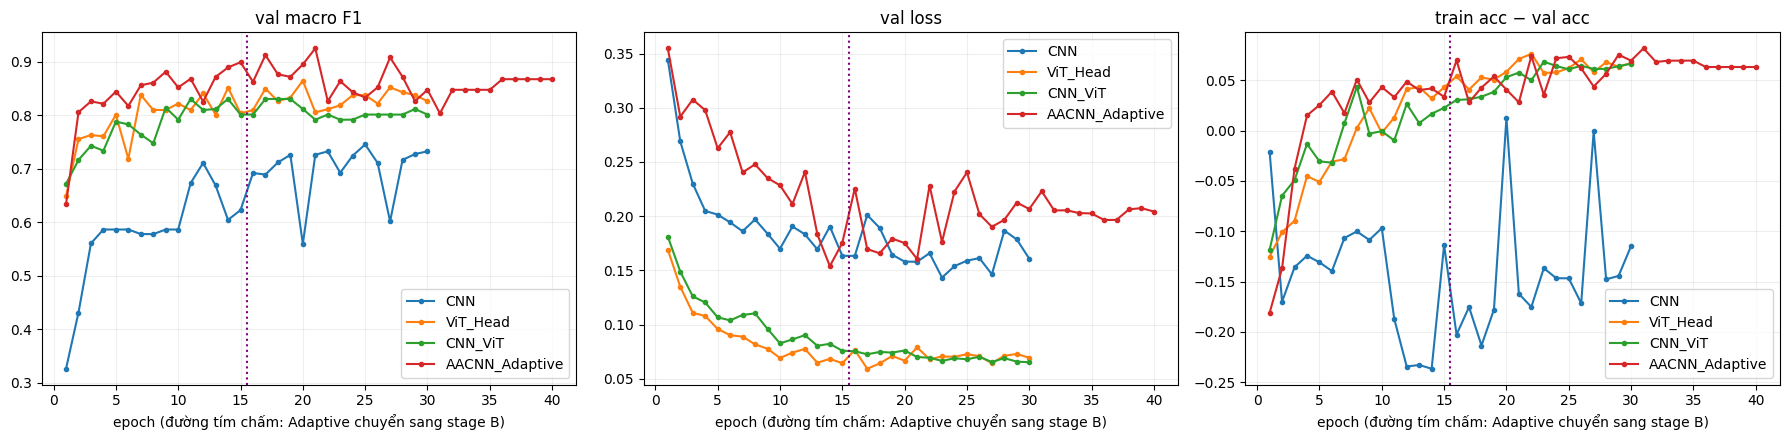

,mo_hinh,so_epoch,epoch_tot_nhat,val_macro_F1_tot_nhat,val_macro_F1_tot_nhat_<=15,epoch_val_loss_thap_nhat,train_acc_tai_best,val_acc_tai_best,khoang_cach_train_val,phut_huan_luyen
0,CNN,30,25,0.7454,0.7108,23,0.6823,0.8291,-0.1468,22.2
1,ViT_Head,30,20,0.8645,0.8514,17,0.9826,0.9241,0.0585,0.9
2,CNN_ViT,30,11,0.8303,0.8303,30,0.9017,0.9114,-0.0097,22.2
3,AACNN_Adaptive,40,21,0.9249,0.8990,14,0.9965,0.9684,0.0282,41.1


• CNN: Val macro F1 cao nhất 0.7454 ở epoch 25/30.
• ViT_Head: Val macro F1 cao nhất 0.8645 ở epoch 20/30. 10 epoch sau đó không tốt hơn → mô hình đã bão hòa; checkpoint tốt nhất đã được giữ.
• CNN_ViT: Val macro F1 cao nhất 0.8303 ở epoch 11/30. 19 epoch sau đó không tốt hơn → mô hình đã bão hòa; checkpoint tốt nhất đã được giữ.
• AACNN_Adaptive: Val macro F1 cao nhất 0.9249 ở epoch 21/40. 19 epoch sau đó không tốt hơn → mô hình đã bão hòa; checkpoint tốt nhất đã được giữ. Val loss thấp nhất ở epoch 14 rồi tăng lại → dấu hiệu overfit về cuối. (Stage B bắt đầu ở epoch 16.)


In [34]:
RUN_DIR_PHAN_TICH = RUN_DIR   # có thể trỏ tới thư mục run khác: Path(".../ket_qua_thuc_nghiem/<RUN_ID>_EXPERIMENT")
MOC_THAM_KHAO = 15            # một mốc epoch để tham khảo trong bảng


def phan_tich_huan_luyen(run_dir=RUN_DIR_PHAN_TICH):
    """Đọc history.json của từng mô hình: epoch tốt nhất, đường học còn đi lên hay đã bão hòa, dấu hiệu overfit."""
    dong = []
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for name in MODELS_TO_RUN:
        p = Path(run_dir) / name / "history.json"
        if not p.exists():
            print("Thiếu", p); continue
        h = json.loads(p.read_text(encoding="utf-8"))
        f1 = np.array([r.get("val_macro_f1", np.nan) for r in h], float)
        vl = np.array([r.get("val_loss", np.nan) for r in h], float)
        acc = np.array([r.get("accuracy", np.nan) for r in h], float)
        vacc = np.array([r.get("val_accuracy", np.nan) for r in h], float)
        n = len(h)
        best = int(np.nanargmax(f1)) + 1
        f1_best = float(np.nanmax(f1))
        vl_min = int(np.nanargmin(vl)) + 1
        gap = float(acc[best - 1] - vacc[best - 1])
        tp = Path(run_dir) / name / "training.json"
        d = {"mo_hinh": name, "so_epoch": n, "epoch_tot_nhat": best,
             "val_macro_F1_tot_nhat": round(f1_best, 4),
             f"val_macro_F1_tot_nhat_<={MOC_THAM_KHAO}": round(float(np.nanmax(f1[:MOC_THAM_KHAO])), 4),
             "epoch_val_loss_thap_nhat": vl_min,
             "train_acc_tai_best": round(float(acc[best - 1]), 4), "val_acc_tai_best": round(float(vacc[best - 1]), 4),
             "khoang_cach_train_val": round(gap, 4),
             "phut_huan_luyen": round(json.loads(tp.read_text(encoding="utf-8")).get("wall_seconds", np.nan) / 60, 1)
                                if tp.exists() else np.nan}

        nx = [f"Val macro F1 cao nhất {f1_best:.4f} ở epoch {best}/{n}."]
        if best >= n - 2:
            nx.append("Epoch tốt nhất nằm sát cuối → đường học vẫn còn đi lên, chạy thêm có thể cải thiện.")
        elif n - best >= 10:
            nx.append(f"{n - best} epoch sau đó không tốt hơn → mô hình đã bão hòa; checkpoint tốt nhất đã được giữ.")
        if vl_min <= n - 10 and vl[-1] > 1.2 * np.nanmin(vl):
            nx.append(f"Val loss thấp nhất ở epoch {vl_min} rồi tăng lại → dấu hiệu overfit về cuối.")
        if gap > 0.10:
            nx.append("Train accuracy cao hơn val > 10 điểm tại epoch tốt nhất → có dấu hiệu overfit.")
        if name == "AACNN_Adaptive":
            nx.append(f"(Stage B bắt đầu ở epoch {EPOCHS_STAGE_A + 1}.)")
        d["nhan_xet"] = " ".join(nx)
        dong.append(d)

        x = np.arange(1, n + 1)
        axes[0].plot(x, f1, marker=".", label=name)
        axes[1].plot(x, vl, marker=".", label=name)
        axes[2].plot(x, acc - vacc, marker=".", label=name)
    for ax, ten in zip(axes, ["val macro F1", "val loss", "train acc − val acc"]):
        ax.axvline(EPOCHS_STAGE_A + 0.5, ls=":", c="purple")   # Adaptive chuyển sang stage B
        ax.set_title(ten); ax.set_xlabel("epoch (đường tím chấm: Adaptive chuyển sang stage B)")
        ax.grid(alpha=0.2); ax.legend()
    fig.tight_layout(); fig.savefig(THU_MUC_BO_SUNG / "phan_tich_huan_luyen.png", dpi=160)
    plt.show(); plt.close(fig)
    bang = pd.DataFrame(dong)
    bang.to_csv(THU_MUC_BO_SUNG / "phan_tich_huan_luyen.csv", index=False, encoding="utf-8-sig")
    return bang


bang_huan_luyen = phan_tich_huan_luyen()
display(bang_huan_luyen.drop(columns="nhan_xet"))
for _, d in bang_huan_luyen.iterrows():
    print(f"• {d.mo_hinh}: {d.nhan_xet}")


## 26. Phân tích mất cân bằng
Số ảnh từng lớp ở mỗi tập và recall từng lớp của bốn mô hình. Accuracy cao nhưng recall Benign thấp là dấu hiệu mất cân bằng ảnh hưởng kết quả.

,Benign,Malignant,Normal,tổng,% Benign,% Malignant,% Normal,lớn/nhỏ
train (ảnh gốc),71,383,283,737,9.6,52.0,38.4,5.39
train (sau augmentation),766,766,766,2298,33.3,33.3,33.3,1.00
validation,15,82,61,158,9.5,51.9,38.6,5.47
test,16,82,61,159,10.1,51.6,38.4,5.12


Lớp ít mẫu nhất: Benign. Class weight đang dùng: {'Benign': 1.0, 'Malignant': 1.0, 'Normal': 1.0}


,mo_hinh,tap,accuracy,macro_F1,balanced_accuracy,recall_Benign,recall_Malignant,recall_Normal,accuracy − recall_Benign
0,CNN,validation,0.8291,0.7454,0.8092,0.8000,0.9390,0.6885,0.0291
1,ViT_Head,validation,0.9241,0.8645,0.8870,0.8000,0.9756,0.8852,0.1241
2,CNN_ViT,validation,0.9114,0.8303,0.8271,0.6000,0.9634,0.9180,0.3114
3,AACNN_Adaptive,validation,0.9684,0.9249,0.9056,0.7333,1.0000,0.9836,0.2350
4,AACNN_Adaptive,test,0.9748,0.9448,0.9320,0.8125,1.0000,0.9836,0.1623


• CNN_ViT (validation): accuracy 91.1% nhưng recall Benign chỉ 60.0% → mất cân bằng ảnh hưởng rõ; accuracy che lỗi ở lớp ít mẫu.
• AACNN_Adaptive (validation): accuracy 96.8% nhưng recall Benign chỉ 73.3% → mất cân bằng ảnh hưởng rõ; accuracy che lỗi ở lớp ít mẫu.


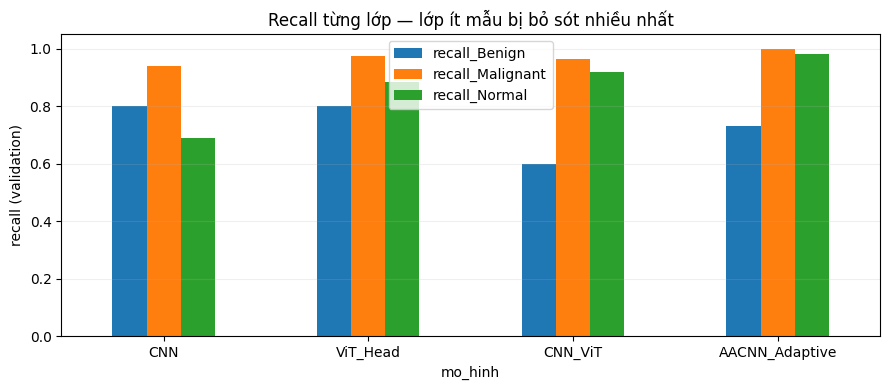

In [35]:
def dem_lop(rows):
    return {c: sum(r["class_name"] == c for r in rows) for c in CLASS_NAMES}

bang_phan_bo = pd.DataFrame({"train (ảnh gốc)": dem_lop(original_train_rows),
                             "train (sau augmentation)": dem_lop(train_rows),
                             "validation": dem_lop(val_rows), "test": dem_lop(test_rows)}).T
bang_phan_bo["tổng"] = bang_phan_bo.sum(1)
for c in CLASS_NAMES:
    bang_phan_bo[f"% {c}"] = (100 * bang_phan_bo[c] / bang_phan_bo["tổng"]).round(1)
bang_phan_bo["lớn/nhỏ"] = (bang_phan_bo[CLASS_NAMES].max(1) / bang_phan_bo[CLASS_NAMES].min(1)).round(2)
display(bang_phan_bo)
lop_it_nhat = min(CLASS_NAMES, key=lambda c: bang_phan_bo.loc["train (ảnh gốc)", c])
print(f"Lớp ít mẫu nhất: {lop_it_nhat}. Class weight đang dùng:",
      {CLASS_NAMES[int(k)]: round(v, 3) for k, v in class_weights.items()})
bang_phan_bo.to_csv(THU_MUC_BO_SUNG / "phan_bo_lop.csv", encoding="utf-8-sig")

thu_muc_run = Path(globals().get("RUN_DIR_PHAN_TICH", RUN_DIR))
dong = []
for name in MODELS_TO_RUN:
    for tap in ("validation", "test"):
        p = thu_muc_run / name / f"{tap}_metrics.json"
        if not p.exists():
            continue
        rep = json.loads(p.read_text(encoding="utf-8"))
        d = {"mo_hinh": name, "tap": tap, "accuracy": rep["accuracy"],
             "macro_F1": rep["macro avg"]["f1-score"],
             "balanced_accuracy": rep["macro avg"]["recall"]}   # balanced accuracy = trung bình recall các lớp
        for c in CLASS_NAMES:
            d[f"recall_{c}"] = rep[c]["recall"]
        d[f"accuracy − recall_{lop_it_nhat}"] = d["accuracy"] - d[f"recall_{lop_it_nhat}"]
        dong.append(d)
bang_anh_huong = pd.DataFrame(dong).round(4)
bang_anh_huong.to_csv(THU_MUC_BO_SUNG / "anh_huong_mat_can_bang_run_hien_tai.csv", index=False, encoding="utf-8-sig")
display(bang_anh_huong)

for _, d in bang_anh_huong.iterrows():
    gap = d[f"accuracy − recall_{lop_it_nhat}"]
    if gap > 0.2:
        print(f"• {d.mo_hinh} ({d.tap}): accuracy {d.accuracy:.1%} nhưng recall {lop_it_nhat} chỉ "
              f"{d[f'recall_{lop_it_nhat}']:.1%} → mất cân bằng ảnh hưởng rõ; accuracy che lỗi ở lớp ít mẫu.")

val = bang_anh_huong[bang_anh_huong.tap == "validation"].set_index("mo_hinh")
if not val.empty:
    ax = val[[f"recall_{c}" for c in CLASS_NAMES]].plot.bar(figsize=(9, 4), rot=0)
    ax.set(ylim=(0, 1.05), ylabel="recall (validation)", title="Recall từng lớp — lớp ít mẫu bị bỏ sót nhiều nhất")
    ax.grid(axis="y", alpha=0.2); plt.tight_layout()
    plt.savefig(THU_MUC_BO_SUNG / "recall_tung_lop.png", dpi=160); plt.show()

## 27. Thực nghiệm xử lý mất cân bằng
So không xử lý, class weight và oversampling trên 737 ảnh gốc lệch lớp với tăng cường cân bằng (mục 5), cùng kiến trúc và số epoch. Bật bằng `CHAY_TN_CAN_BANG = True`.


##### TN cân bằng — 1_goc_khong_xu_ly — AACNN_Adaptive — seed 42 #####
Đã có kết quả, bỏ qua: 1_goc_khong_xu_ly_AACNN_Adaptive_seed42

##### TN cân bằng — 2_goc_class_weight — AACNN_Adaptive — seed 42 #####
Đã có kết quả, bỏ qua: 2_goc_class_weight_AACNN_Adaptive_seed42

##### TN cân bằng — 3_goc_oversampling — AACNN_Adaptive — seed 42 #####
Đã có kết quả, bỏ qua: 3_goc_oversampling_AACNN_Adaptive_seed42

##### TN cân bằng — 4_tang_cuong_can_bang — AACNN_Adaptive — seed 42 #####
Đã có kết quả, bỏ qua: 4_tang_cuong_can_bang_AACNN_Adaptive_seed42

##### TN cân bằng — 1_goc_khong_xu_ly — AACNN_Adaptive — seed 7 #####
Đã có kết quả, bỏ qua: 1_goc_khong_xu_ly_AACNN_Adaptive_seed7

##### TN cân bằng — 2_goc_class_weight — AACNN_Adaptive — seed 7 #####
Đã có kết quả, bỏ qua: 2_goc_class_weight_AACNN_Adaptive_seed7

##### TN cân bằng — 3_goc_oversampling — AACNN_Adaptive — seed 7 #####
Đã có kết quả, bỏ qua: 3_goc_oversampling_AACNN_Adaptive_seed7

##### TN cân bằng — 4_tang_cuong_can_bang — 

,cau_hinh,mo_hinh,seed,epoch_tot_nhat,accuracy,balanced_accuracy,macro_f1,recall_Benign,recall_Malignant,recall_Normal
0,1_goc_khong_xu_ly,AACNN_Adaptive,42,36,0.9620,0.8834,0.9072,0.6667,1.0000,0.9836
1,2_goc_class_weight,AACNN_Adaptive,42,36,0.9810,0.9501,0.9574,0.8667,1.0000,0.9836
2,3_goc_oversampling,AACNN_Adaptive,42,15,0.9367,0.8811,0.8801,0.7333,0.9756,0.9344
3,4_tang_cuong_can_bang,AACNN_Adaptive,42,25,0.9557,0.8794,0.9027,0.6667,0.9878,0.9836
4,1_goc_khong_xu_ly,AACNN_Adaptive,7,32,0.9747,0.9111,0.9381,0.7333,1.0000,1.0000
5,2_goc_class_weight,AACNN_Adaptive,7,40,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,3_goc_oversampling,AACNN_Adaptive,7,19,0.9430,0.8698,0.8858,0.6667,0.9756,0.9672
7,4_tang_cuong_can_bang,AACNN_Adaptive,7,32,0.9684,0.9056,0.9249,0.7333,1.0000,0.9836


Trung bình ± độ lệch chuẩn giữa các seed:


accuracy         balanced_accuracy  \
                                         mean     std              mean   
mo_hinh        cau_hinh                                                   
AACNN_Adaptive 1_goc_khong_xu_ly       0.9684  0.0090            0.8973   
               2_goc_class_weight      0.9905  0.0134            0.9750   
               3_goc_oversampling      0.9399  0.0045            0.8755   
               4_tang_cuong_can_bang   0.9620  0.0090            0.8925   

                                             macro_f1         recall_Benign  \
                                         std     mean     std          mean   
mo_hinh        cau_hinh                                                       
AACNN_Adaptive 1_goc_khong_xu_ly      0.0196   0.9227  0.0219        0.7000   
               2_goc_class_weight     0.0353   0.9787  0.0301        0.9333   
               3_goc_oversampling     0.0080   0.8830  0.0041        0.7000   
               4_tang_cuong_can_bang  0.0186   0.9138  0.0158        0.7000   

                                             recall_Malignant          \
                                         std             mean     std   
mo_hinh        cau_hinh                                                 
AACNN_Adaptive 1_goc_khong_xu_ly      0.0471           1.0000  0.0000   
               2_goc_class_weight     0.0943           1.0000  0.0000   
               3_goc_oversampling     0.0471           0.9756  0.0000   
               4_tang_cuong_can_bang  0.0471           0.9939  0.0086   

                                     recall_Normal          
                                              mean     std  
mo_hinh        cau_hinh                                     
AACNN_Adaptive 1_goc_khong_xu_ly            0.9918  0.0116  
               2_goc_class_weight           0.9918  0.0116  
               3_goc_oversampling           0.9508  0.0232  
               4_tang_cuong_can_bang        0.9836  0.0000


AACNN_Adaptive — chênh lệch so với đối chứng '1_goc_khong_xu_ly' (trung bình các seed):


,accuracy,balanced_accuracy,macro_f1,recall_Benign,recall_Malignant,recall_Normal
cau_hinh,,,,,,
2_goc_class_weight,0.0222,0.0778,0.0560,0.2333,0.0000,0.0000
3_goc_oversampling,-0.0285,-0.0218,-0.0397,0.0000,-0.0244,-0.0410
4_tang_cuong_can_bang,-0.0063,-0.0048,-0.0089,0.0000,-0.0061,-0.0082


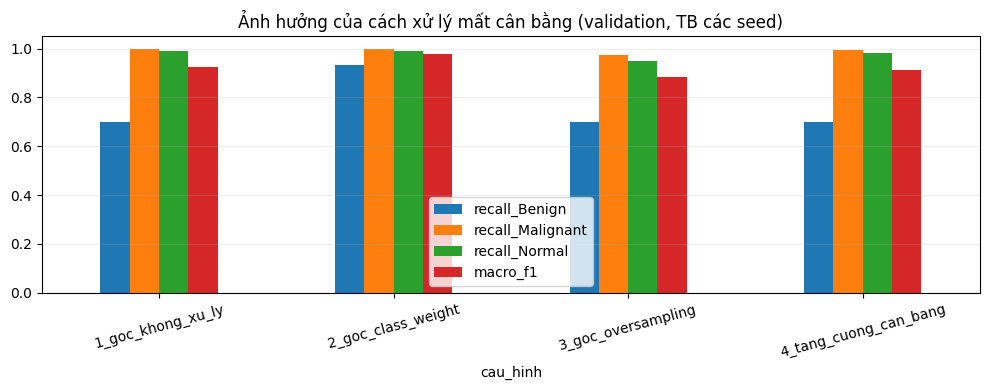

In [43]:
CHAY_TN_CAN_BANG = True              # đổi thành True để chạy
TN_CB_MO_HINH = ["AACNN_Adaptive"]
TN_CB_SEEDS = [42, 7]           # thiếu thời gian: [42] trước
TN_CB_EPOCH_BASELINE = EPOCHS_BASELINE
TN_CB_EPOCH_A, TN_CB_EPOCH_B = EPOCHS_STAGE_A, EPOCHS_STAGE_B
CAU_HINH_CAN_BANG = {
    "1_goc_khong_xu_ly":     dict(du_lieu="goc",        loss="ce",     dung_class_weight=False, oversample=False),
    "2_goc_class_weight":    dict(du_lieu="goc",        loss="ce",     dung_class_weight=True,  oversample=False),
    "3_goc_oversampling":    dict(du_lieu="goc",        loss="ce",     dung_class_weight=False, oversample=True),
    "4_tang_cuong_can_bang": dict(du_lieu="tang_cuong", loss="ce",     dung_class_weight=False, oversample=False),
    # "5_cau_hinh_chinh":    dict(du_lieu="tang_cuong", loss="hybrid", dung_class_weight=False, oversample=False),
}
# Tập train gốc = phần đầu của train_rows (mục 5 giữ ảnh gốc ở đầu, ảnh tăng cường nối phía sau)
N_GOC = len(original_train_rows)
assert [r["sha256"] for r in train_rows[:N_GOC]] == [r["sha256"] for r in original_train_rows]
DU_LIEU_TN = {"goc": (train_rows[:N_GOC], {"train": features["train"][:N_GOC], "validation": features["validation"]}),
              "tang_cuong": (train_rows, features)}
thu_muc_tn_cb = THU_MUC_BO_SUNG / "TN_can_bang"

if CHAY_TN_CAN_BANG:
    ket_qua_tn_cb = []
    for seed in TN_CB_SEEDS:
        for name in TN_CB_MO_HINH:
            for ten_ch, ch in CAU_HINH_CAN_BANG.items():
                print(f"\n##### TN cân bằng — {ten_ch} — {name} — seed {seed} #####")
                ch = dict(ch); rows_tn, feats_tn = DU_LIEU_TN[ch.pop("du_lieu")]
                kq = chay_voi_du_lieu(rows_tn, val_rows, feats_tn, huan_luyen_thu_nghiem,
                                      name, thu_muc_tn_cb / f"{ten_ch}_{name}_seed{seed}", seed=seed,
                                      epochs_baseline=TN_CB_EPOCH_BASELINE, epochs_a=TN_CB_EPOCH_A,
                                      epochs_b=TN_CB_EPOCH_B, **ch)
                kq["cau_hinh"] = ten_ch
                ket_qua_tn_cb.append(kq)
else:
    ket_qua_tn_cb = []
    for p in sorted(thu_muc_tn_cb.glob("*/ket_qua.json")):
        kq = json.loads(p.read_text(encoding="utf-8"))
        kq["cau_hinh"] = p.parent.name.split(f"_{kq['mo_hinh']}_")[0]
        ket_qua_tn_cb.append(kq)
    print("CHAY_TN_CAN_BANG=False — chỉ đọc kết quả đã có:", len(ket_qua_tn_cb), "lần chạy.")

if ket_qua_tn_cb:
    cot_chi_so = ["accuracy", "balanced_accuracy", "macro_f1"] + [f"recall_{c}" for c in CLASS_NAMES]
    bang = pd.DataFrame([{"cau_hinh": kq["cau_hinh"], "mo_hinh": kq["mo_hinh"], "seed": kq["seed"],
                          "epoch_tot_nhat": kq["epoch_tot_nhat"],
                          **{c: kq["validation"][c] for c in cot_chi_so}} for kq in ket_qua_tn_cb])
    bang.to_csv(THU_MUC_BO_SUNG / "TN_can_bang_chi_tiet.csv", index=False, encoding="utf-8-sig")
    display(bang.round(4))
    tong = bang.groupby(["mo_hinh", "cau_hinh"])[cot_chi_so].agg(["mean", "std"]).round(4)
    tong.to_csv(THU_MUC_BO_SUNG / "TN_can_bang_tong_hop.csv", encoding="utf-8-sig")
    print("Trung bình ± độ lệch chuẩn giữa các seed:"); display(tong)
    for name, g in bang.groupby("mo_hinh"):
        tb = g.groupby("cau_hinh")[cot_chi_so].mean()
        if "1_goc_khong_xu_ly" not in tb.index:
            continue
        goc = tb.loc["1_goc_khong_xu_ly"]
        print(f"\n{name} — chênh lệch so với đối chứng '1_goc_khong_xu_ly' (trung bình các seed):")
        display((tb - goc).drop(index="1_goc_khong_xu_ly").round(4))
    ve = bang.groupby("cau_hinh")[[f"recall_{c}" for c in CLASS_NAMES] + ["macro_f1"]].mean()
    ax = ve.plot.bar(figsize=(10, 4), rot=15)
    ax.set(ylim=(0, 1.05), title="Ảnh hưởng của cách xử lý mất cân bằng (validation, TB các seed)")
    ax.grid(axis="y", alpha=0.2); plt.tight_layout()
    plt.savefig(THU_MUC_BO_SUNG / "TN_can_bang.png", dpi=160); plt.show()

## 28. Thử ảnh tải lên: dự đoán và khung vùng nghi ngờ
Dùng đúng quy trình mục 24; tích "Hiện 3 khung chi tiết" để xem thêm mask phổi và Grad-CAM thô. Sau mục 29 (hoặc ở chế độ `thu_anh`), nút dùng mô hình lung crop nếu `NUT_THU_DUNG_LUNG_CROP = True`.

In [37]:
# [THU_ANH] cell này cũng chạy ở chế độ thử ảnh
import io
import ipywidgets as widgets
from IPython.display import display, clear_output

if "GRADCAM_CHINH" not in globals():
    _mo_hinh = model_cam if "model_cam" in globals() else selected_model
    GRADCAM_CHINH = GradCAMVungDo(_mo_hinh, LOP_GRADCAM, DUNG_LOGIT)


def du_doan_vung_do_tu_bytes(content, original_name, xem_chi_tiet=False):
    raw = bytes(content)
    if len(raw) > 20 * 1024 * 1024:
        raise ValueError("Ảnh vượt 20 MiB.")
    with Image.open(io.BytesIO(raw)) as probe:
        if probe.format not in {"JPEG", "PNG"}:
            raise ValueError("Chỉ nhận JPEG/PNG.")
        probe.verify()
    image_hash = hashlib.sha256(raw).hexdigest()
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    dest = RUN_DIR / "uploaded_vung_do" / f"{stamp}_{image_hash[:12]}"
    dest.mkdir(parents=True, exist_ok=False)
    image_path = dest / ("input_original" + (".png" if raw.startswith(b"\x89PNG") else ".jpg"))
    image_path.write_bytes(raw)

    kq, panel = phan_tich_anh_moi(image_path, luu_png=dest / "chi_tiet_3_khung.png")
    kq["original_filename"] = Path(original_name).name
    write_json(dest / "result.json", kq)
    w = kq["kich_thuoc_anh"][0]
    anh_ket_qua = np.ascontiguousarray(panel[:, 2 * (w + 6):])   # khung thứ 3: vùng nghi ngờ sau lọc
    Image.fromarray(anh_ket_qua).save(dest / "ket_qua_vung_do.png")

    fig, axes = plt.subplots(1, 2, figsize=(13, 6.8))
    axes[0].imshow(rgb_image(image_path)); axes[0].set_title("Ảnh CT gốc")
    axes[1].imshow(anh_ket_qua)
    axes[1].set_title(f"Dự đoán: {kq['nhan']} ({kq['diem']:.1%}) — {len(kq['vung'])} vùng nghi ngờ")
    for ax in axes:
        ax.axis("off")
    fig.text(0.5, 0.04, kq["ly_do"] + "\n" + CANH_BAO + "\nĐỏ: nghi ác tính · Cam: nghi lành tính",
             ha="center", fontsize=9, wrap=True)
    fig.tight_layout(rect=(0, 0.1, 1, 1)); plt.show(); plt.close(fig)
    if xem_chi_tiet:
        fig, ax = plt.subplots(figsize=(15, 5)); ax.imshow(panel); ax.axis("off")
        ax.set_title("Chi tiết: [gốc + viền phổi] | [Grad-CAM thô] | [vùng sau lọc]   "
                     f"— vùng nóng trong phổi: {kq['ti_le_nong_trong_phoi']:.0%}")
        plt.show(); plt.close(fig)
    for ten, diem in kq["scores"].items():
        print(f"  {ten}: {diem:.4f}")
    for k, v in enumerate(kq["vung"], 1):
        print(f"  Vùng {k}: khung x={v['x']}, y={v['y']}, w={v['w']}, h={v['h']} | Grad-CAM max {v['cam_max']:.2f}")
    print("Đã lưu:", dest)
    return kq, dest


upload_vd = widgets.FileUpload(accept=".png,.jpg,.jpeg", multiple=True, description="Chọn ảnh CT")
nut_vd = widgets.Button(description="Dự đoán + khung vùng đỏ", button_style="danger",
                        layout=widgets.Layout(width="260px"))
chi_tiet_vd = widgets.Checkbox(value=True, description="Hiện 3 khung chi tiết (Grad-CAM thô, mask phổi)")
out_vd = widgets.Output()


def khi_bam_vd(_):
    with out_vd:
        clear_output(wait=True)
        if not upload_vd.value:
            print("Chọn ít nhất một ảnh trước."); return
        nut_vd.disabled = True
        try:
            items = upload_vd.value.values() if isinstance(upload_vd.value, dict) else upload_vd.value
            for item in items:
                ten = item.get("name", item.get("metadata", {}).get("name", "image.png"))
                print("=====", ten, "=====")
                try:
                    du_doan_vung_do_tu_bytes(item["content"], ten, chi_tiet_vd.value)
                except Exception as error:
                    print("Không xử lý được ảnh", ten, ":", repr(error))
        finally:
            nut_vd.disabled = False


nut_vd.on_click(khi_bam_vd)
display(widgets.VBox([upload_vd, chi_tiet_vd, nut_vd, out_vd]))

## 29. Thực nghiệm lung crop
Che phần ngoài phổi rồi huấn luyện lại Adaptive để buộc mô hình chú ý vào nhu mô phổi; so phân loại và tỉ lệ vẽ khung với mô hình chính trên validation.

train: 2298 ảnh crop | mask lỗi (giữ nguyên ảnh gốc): 2 (0.1%)
validation: 158 ảnh crop | mask lỗi (giữ nguyên ảnh gốc): 0 (0.0%)
Trích đặc trưng ViT cho ảnh crop (lần đầu vài phút đến ~20 phút nếu chạy CPU; lần sau dùng cache)...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{'train': (2298, 768), 'validation': (158, 768)}


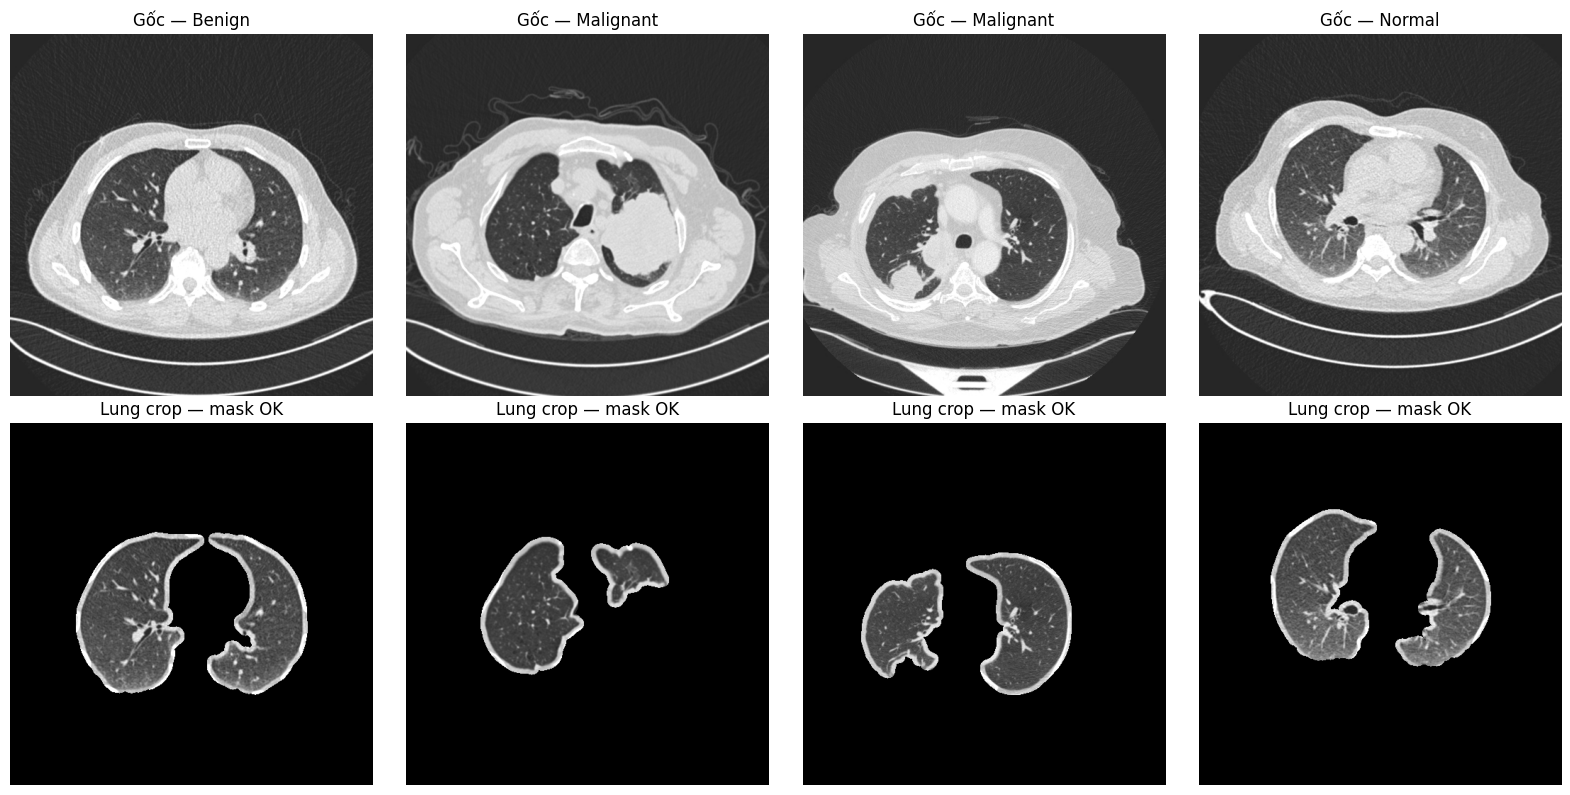

In [38]:
# ===== 29.1 Lung crop: tạo ảnh đã che phần ngoài phổi + trích đặc trưng ViT =====
CHAY_TN_LUNG_CROP = True      # False = bỏ qua toàn bộ mục 29
TN_CROP_SEEDS = [42]          # cùng seed với run chính để so sánh; có thời gian thì thêm [42, 7, 2024]
VIT_DUNG_GPU = True           # trích ViT bằng GPU cho nhanh; nếu thiếu bộ nhớ sẽ tự chuyển CPU
thu_muc_crop = THU_MUC_BO_SUNG / "TN_lung_crop"
thu_muc_anh_crop = thu_muc_crop / "anh_crop"


def che_ngoai_phoi(rgb):
    """Tô đen mọi pixel ngoài mask phổi (mask giống mục 24). Mask lỗi → giữ nguyên ảnh và báo trạng thái."""
    rgb = np.array(rgb, dtype=np.uint8, copy=True)
    mask, trang_thai = tao_mask_phoi(rgb)
    if mask is None:
        return rgb, trang_thai
    rgb[~mask] = 0
    return rgb, trang_thai


def tao_rows_crop(rows, ten_tap):
    """Lưu ảnh crop (PNG, không nén mất dữ liệu) và trả manifest mới trỏ tới ảnh crop.
    Chạy lại sẽ dùng ảnh đã có, không tạo lại."""
    out_dir = thu_muc_anh_crop / ten_tap
    out_dir.mkdir(parents=True, exist_ok=True)
    tt_path = out_dir / "trang_thai_mask.json"
    trang_thai = json.loads(tt_path.read_text(encoding="utf-8")) if tt_path.exists() else {}
    moi = []
    for r in rows:
        goc = BASE_DIR / r["relative_path"]
        dich = out_dir / f"{r['sha256']}.png"
        if not dich.exists() or r["sha256"] not in trang_thai:
            anh, tt = che_ngoai_phoi(np.array(rgb_image(goc)))
            Image.fromarray(anh).save(dich)
            trang_thai[r["sha256"]] = tt
        moi.append({**r, "relative_path": str(dich.resolve()), "sha256": sha256_file(dich),
                    "anh_goc": str(goc), "mask_status": trang_thai[r["sha256"]]})
    write_json(tt_path, trang_thai)
    loi = sum(r["mask_status"] != "OK" for r in moi)
    print(f"{ten_tap}: {len(moi)} ảnh crop | mask lỗi (giữ nguyên ảnh gốc): {loi} ({100 * loi / max(len(moi), 1):.1f}%)")
    return moi


def trich_dac_trung_crop(rows):
    """CLS ViT của chính ảnh crop (ViT cũng chỉ thấy phần phổi)."""
    global DEVICE
    try:
        if VIT_DUNG_GPU and torch.cuda.is_available():
            DEVICE = "cuda"
            try:
                return extract_features(rows)
            except RuntimeError as error:
                print("GPU không đủ bộ nhớ cho ViT, chuyển sang CPU:", str(error)[:150])
                release_vit()
        DEVICE = "cpu"
        return extract_features(rows)
    finally:
        release_vit()
        DEVICE = "cpu"


if CHAY_TN_LUNG_CROP:
    train_crop = tao_rows_crop(train_rows, "train")
    val_crop = tao_rows_crop(val_rows, "validation")
    print("Trích đặc trưng ViT cho ảnh crop (lần đầu vài phút đến ~20 phút nếu chạy CPU; lần sau dùng cache)...")
    feats_crop = {"train": trich_dac_trung_crop(train_crop),
                  "validation": trich_dac_trung_crop(val_crop)}
    print({k: v.shape for k, v in feats_crop.items()})

    # Xem thử 4 ảnh validation: gốc và sau khi che
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for j, r in enumerate(val_crop[:: max(1, len(val_crop) // 4)][:4]):
        axes[0, j].imshow(rgb_image(r["anh_goc"])); axes[0, j].set_title(f"Gốc — {r['class_name']}")
        axes[1, j].imshow(rgb_image(r["relative_path"])); axes[1, j].set_title(f"Lung crop — mask {r['mask_status']}")
    for ax in axes.ravel():
        ax.axis("off")
    fig.tight_layout(); fig.savefig(thu_muc_crop / "vi_du_lung_crop.png", dpi=120); plt.show(); plt.close(fig)
else:
    print("CHAY_TN_LUNG_CROP=False — bỏ qua mục 29.")

In [39]:
# ===== 29.2 Huấn luyện Adaptive trên ảnh lung crop + so sánh phân loại với mô hình gốc =====
if CHAY_TN_LUNG_CROP:
    ket_qua_crop = {}
    for seed in TN_CROP_SEEDS:
        print(f"\n##### Lung crop — AACNN_Adaptive — seed {seed} #####")
        ket_qua_crop[seed] = chay_voi_du_lieu(
            train_crop, val_crop, feats_crop, huan_luyen_thu_nghiem,
            "AACNN_Adaptive", thu_muc_crop / f"AACNN_Adaptive_crop_seed{seed}", seed=seed,
            loss="hybrid", dung_class_weight=True, oversample=False,
            xoa_trong_so=False)     # giữ trọng số để chạy Grad-CAM ở 29.3

    # Bảng so sánh với mô hình gốc (ảnh đầy đủ, cùng cấu hình 15 + 25 epoch, seed 42)
    dong = []
    p_goc = Path(globals().get("RUN_DIR_PHAN_TICH", RUN_DIR)) / "AACNN_Adaptive" / "validation_metrics.json"
    if p_goc.exists():
        rep = json.loads(p_goc.read_text(encoding="utf-8"))
        d = {"mô hình": "Gốc (ảnh đầy đủ)", "accuracy": rep["accuracy"],
             "balanced_accuracy": rep["macro avg"]["recall"], "macro_f1": rep["macro avg"]["f1-score"]}
        d.update({f"recall_{c}": rep[c]["recall"] for c in CLASS_NAMES})
        dong.append(d)
    for seed, kq in ket_qua_crop.items():
        v = kq["validation"]
        d = {"mô hình": f"Lung crop (seed {seed})", "accuracy": v["accuracy"],
             "balanced_accuracy": v["balanced_accuracy"], "macro_f1": v["macro_f1"]}
        d.update({f"recall_{c}": v[f"recall_{c}"] for c in CLASS_NAMES})
        dong.append(d)
    bang_crop_phan_loai = pd.DataFrame(dong).set_index("mô hình").round(4)
    bang_crop_phan_loai.to_csv(thu_muc_crop / "so_sanh_phan_loai.csv", encoding="utf-8-sig")
    print("\nSo sánh phân loại trên VALIDATION:")
    display(bang_crop_phan_loai)
    for seed, kq in ket_qua_crop.items():
        print(f"Ma trận nhầm lẫn lung crop seed {seed} (hàng = thật, cột = dự đoán; {CLASS_NAMES}):")
        print(np.array(kq["validation"]["confusion_matrix"]))


##### Lung crop — AACNN_Adaptive — seed 42 #####
Epoch 1/15
 — val_macro_f1=0.6247; best=0.6247
288/288 - 66s - 231ms/step - accuracy: 0.5818 - loss: 0.5222 - val_accuracy: 0.7278 - val_loss: 0.3708 - val_macro_f1: 0.6247 - learning_rate: 2.0000e-04
Epoch 2/15
 — val_macro_f1=0.8439; best=0.8439
288/288 - 55s - 190ms/step - accuracy: 0.7441 - loss: 0.4018 - val_accuracy: 0.9114 - val_loss: 0.3041 - val_macro_f1: 0.8439 - learning_rate: 2.0000e-04
Epoch 3/15
 — val_macro_f1=0.7950; best=0.8439
288/288 - 53s - 183ms/step - accuracy: 0.8346 - loss: 0.3417 - val_accuracy: 0.9177 - val_loss: 0.2792 - val_macro_f1: 0.7950 - learning_rate: 2.0000e-04
Epoch 4/15
 — val_macro_f1=0.8332; best=0.8439
288/288 - 51s - 178ms/step - accuracy: 0.9012 - loss: 0.2977 - val_accuracy: 0.8987 - val_loss: 0.2824 - val_macro_f1: 0.8332 - learning_rate: 2.0000e-04
Epoch 5/15
 — val_macro_f1=0.7428; best=0.8439
288/288 - 52s - 182ms/step - accuracy: 0.9308 - loss: 0.2579 - val_accuracy: 0.8608 - val_loss: 0.3

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 138 variables whereas the saved optimizer has 66 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



So sánh phân loại trên VALIDATION:


,accuracy,balanced_accuracy,macro_f1,recall_Benign,recall_Malignant,recall_Normal
mô hình,,,,,,
Gốc (ảnh đầy đủ),0.9684,0.9056,0.9249,0.7333,1.0000,0.9836
Lung crop (seed 42),0.9367,0.8658,0.8813,0.6667,0.9634,0.9672


Ma trận nhầm lẫn lung crop seed 42 (hàng = thật, cột = dự đoán; ['Benign', 'Malignant', 'Normal']):
[[10  0  5]
 [ 0 79  3]
 [ 2  0 59]]


In [40]:
# ===== 29.3 Grad-CAM của mô hình lung crop + so sánh tỉ lệ có khung với mô hình gốc =====
if CHAY_TN_LUNG_CROP:
    seed_chon = TN_CROP_SEEDS[0]
    model_crop = BUILDERS["AACNN_Adaptive"]()
    model_crop.load_weights(thu_muc_crop / f"AACNN_Adaptive_crop_seed{seed_chon}" / "best.weights.h5")
    GRADCAM_CROP = GradCAMVungDo(model_crop, LOP_GRADCAM, DUNG_LOGIT)
    GRADCAM_CROP.kiem_tra((np.stack([cnn_image(val_crop[0]["relative_path"])]), feats_crop["validation"][:1]))

    def danh_gia_gradcam_crop(gc_, rows_crop, feats, thu_muc_anh=None, batch=8):
        """Đầu vào mô hình: ảnh crop. Mask phổi và hiển thị: ảnh GỐC (để so sánh được với mô hình gốc)."""
        ban_ghi = []
        for bat in range(0, len(rows_crop), batch):
            ids = list(range(bat, min(bat + batch, len(rows_crop))))
            imgs = np.stack([cnn_image(rows_crop[k]["relative_path"]) for k in ids])
            cams, probs, _ = gc_((imgs, feats[ids]))
            for j, k in enumerate(ids):
                r = rows_crop[k]
                kq, panel = xu_ly_ket_qua(np.array(rgb_image(r["anh_goc"])), cams[j], probs[j], gc_.ten_lop)
                ten_anh = f"{k:04d}_that-{r['class_name']}_du-doan-{kq['nhan']}.png"
                if thu_muc_anh is not None:
                    Image.fromarray(panel).save(thu_muc_anh / ten_anh)
                ban_ghi.append({"stt": k, "tep_anh": ten_anh, "relative_path": r["anh_goc"],
                                "nhan_that": r["class_name"], "nhan": kq["nhan"], "diem": kq["diem"],
                                "ve_vung": kq["ve_vung"], "so_vung": len(kq["vung"]), "ly_do": kq["ly_do"],
                                "trang_thai_mask": kq["trang_thai_mask"],
                                "ti_le_cam_trong_phoi": kq["ti_le_cam_trong_phoi"],
                                "ti_le_nong_trong_phoi": kq["ti_le_nong_trong_phoi"],
                                "dinh_cam_trong_phoi": kq["dinh_cam_trong_phoi"],
                                "danh_gia_tay": "", "ghi_chu": ""})
        return pd.DataFrame(ban_ghi)

    thu_muc_cam_crop = thu_muc_crop / "gradcam_validation"
    (thu_muc_cam_crop / "anh").mkdir(parents=True, exist_ok=True)
    df_crop = danh_gia_gradcam_crop(GRADCAM_CROP, val_crop, feats_crop["validation"], thu_muc_cam_crop / "anh")
    df_crop.to_csv(thu_muc_cam_crop / f"gradcam_validation_{LOP_GRADCAM}.csv", index=False, encoding="utf-8-sig")

    df_goc = pd.read_csv(THU_MUC_BO_SUNG / "gradcam_validation" / f"gradcam_validation_{LOP_GRADCAM}.csv")

    def tom_tat_so_sanh(d):
        benh = d[d.nhan != "Normal"]
        v = d[d.ve_vung]
        return pd.Series({
            "Số ảnh dự đoán Benign/Malignant": len(benh),
            "Số ảnh có vẽ vùng": len(v),
            "% ảnh bệnh có vẽ vùng": 100 * len(v) / max(len(benh), 1),
            "TB % Grad-CAM trong phổi (ảnh bệnh)": 100 * benh.ti_le_cam_trong_phoi.mean(),
            "% ảnh bệnh có điểm nóng nhất trong phổi": 100 * benh.dinh_cam_trong_phoi.mean(),
            "Số vùng TB / ảnh có vẽ": v.so_vung.mean(),
            "Số ảnh bị bỏ vì vùng ngoài phổi": int(d.ly_do.str.contains("không nằm trong phổi").sum())})

    bang_crop_cam = pd.DataFrame({"Gốc (ảnh đầy đủ)": tom_tat_so_sanh(df_goc),
                                  f"Lung crop (seed {seed_chon})": tom_tat_so_sanh(df_crop)}).round(2)
    bang_crop_cam.to_csv(thu_muc_crop / "so_sanh_gradcam.csv", encoding="utf-8-sig")
    print("So sánh Grad-CAM trên VALIDATION (cùng bộ lọc mục 24):")
    display(bang_crop_cam)
    print("Theo lớp thật — lung crop:"); display(tong_hop_cam(df_crop))

    # Ví dụ: ảnh mà mô hình gốc KHÔNG vẽ nhưng mô hình lung crop CÓ vẽ
    ss = df_goc[["stt", "tep_anh", "ve_vung"]].merge(df_crop[["stt", "tep_anh", "ve_vung", "nhan_that"]],
                                                    on="stt", suffixes=("_goc", "_crop"))
    moi_co = ss[~ss.ve_vung_goc & ss.ve_vung_crop]
    print(f"Ảnh gốc không vẽ nhưng lung crop có vẽ: {len(moi_co)}")
    for _, d in moi_co.head(6).iterrows():
        a = np.array(Image.open(THU_MUC_BO_SUNG / "gradcam_validation" / "anh" / d.tep_anh_goc))
        b = np.array(Image.open(thu_muc_cam_crop / "anh" / d.tep_anh_crop))
        fig, ax = plt.subplots(2, 1, figsize=(15, 10))
        ax[0].imshow(a); ax[0].set_title("Mô hình GỐC — " + d.tep_anh_goc)
        ax[1].imshow(b); ax[1].set_title("Mô hình LUNG CROP — " + d.tep_anh_crop)
        for x in ax:
            x.axis("off")
        plt.show(); plt.close(fig)
    print("Ảnh PNG và CSV (để chấm tay) của lung crop:", thu_muc_cam_crop)

Output hidden; open in https://colab.research.google.com to view.

In [41]:
# ===== 29.4 Dùng mô hình lung crop cho nút thử ảnh (mục 28) =====
DUNG_MO_HINH_CROP_CHO_NUT_THU = NUT_THU_DUNG_LUNG_CROP   # đặt ở mục 2


def phan_tich_anh_moi_crop(duong_dan, luu_png=None):
    """Như phan_tich_anh_moi nhưng che ngoài phổi trước khi đưa vào mô hình lung crop.
    Mask phổi, khung và ảnh hiển thị vẫn trên ảnh gốc."""
    duong_dan = Path(duong_dan)
    rgb = np.array(rgb_image(duong_dan))
    anh_crop, tt = che_ngoai_phoi(rgb)
    tam = thu_muc_crop / "tam"
    tam.mkdir(parents=True, exist_ok=True)
    p_crop = tam / f"{sha256_file(duong_dan)[:16]}.png"
    Image.fromarray(anh_crop).save(p_crop)
    image = cnn_image(p_crop)[None, ...]
    cls = vit_batch([p_crop]); release_vit()
    cams, probs, _ = GRADCAM_CROP((image, cls))
    kq, panel = xu_ly_ket_qua(rgb, cams[0], probs[0], GRADCAM_CROP.ten_lop)
    kq.update({"canh_bao": CANH_BAO, "image_sha256": sha256_file(duong_dan),
               "mo_hinh": "AACNN_Adaptive_lung_crop", "mask_crop": tt})
    if luu_png is not None:
        Image.fromarray(panel).save(luu_png)
    return kq, panel


if "phan_tich_anh_moi_goc" not in globals():
    phan_tich_anh_moi_goc = phan_tich_anh_moi
if CHAY_TN_LUNG_CROP and DUNG_MO_HINH_CROP_CHO_NUT_THU:
    phan_tich_anh_moi = phan_tich_anh_moi_crop
    print("Nút thử ảnh (mục 28) đang dùng mô hình LUNG CROP.")
else:
    phan_tich_anh_moi = phan_tich_anh_moi_goc
    print("Nút thử ảnh (mục 28) đang dùng mô hình GỐC.")

Nút thử ảnh (mục 28) đang dùng mô hình LUNG CROP.


## 30. Gợi ý ghi vào khóa luận
- **Số epoch:** baseline 30 epoch, Adaptive 15 + 25, không dừng sớm, chọn checkpoint theo macro-F1 validation; nêu epoch tốt nhất từ mục 25.
- **Mất cân bằng:** nêu tỉ lệ lớp (mục 26), recall Benign so với accuracy, và kết quả đối chứng ở mục 27 nếu đã chạy.
- **Vùng nghi ngờ:** nêu tỉ lệ ảnh được vẽ khung, tỉ lệ vùng nóng trong phổi (mục 24) và kết quả chấm tay; kèm ví dụ cả đúng lẫn sai.
- **Hạn chế:** chia theo ảnh, chưa theo bệnh nhân; validation chỉ 15 ảnh Benign; Grad-CAM có độ phân giải thô; mô hình lung crop phân loại kém hơn mô hình chính.